# Multi Modal Data Analysis

## Project: 2.2 – Implementation report & presentation

## Multimodal Movie Genre Classification Using Poster Images and Plot Summaries

Submitted by Tran Huu Hao Nguyen

## Dataset

This project utilizes a simplified version of the MM-IMDb dataset (Simplified MM-IMDb data (Ureña, 2024)) that contains 25,959 movies with corresponding plot summaries (text), 256x160 RGB images and 23-dimensional binary vectors representing movie genres. A single movie can contain more than one genre and hence, the task is to perform multi-label classification.

## Reference

Ureña, J. (2024, December 5). *Simplified MM-IMDb* [Data set]. Kaggle. https://www.kaggle.com/datasets/javierurea/simplified-mm-imdb

### 1. Load files and inspect structure:

This section extracts and loads the movie records and poster images from `archive.zip`, inspects their shapes and data types, and previews sample records. Six randomly selected movies are visualised with their posters, genre labels and plot excerpts to illustrate the dataset.

Current working directory: C:\Users\Lenovo\OneDrive - University of Adelaide\Desktop\SEMESTER 2 2026\Multi-Modal Data Analysis\ASSIGNMENT 5
Dataset archive: C:\Users\Lenovo\OneDrive - University of Adelaide\Desktop\SEMESTER 2 2026\Multi-Modal Data Analysis\ASSIGNMENT 5\archive.zip

Files inside archive.zip:
 - data.npy
 - images.npz
Using existing file: data.npy
Using existing file: images.npz

Loading poster images ...
Arrays in images.npz: ['images']
Dataset loaded successfully.

DATASET STRUCTURE


,Array,Shape,Dimensions,Data type,Number of entries
0,records,"(25959, 3)",2,object,25959
1,images,"(25959, 3, 256, 160)",4,uint8,25959


Fields per movie record: 3
Poster shape (channels, height, width): (3, 256, 160)

FIRST MOVIE RECORD
Movie ID: 0
Genre-label vector: [1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
Number of genre labels: 23
Number of assigned genres: 4

Plot summary:
sardonic detective shane , thrown out of one town for bringing trouble , heads for home and his ex - partner ' s detective agency . the business is in a sad way , and shane , who has had the forethought to provide himself with a N - dollar commission from an old lady on the train , is welcomed with open arms . when pretty valerie purvis walks in the next day willing to pay over the odds to put a tail on the man who did her wrong , shane ' s way with the ladies looks like paying off yet again . but things start to go wrong when his partner is murdered , and shane himself comes home to find his apartment wrecked by a gentlemanly crook who comes back to apologise - - and to tell him a fascinating fairy - story about the

,Movie ID,Assigned genre count,Plot preview
0,0,4,"sardonic detective shane , thrown out of one t..."
1,1,4,"a sultry night club singer , a man who has als..."
2,2,5,"prior to the united states entering wwii , the..."
3,3,3,the woodrys live in a new york city tenement ....
4,4,4,the president of the united states will be arr...



Sampled row positions: [16990, 20088, 11240, 22288, 11391, 2316]


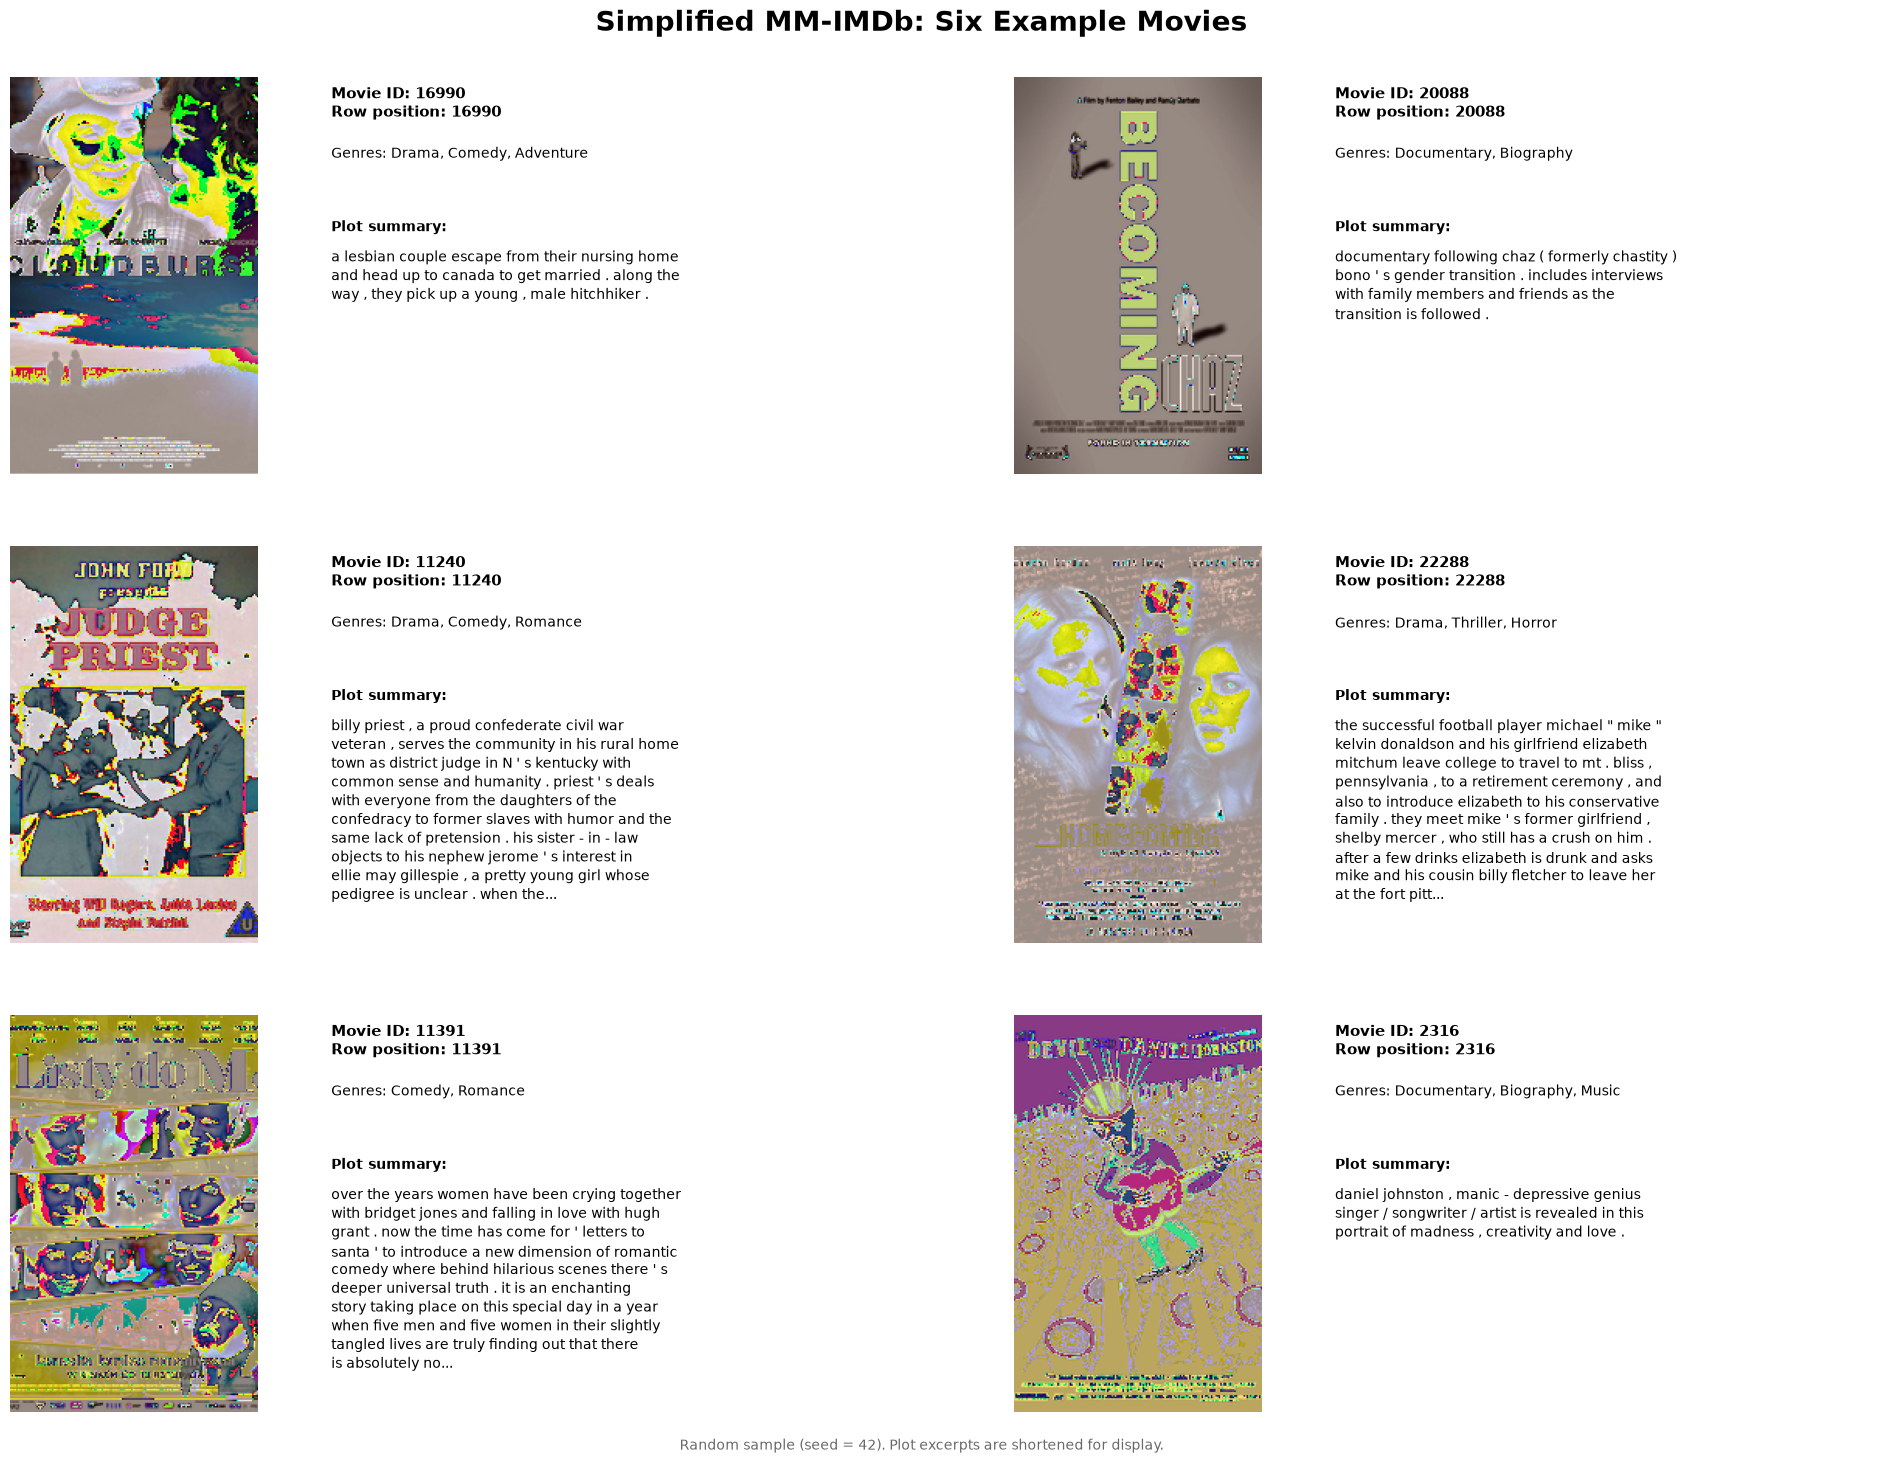

In [13]:
# Load libraries we use into this part
from pathlib import Path
import shutil
import zipfile
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
# Locate archive.zip in the current Jupyter working directory.
ZIP_PATH = Path("archive.zip").resolve()
DATA_DIR = ZIP_PATH.parent / "mmimdb_data"
print("Current working directory:", Path.cwd())
print("Dataset archive:", ZIP_PATH)
# Check that the dataset archive is available.
if not ZIP_PATH.is_file():
    raise FileNotFoundError(
        f"Cannot find: {ZIP_PATH}\n"
        "Place archive.zip in the working directory printed above, "
        "or set ZIP_PATH to its full path."
    )
DATA_DIR.mkdir(parents=True, exist_ok=True)
# Extract the required files and reuse existing complete files.
with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    print("\nFiles inside archive.zip:")
    for filename in archive.namelist():
        print(" -", filename)
    for filename in ["data.npy", "images.npz"]:
        info = archive.getinfo(filename)
        target = DATA_DIR / filename
        if target.is_file() and target.stat().st_size == info.file_size:
            print(f"Using existing file: {filename}")
            continue
        print(f"Extracting {filename} ...", flush=True)
        # Use a temporary file to avoid treating interrupted extraction as complete.
        partial = target.with_suffix(target.suffix + ".part")
        with archive.open(filename) as source, partial.open("wb") as destination:
            shutil.copyfileobj(source, destination, length=1024 * 1024)
        partial.replace(target)
        print(f"Extraction completed: {filename}")
# Load movie records containing IDs, genre labels and plot summaries.
records_path = DATA_DIR / "data.npy"
images_path = DATA_DIR / "images.npz"
records = np.load(records_path, allow_pickle=True)
# Load the poster image array from the extracted NPZ file.
print("\nLoading poster images ...", flush=True)
with np.load(images_path, allow_pickle=False) as image_archive:
    print("Arrays in images.npz:", image_archive.files)
    images = image_archive["images"]
print("Dataset loaded successfully.")
# Summarise the structure of the records and image arrays.
structure_df = pd.DataFrame({
    "Array": ["records", "images"],
    "Shape": [str(records.shape), str(images.shape)],
    "Dimensions": [records.ndim, images.ndim],
    "Data type": [str(records.dtype), str(images.dtype)],
    "Number of entries": [len(records), len(images)]
})
print("\nDATASET STRUCTURE")
display(structure_df)
print("Fields per movie record:", records.shape[1])
print("Poster shape (channels, height, width):", images[0].shape)
# Inspect the three components of the first movie record.
first_id, first_labels, first_plot = records[0]
print("\nFIRST MOVIE RECORD")
print("Movie ID:", first_id)
print("Genre-label vector:", np.asarray(first_labels).tolist())
print("Number of genre labels:", len(first_labels))
print("Number of assigned genres:", np.sum(np.asarray(first_labels) == 1))
print("\nPlot summary:")
print(first_plot)
# Display a compact preview of the first five records.
preview_df = pd.DataFrame({
    "Movie ID": records[:5, 0],
    "Assigned genre count": [
        np.sum(np.asarray(label_vector) == 1)
        for label_vector in records[:5, 1]
    ],
    "Plot preview": [
        str(plot)[:150] + ("..." if len(str(plot)) > 150 else "")
        for plot in records[:5, 2]
    ]
})
print("\nFIRST FIVE MOVIE RECORDS")
display(preview_df)
# Define genre names in the corrected Simplified MM-IMDb label order.
genres = [
    "Drama", "Comedy", "Romance", "Thriller", "Crime",
    "Action", "Adventure", "Horror", "Documentary", "Mystery",
    "Sci-Fi", "Fantasy", "Family", "Biography", "War",
    "History", "Music", "Animation", "Musical", "Western",
    "Sport", "Short", "Film-Noir"
]
# Select six different movies using a fixed seed for reproducibility.
SAMPLE_SEED = 42
rng = np.random.default_rng(SAMPLE_SEED)
sample_indices = rng.choice(len(records), size=6, replace=False)
print("\nSampled row positions:", sample_indices.tolist())
# Create a three-row, two-column layout for six movie examples.
fig = plt.figure(figsize=(20, 15))
grid = fig.add_gridspec(3, 2, hspace=0.18, wspace=0.12)
fig.subplots_adjust(left=0.025, right=0.975, top=0.93, bottom=0.04)
fig.suptitle(
    "Simplified MM-IMDb: Six Example Movies",
    fontsize=20, fontweight="bold", y=0.975
)
for position, i in enumerate(sample_indices):
    movie_id, label_vector, plot = records[i]
    # Map active binary labels to their corresponding genre names.
    sample_genres = [
        genres[j]
        for j, value in enumerate(label_vector)
        if value == 1
    ]
    # Place the poster on the left and its information on the right.
    card = grid[position // 2, position % 2].subgridspec(
        1, 2, width_ratios=[1, 1.65], wspace=0.08
    )
    ax_image = fig.add_subplot(card[0, 0])
    ax_text = fig.add_subplot(card[0, 1])
    # Convert the poster from Channels–Height–Width → Height–Width–Channels while preserving its aspect ratio.
    poster = np.moveaxis(images[i], 0, -1)
    ax_image.imshow(poster)
    ax_image.set_anchor("N")
    ax_image.axis("off")
    ax_text.axis("off")
    # Show the movie ID and row position above the text.
    ax_text.text(
        0, 0.98, f"Movie ID: {movie_id}\nRow position: {i}",
        fontsize=11, fontweight="bold", va="top",
        transform=ax_text.transAxes
    )
    # Wrap genre names to keep them within the text panel.
    genre_text = textwrap.fill(
        "Genres: " + ", ".join(sample_genres), width=43
    )
    ax_text.text(
        0, 0.83, genre_text,
        fontsize=10, va="top", linespacing=1.3,
        transform=ax_text.transAxes
    )
    ax_text.text(
        0, 0.64, "Plot summary:",
        fontsize=10, fontweight="bold", va="top",
        transform=ax_text.transAxes
    )
    # Shorten and wrap the displayed plot without changing the original data.
    plot_preview = textwrap.shorten(
        " ".join(str(plot).split()), width=450, placeholder="..."
    )
    ax_text.text(
        0, 0.57, textwrap.fill(plot_preview, width=48),
        fontsize=10, va="top", linespacing=1.35,
        transform=ax_text.transAxes
    )
# Explain the sampling and shortened text shown in the figure.
fig.text(
    0.5, 0.015,
    f"Random sample (seed = {SAMPLE_SEED}). Plot excerpts are shortened for display.",
    ha="center", fontsize=10, color="dimgray"
)
plt.show()

The dataset loaded successfully, containing 25,959 movie records and 25,959 posters. Each record includes an ID, a genre-label vector and a plot summary. Posters are stored as `uint8` arrays with shape `(3, 256, 160)`. The first movie has four active genre labels, illustrating the multi-label nature of the task. Six sampled movies show the paired posters, genres and plot excerpts. Some posters display unusual colours, which should be examined during the image-quality checks.

### 2. Check missing values and poster alignment:

This section checks missing IDs, missing or empty plots, and the validity of the 23-dimensional binary genre labels. It also compares record and poster counts and checks ID order to assess the structural consistency of pairing records and images by row position.

In [12]:
# Extract IDs and plots without converting missing values into strings.
ids = records[:, 0]
id_series = pd.Series(ids, dtype="object")
plot_series = pd.Series(records[:, 2], dtype="object")
n_records = len(records)
n_images = len(images)
print("Number of movie records:", n_records)
print("Number of poster images:", n_images)
# Identify missing IDs and all rows involved in duplicate non-missing IDs.
missing_ids = id_series.isna().to_numpy()
duplicate_ids = (~missing_ids) & id_series.duplicated(keep=False).to_numpy()
# Check whether IDs follow the expected sequence from 0 to N - 1.
id_position_mismatch = ids != np.arange(n_records)
# Check missing, empty and non-text plots separately.
missing_plots = plot_series.isna().to_numpy()
empty_plots = plot_series.map(
    lambda value: isinstance(value, str) and not value.strip()
).to_numpy(dtype=bool)
non_text_plots = (~missing_plots) & (~plot_series.map(
    lambda value: isinstance(value, str)
).to_numpy(dtype=bool))
# Inspect label values before converting them to an integer array.
label_arrays = [np.asarray(value) for value in records[:, 1]]
correct_label_shape = np.array([
    array.shape == (23,) for array in label_arrays
])
# Identify label vectors containing missing values.
missing_labels = np.array([
    np.asarray(pd.isna(array)).any() for array in label_arrays
])
# Check that correctly shaped label vectors contain only 0 and 1.
binary_labels = np.array([
    np.isin(array, [0, 1]).all() if shape_ok else False
    for array, shape_ok in zip(label_arrays, correct_label_shape)
])
non_binary_labels = correct_label_shape & ~binary_labels
# Count movies with a valid binary vector but no assigned genre.
unlabelled_movies = np.array([
    bool(np.sum(array == 1) == 0) if shape_ok and binary_ok else False
    for array, shape_ok, binary_ok in zip(
        label_arrays, correct_label_shape, binary_labels
    )
])
# Store row-level issues for reporting and locating problematic records.
row_issues = {
    "Missing IDs": missing_ids,
    "Rows with duplicated IDs": duplicate_ids,
    "IDs differing from row positions": id_position_mismatch,
    "Missing plot summaries": missing_plots,
    "Empty or whitespace-only plots": empty_plots,
    "Non-text plot summaries": non_text_plots,
    "Label vectors with incorrect shape": ~correct_label_shape,
    "Label vectors containing missing values": missing_labels,
    "Label vectors containing non-binary values": non_binary_labels,
    "Movies with no assigned genre": unlabelled_movies
}
# Display the number of issues found by each check.
check_results = [
    ("Difference between record and poster counts", abs(n_records - n_images))
]
check_results.extend([
    (name, int(mask.sum())) for name, mask in row_issues.items()
])
quality_df = pd.DataFrame(check_results, columns=["Check", "Issue count"])
quality_df["Result"] = np.where(
    quality_df["Issue count"] == 0, "PASS", "CHECK REQUIRED"
)
print("\nMISSING VALUES AND STRUCTURAL ALIGNMENT CHECKS")
display(quality_df)
# Show how the first five records are paired with posters by row position.
preview_rows = np.arange(min(5, n_records, n_images))
alignment_df = pd.DataFrame({
    "Record row": preview_rows,
    "Movie ID": ids[preview_rows],
    "Poster index": preview_rows,
    "Poster shape": [str(images[i].shape) for i in preview_rows],
    "Non-empty text available": [
        bool(not (missing_plots[i] or empty_plots[i] or non_text_plots[i]))
        for i in preview_rows
    ]
})
print("\nROW-BASED POSTER–PLOT PAIRING")
display(alignment_df)
print("Pairing rule: records[i] is paired with images[i].")
print("These checks assess structure, not the semantic correctness of every pair.")
# Show example row positions for any detected issues.
for name, mask in row_issues.items():
    if mask.any():
        print(f"{name} — first affected rows:", np.flatnonzero(mask)[:10].tolist())
# Stop before further analysis if any check requires investigation.
if quality_df["Issue count"].gt(0).any():
    raise ValueError(
        "Some checks require investigation. Review the table and affected rows above."
    )
# Prepare validated labels and original plot strings for subsequent sections.
labels = np.stack(label_arrays).astype(np.int64)
summaries = plot_series.tolist()
print("\nAll listed checks passed.")
print("Validated label matrix shape:", labels.shape)
print("Number of plot summaries:", len(summaries))

Number of movie records: 25959
Number of poster images: 25959

MISSING VALUES AND STRUCTURAL ALIGNMENT CHECKS


,Check,Issue count,Result
0,Difference between record and poster counts,0,PASS
1,Missing IDs,0,PASS
2,Rows with duplicated IDs,0,PASS
3,IDs differing from row positions,0,PASS
4,Missing plot summaries,0,PASS
5,Empty or whitespace-only plots,0,PASS
6,Non-text plot summaries,0,PASS
7,Label vectors with incorrect shape,0,PASS
8,Label vectors containing missing values,0,PASS
9,Label vectors containing non-binary values,0,PASS



ROW-BASED POSTER–PLOT PAIRING


,Record row,Movie ID,Poster index,Poster shape,Non-empty text available
0,0,0,0,"(3, 256, 160)",True
1,1,1,1,"(3, 256, 160)",True
2,2,2,2,"(3, 256, 160)",True
3,3,3,3,"(3, 256, 160)",True
4,4,4,4,"(3, 256, 160)",True


Pairing rule: records[i] is paired with images[i].
These checks assess structure, not the semantic correctness of every pair.

All listed checks passed.
Validated label matrix shape: (25959, 23)
Number of plot summaries: 25959


All checks passed for the 25,959 movie records and posters. IDs are complete, unique and consistent with row positions. All plot summaries are non-empty text, and every movie has at least one genre label. The validated label matrix has shape `(25959, 23)`, with no missing or non-binary values. These results support the structural consistency of pairing `records[i]` with `images[i]`. They do not establish whether every poster matches its plot semantically.

### 3. Examine genre frequencies:

The section describes the 23 movie genres using frequency tables and bar charts for the counts and percentages of genres occurring most often and least often. It also describes the number of genres for each movie. As a movie can have multiple labels, the percentages for the genres for a movie can add up to more than 100% which will be relevant for the training and evaluation of a model.

Number of movies: 25959
Number of genre labels: 23

GENRE DISTRIBUTION


,Label index,Genre,Count,Percentage
0,0,Drama,13967,53.80
1,1,Comedy,8592,33.10
2,2,Romance,5364,20.66
3,3,Thriller,5192,20.00
4,4,Crime,3838,14.78
5,5,Action,3550,13.68
6,6,Adventure,2710,10.44
7,7,Horror,2703,10.41
8,8,Documentary,2082,8.02
9,9,Mystery,2057,7.92



Most frequent genre: Drama (13,967 movies; 53.80%)
Least frequent genre: Film-Noir (338 movies; 1.30%)
Difference between largest and smallest genre proportions: 52.50 percentage points
Most-to-least frequent genre ratio: 41.32:1


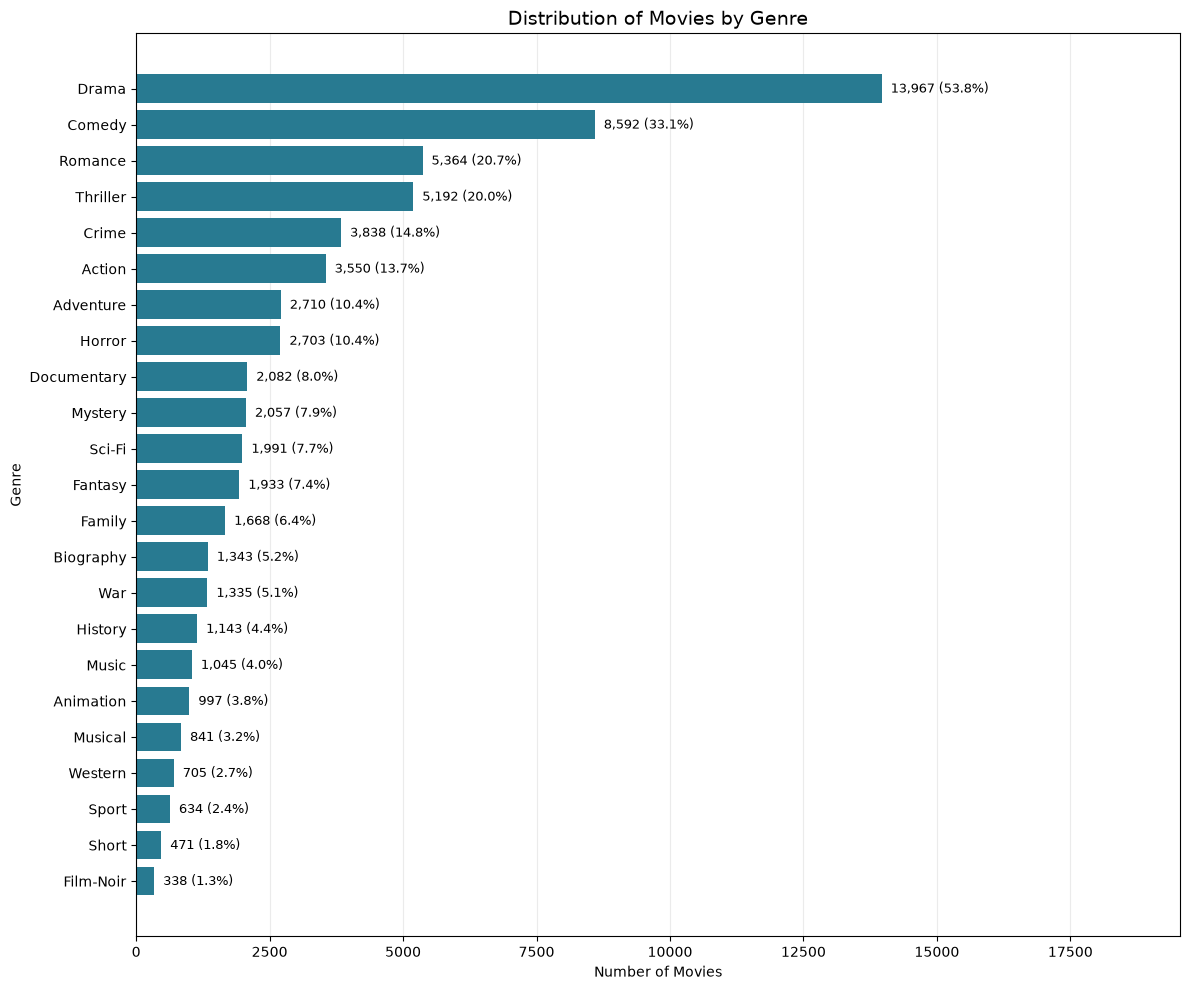


NUMBER OF GENRES PER MOVIE


,Genres per movie
count,25959.00
mean,2.48
std,1.19
min,1.00
25%,2.00
50%,2.00
75%,3.00
max,10.00



DISTRIBUTION OF GENRE COUNTS PER MOVIE


,Number of genres,Movie count,Percentage
0,1,5965,22.98
1,2,8211,31.63
2,3,6894,26.56
3,4,3404,13.11
4,5,1172,4.51
5,6,255,0.98
6,7,47,0.18
7,8,6,0.02
8,9,3,0.01
9,10,2,0.01


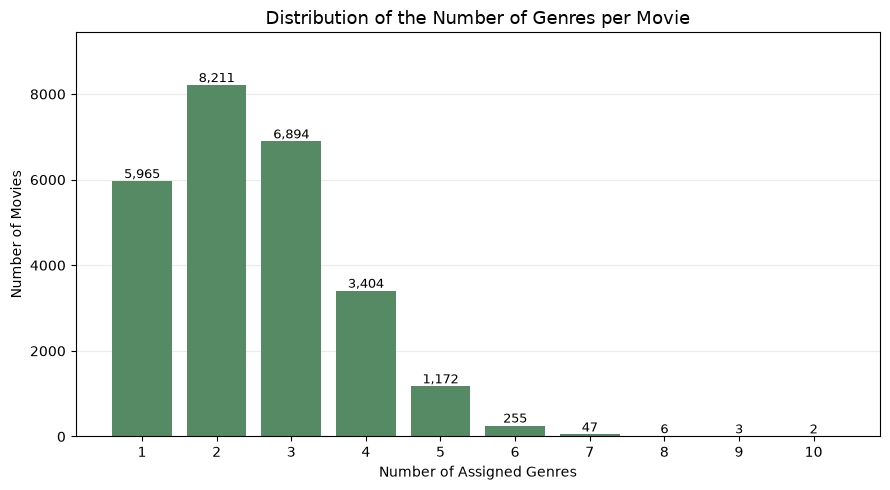


Genre percentages may sum to more than 100% because movies can have multiple genres.
Percentages in the genre-count-per-movie table sum to 100% before rounding.


In [14]:
# Each movie can have several genres, so frequencies are calculated from binary label columns.
required_variables = ["records", "labels", "genres"]
missing_variables = [
    name for name in required_variables if name not in globals()
]
if missing_variables:
    raise RuntimeError(
        "Run Parts 1 and 2 first. Missing: " + ", ".join(missing_variables)
    )
# Confirm that the validated label matrix matches the records and genre names.
if len(genres) != 23 or len(set(genres)) != 23:
    raise ValueError("The genre list must contain 23 unique names.")
if labels.shape != (len(records), len(genres)):
    raise ValueError("The label matrix does not match the records and genre list.")
# Organise the binary labels into a DataFrame using the genre order from Part 1.
genre_df = pd.DataFrame(labels, columns=genres)
n_movies = len(genre_df)
print("Number of movies:", n_movies)
print("Number of genre labels:", len(genres))
# Count the movies belonging to each genre by summing its binary label column.
genre_counts = genre_df.sum(axis=0)
# Calculate prevalence using the total number of movies as the denominator.
# A movie contributes to every genre assigned to it.
genre_percentages = genre_counts / n_movies * 100
# Combine the original column positions, genre names, counts and percentages.
genre_summary = pd.DataFrame({
    "Label index": np.arange(len(genres)),
    "Genre": genres,
    "Count": genre_counts.to_numpy(),
    "Percentage": genre_percentages.to_numpy()
})
# Sort the display table from the most frequent to the least frequent genre.
genre_summary = genre_summary.sort_values(
    "Count", ascending=False
).reset_index(drop=True)
print("\nGENRE DISTRIBUTION")
display(genre_summary.round({"Percentage": 2}))
# Identify the most frequent and least frequent genres.
most_frequent = genre_summary.iloc[0]
least_frequent = genre_summary.iloc[-1]
print(
    f"\nMost frequent genre: {most_frequent['Genre']} "
    f"({int(most_frequent['Count']):,} movies; "
    f"{most_frequent['Percentage']:.2f}%)"
)
print(
    f"Least frequent genre: {least_frequent['Genre']} "
    f"({int(least_frequent['Count']):,} movies; "
    f"{least_frequent['Percentage']:.2f}%)"
)
# Measure the gap between the highest and lowest genre prevalence.
# A difference between percentages is expressed in percentage points.
genre_percentage_gap = genre_percentages.max() - genre_percentages.min()
print(
    "Difference between largest and smallest genre proportions: "
    f"{genre_percentage_gap:.2f} percentage points"
)
# Calculate the frequency ratio when every genre has at least one movie.
if genre_counts.min() > 0:
    imbalance_ratio = genre_counts.max() / genre_counts.min()
    print(f"Most-to-least frequent genre ratio: {imbalance_ratio:.2f}:1")
else:
    print("The frequency ratio is undefined because at least one genre has no movies.")
# Visualise all 23 genres using horizontal bars to keep the names readable.
fig, ax = plt.subplots(figsize=(12, 10))
bars = ax.barh(
    genre_summary["Genre"],
    genre_summary["Count"],
    color="#287A91"
)
# Place the most frequent genre at the top of the chart.
ax.invert_yaxis()
# Add movie counts and percentages beside the bars.
for bar, count, percentage in zip(
    bars, genre_summary["Count"], genre_summary["Percentage"]
):
    ax.text(
        bar.get_width() + genre_counts.max() * 0.012,
        bar.get_y() + bar.get_height() / 2,
        f"{count:,} ({percentage:.1f}%)",
        va="center",
        fontsize=9
    )
# Label the chart and leave enough space for the annotations.
ax.set_title("Distribution of Movies by Genre", fontsize=14)
ax.set_xlabel("Number of Movies")
ax.set_ylabel("Genre")
ax.set_xlim(0, genre_counts.max() * 1.4)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()
# Count the number of active genre labels for each movie.
genres_per_movie = genre_df.sum(axis=1)
# Summarise the typical number of genres and its variation across movies.
print("\nNUMBER OF GENRES PER MOVIE")
display(
    genres_per_movie.describe()
    .to_frame(name="Genres per movie")
    .round(2)
)
# Count how many movies have one genre, two genres, three genres, and so on.
genre_count_distribution = genres_per_movie.value_counts().sort_index()
# Create a table showing the frequency of each label-count category.
genre_count_summary = pd.DataFrame({
    "Number of genres": genre_count_distribution.index,
    "Movie count": genre_count_distribution.to_numpy(),
    "Percentage": genre_count_distribution.to_numpy() / n_movies * 100
})
print("\nDISTRIBUTION OF GENRE COUNTS PER MOVIE")
display(genre_count_summary.round({"Percentage": 2}))
# Visualise how frequently movies receive different numbers of genre labels.
fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(
    genre_count_summary["Number of genres"],
    genre_count_summary["Movie count"],
    color="#568A64"
)
# Annotate each bar with its number of movies.
for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{int(bar.get_height()):,}",
        ha="center",
        va="bottom",
        fontsize=9
    )
ax.set_title("Distribution of the Number of Genres per Movie", fontsize=13)
ax.set_xlabel("Number of Assigned Genres")
ax.set_ylabel("Number of Movies")
ax.set_xticks(genre_count_summary["Number of genres"])
ax.set_ylim(0, genre_count_summary["Movie count"].max() * 1.15)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
# Distinguish overlapping genre prevalence from mutually exclusive label-count categories.
print(
    "\nGenre percentages may sum to more than 100% because movies can have multiple genres."
)
print(
    "Percentages in the genre-count-per-movie table sum to 100% before rounding."
)

The frequency distribution of classes in the given dataset is extremely imbalanced. While most movies are dramas (53.80%), the rarest genre is Film-Noir with only 1.30% of all movies. The frequency ratio of Drama to Film-Noir is 41.32:1. So it is very important to measure the performance on films with rare genres. In terms of the number of genres in a movie, there are, on average, 2.48 genres per movie. The median number of genres for a movie is 2 while the range is 1 to 10. The vast majority of movies have between two and three genres (58.19%). Hence, the task is a multi-label classification task.n.

### 4. Check summary lengths and duplicates:

This section examines plot lengths using word and character counts. Descriptive statistics, histograms and examples illustrate variation in summary length. Exact duplicate summaries are identified and displayed with their movie IDs and genre labels. Duplicate groups are retained for the later data split to help prevent repeated content from appearing across training, validation and test sets.

Number of plot summaries: 25959
Word-count method: split on whitespace.

PLOT LENGTH STATISTICS


,count,min,mean,median,max,std
Word count,25959.0,1.0,124.41,107.0,1887.0,90.47
Character count,25959.0,3.0,632.04,542.0,9326.0,458.27


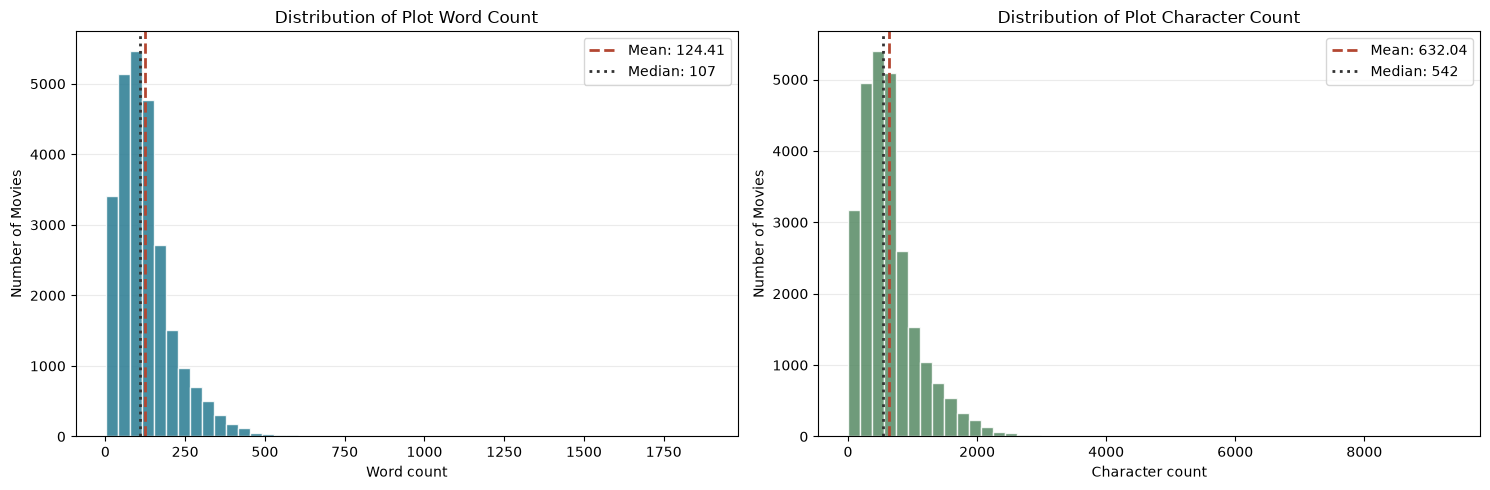


SHORTEST PLOT EXAMPLES


,Record row,Movie ID,Word count,Character count,Plot preview
0,1494,1494,1,5,young
1,3842,3842,1,8,director
2,7542,7542,1,3,how



LONGEST PLOT EXAMPLES


,Record row,Movie ID,Word count,Character count,Plot preview
0,18007,18007,1887,9326,"it is N ad , and the roman empire is being run by the emperor domitian , who has declared himself to be god and ruler over heaven and earth . the christians , who do not recognize his divinity , are a thorn in his..."
1,8679,8679,1863,9296,"dardo is introduced as a wild mountain man who is a friend to all the villagers and loved by all the village women . the enemy of the people , count ulrich , arrives riding with his niece anne and his wife . dardo wh..."
2,2858,2858,1673,8828,"mara and her husband manoa are both upstanding and religious israelites living under the harsh and unjust rule of the philistines . much to their regret , they have not been able to have children . one day , a..."



EXACT PLOT DUPLICATE CHECKS


,Check,Count
0,Total plot summaries,25959
1,Unique plot summaries,25945
2,Groups of identical plots,11
3,Rows belonging to duplicate groups,25
4,Additional copies beyond one per group,14


... (5 outputs left out)

,Record row,Movie ID,Genres
0,246,246,"Comedy, Sci-Fi, Animation, Short"
1,18333,18333,"Comedy, Sci-Fi, Animation, Short"


Shared plot excerpt:
it ' s N . there are all sorts of aliens living throughout space . johnny is a space delivery man
who travels to different planets to deliver packages . johnny is lazy and his only desire is to
sleep in his autopilot spaceship . when the spaceship arrives at the destination , all he has to do
is simply deliver the box . however , it never goes as planned . johnny encounters strange and
bizarre planets and always seems to cause trouble on his delivery route .

DUPLICATE GROUP 3


,Record row,Movie ID,Genres
0,2111,2111,"Action, Adventure, Fantasy, Family, Animation"
1,19162,19162,"Action, Adventure, Fantasy, Family, Animation"


Shared plot excerpt:
an evil genius in a flying fortress is trying to kidnap the birds of the fire , ice , and lightning
islands in hopes of luring the sea power , lugia , and controlling the world . ash and his friends ,
in the process of carrying out an island tradition that requires visiting those three islands ,
discover the plot and try to stop it . even the comic villains , team rocket , turn good and help
out in the end against the threat of world destruction . and pokemon assemble from all around the
world in case they can be of help ( but they end up helping only the merchandising ) .

Stored 11 duplicate plot groups in text_duplicate_groups for the later data split.
This check detects exact text matches only.
All original movie records and summaries are retained.


In [15]:
# Use the records, validated summaries and labels from the previous sections.
required_variables = ["records", "summaries", "labels", "genres"]
missing_variables = [
    name for name in required_variables if name not in globals()
]
if missing_variables:
    raise RuntimeError(
        "Run Parts 1 and 2 first. Missing: " + ", ".join(missing_variables)
    )
# Confirm that text and labels still follow the original record order.
if len(summaries) != len(records) or len(labels) != len(records):
    raise ValueError("The numbers of summaries, labels and records do not match.")
summary_series = pd.Series(summaries, dtype="object")
# Count whitespace-separated units as an approximate measure of word length.
# These counts are different from the encoder token counts examined later.
word_counts = summary_series.map(lambda text: len(text.split()))
# Count all characters, including spaces and punctuation.
character_counts = summary_series.map(len)
# Preserve row positions and movie IDs for inspecting individual summaries.
text_length_df = pd.DataFrame({
    "Record row": np.arange(len(records)),
    "Movie ID": records[:, 0],
    "Word count": word_counts,
    "Character count": character_counts
})
print("Number of plot summaries:", len(summary_series))
print("Word-count method: split on whitespace.")
# Calculate descriptive statistics for both measures of summary length.
length_statistics = text_length_df[
    ["Word count", "Character count"]
].agg(["count", "min", "mean", "median", "max", "std"]).T
print("\nPLOT LENGTH STATISTICS")
display(length_statistics.round(2))
# Plot the full length distributions, including unusually long summaries.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, column, colour in zip(
    axes,
    ["Word count", "Character count"],
    ["#287A91", "#568A64"]
):
    values = text_length_df[column]
    ax.hist(
        values,
        bins=50,
        color=colour,
        edgecolor="white",
        alpha=0.85
    )
    # Add reference lines to compare the mean and median.
    ax.axvline(
        values.mean(),
        color="#B34732",
        linestyle="--",
        linewidth=2,
        label=f"Mean: {values.mean():.2f}"
    )
    ax.axvline(
        values.median(),
        color="#323232",
        linestyle=":",
        linewidth=2,
        label=f"Median: {values.median():.0f}"
    )
    ax.set_title(f"Distribution of Plot {column.title()}")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of Movies")
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()
fig.tight_layout()
plt.show()
# Inspect three short and three long summaries using their word counts.
shortest_rows = text_length_df.nsmallest(3, "Word count").index
longest_rows = text_length_df.nlargest(3, "Word count").index
for heading, row_indices in [
    ("SHORTEST PLOT EXAMPLES", shortest_rows),
    ("LONGEST PLOT EXAMPLES", longest_rows)
]:
    example_df = text_length_df.loc[row_indices].copy()
    # Shorten only the displayed text; preserve the original summaries.
    example_df["Plot preview"] = [
        textwrap.shorten(
            " ".join(summaries[i].split()),
            width=220,
            placeholder="..."
        )
        for i in row_indices
    ]
    print(f"\n{heading}")
    with pd.option_context("display.max_colwidth", 220):
        display(example_df.reset_index(drop=True))
# Group row positions by exactly matching original plot strings.
# Case, spacing and punctuation remain part of the equality check.
plot_row_groups = summary_series.groupby(
    summary_series, sort=False
).indices
text_duplicate_groups = [
    np.asarray(rows, dtype=np.int64)
    for rows in plot_row_groups.values()
    if len(rows) > 1
]
# Display larger duplicate groups first, breaking ties by their first row.
text_duplicate_groups.sort(
    key=lambda rows: (-len(rows), int(rows[0]))
)
# Distinguish duplicate groups, all affected rows and additional copies.
n_duplicate_groups = len(text_duplicate_groups)
n_duplicate_rows = sum(len(rows) for rows in text_duplicate_groups)
n_extra_duplicate_rows = n_duplicate_rows - n_duplicate_groups
duplicate_statistics = pd.DataFrame({
    "Check": [
        "Total plot summaries",
        "Unique plot summaries",
        "Groups of identical plots",
        "Rows belonging to duplicate groups",
        "Additional copies beyond one per group"
    ],
    "Count": [
        len(summary_series),
        len(plot_row_groups),
        n_duplicate_groups,
        n_duplicate_rows,
        n_extra_duplicate_rows
    ]
})
print("\nEXACT PLOT DUPLICATE CHECKS")
display(duplicate_statistics)
# Summarise the row positions, IDs and label consistency of duplicate groups.
duplicate_group_details = []
for group_number, rows in enumerate(text_duplicate_groups, start=1):
    duplicate_group_details.append({
        "Group": group_number,
        "Number of movies": len(rows),
        "Record rows": rows.tolist(),
        "Movie IDs": records[rows, 0].tolist(),
        "Identical genre vectors": bool(
            np.all(labels[rows] == labels[rows[0]])
        )
    })
text_duplicate_summary = pd.DataFrame(
    duplicate_group_details,
    columns=[
        "Group",
        "Number of movies",
        "Record rows",
        "Movie IDs",
        "Identical genre vectors"
    ]
)
if n_duplicate_groups > 0:
    print("\nDUPLICATE GROUP OVERVIEW (UP TO 10 GROUPS)")
    display(text_duplicate_summary.head(10))
    # Show the labels and shared plot excerpt for up to three groups.
    for group_number, rows in enumerate(text_duplicate_groups[:3], start=1):
        print(f"\nDUPLICATE GROUP {group_number}")
        duplicate_examples = pd.DataFrame({
            "Record row": rows,
            "Movie ID": records[rows, 0],
            "Genres": [
                ", ".join(
                    genres[j]
                    for j in np.flatnonzero(labels[row] == 1)
                )
                for row in rows
            ]
        })
        with pd.option_context("display.max_colwidth", None):
            display(duplicate_examples)
        shared_plot_preview = textwrap.shorten(
            " ".join(summaries[int(rows[0])].split()),
            width=700,
            placeholder="..."
        )
        print("Shared plot excerpt:")
        print(textwrap.fill(shared_plot_preview, width=100))
else:
    print("\nNo exact duplicate plot summaries were found.")
# Keep these row groups available for the grouped split in Part 6.
print(
    f"\nStored {n_duplicate_groups} duplicate plot groups "
    "in text_duplicate_groups for the later data split."
)
print("This check detects exact text matches only.")
print("All original movie records and summaries are retained.")

Plot lengths are right-skewed. Word counts range from 1 to 1,887, with a mean of 124.41 and a median of 107. Character counts range from 3 to 9,326, averaging 632.04. One-word summaries such as “young”, “director” and “how” provide limited textual information. The dataset contains 25,945 unique summaries and 11 exact duplicate groups involving 25 records, representing 14 additional copies. The summary “director” appears in five movies with differing genre labels, so identical text does not necessarily indicate identical movies. All records are retained, and duplicate groups are stored for the later data split.

### 5. Check poster quality and duplicates:

This section summarizes the checks for the poster's dimensions, data type, pixel values and colors. All results are shown in tables and plots. As a result, all-zero-posters as well as constant-colored posters are marked. For exact duplicates a SHA-256 (Secure Hash Algorithm) hash sum is calculated and the result is also verified by a comparison of the pixel values of the posters. The genre and plot of the posters is also compared. All records are kept and the duplicate groups are stored for the later data split.

POSTER ARRAY STRUCTURE


,Property,Observed value
0,Number of posters,25959
1,Image array shape,"(25959, 3, 256, 160)"
2,Poster shape (CHW),"(3, 256, 160)"
3,Data type,uint8



Checking poster pixels and computing image hashes ...
Checked 5,000 / 25,959 posters.
Checked 10,000 / 25,959 posters.
Checked 15,000 / 25,959 posters.
Checked 20,000 / 25,959 posters.
Checked 25,000 / 25,959 posters.
Checked 25,959 / 25,959 posters.

POSTER QUALITY CHECKS


,Check,Issue count,Result
0,Posters with unexpected dimensions,0,PASS
1,Posters with pixels outside 0–255,0,PASS
2,All-zero posters,0,PASS
3,Constant-colour posters,0,PASS


Expected poster shape (CHW): (3, 256, 160)
Observed pixel range: 0 to 255
All-zero posters are also included in the constant-colour count.

PER-POSTER PIXEL STATISTICS


,min,mean,median,max,std
Pixel min,0.00,0.00,0.00,8.00,0.05
Pixel max,248.00,255.00,255.00,255.00,0.04
Pixel mean,48.64,136.63,137.35,206.56,15.98
Pixel std,13.24,61.69,62.40,110.17,12.47



RGB CHANNEL STATISTICS


,Channel,Minimum,Maximum,Mean,Standard deviation
0,Red,0,255,145.07,66.11
1,Green,0,255,135.82,65.44
2,Blue,0,255,129.02,62.18


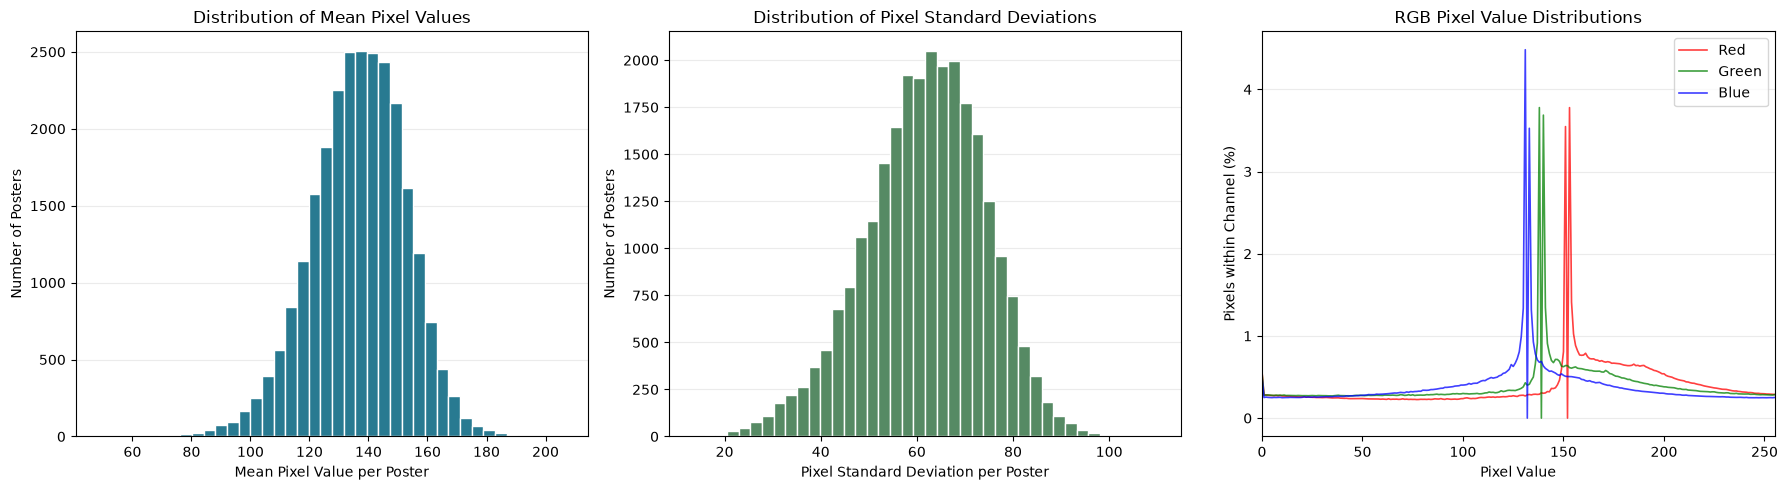


EXACT POSTER DUPLICATE CHECKS


,Check,Count
0,Total posters,25959
1,Unique posters,25871
2,Groups of identical posters,63
3,Rows belonging to duplicate groups,151
4,Additional copies beyond one per group,88



DUPLICATE POSTER GROUPS (UP TO 10 GROUPS)


,Group,Number of movies,Record rows,Movie IDs,Identical genre vectors,Identical plots
0,1,5,"[253, 323, 362, 475, 18365]","[253, 323, 362, 475, 18365]",False,False
1,2,5,"[353, 360, 18280, 18327, 18354]","[353, 360, 18280, 18327, 18354]",False,False
2,3,4,"[432, 436, 15608, 18282]","[432, 436, 15608, 18282]",False,False
3,4,4,"[3099, 11512, 14995, 17919]","[3099, 11512, 14995, 17919]",False,False
4,5,3,"[202, 3842, 20086]","[202, 3842, 20086]",False,False
5,6,3,"[225, 301, 18402]","[225, 301, 18402]",False,False
6,7,3,"[258, 2020, 18363]","[258, 2020, 18363]",False,False
7,8,3,"[294, 315, 15603]","[294, 315, 15603]",True,False
8,9,3,"[359, 430, 18297]","[359, 430, 18297]",False,False
9,10,3,"[420, 18279, 18337]","[420, 18279, 18337]",False,False


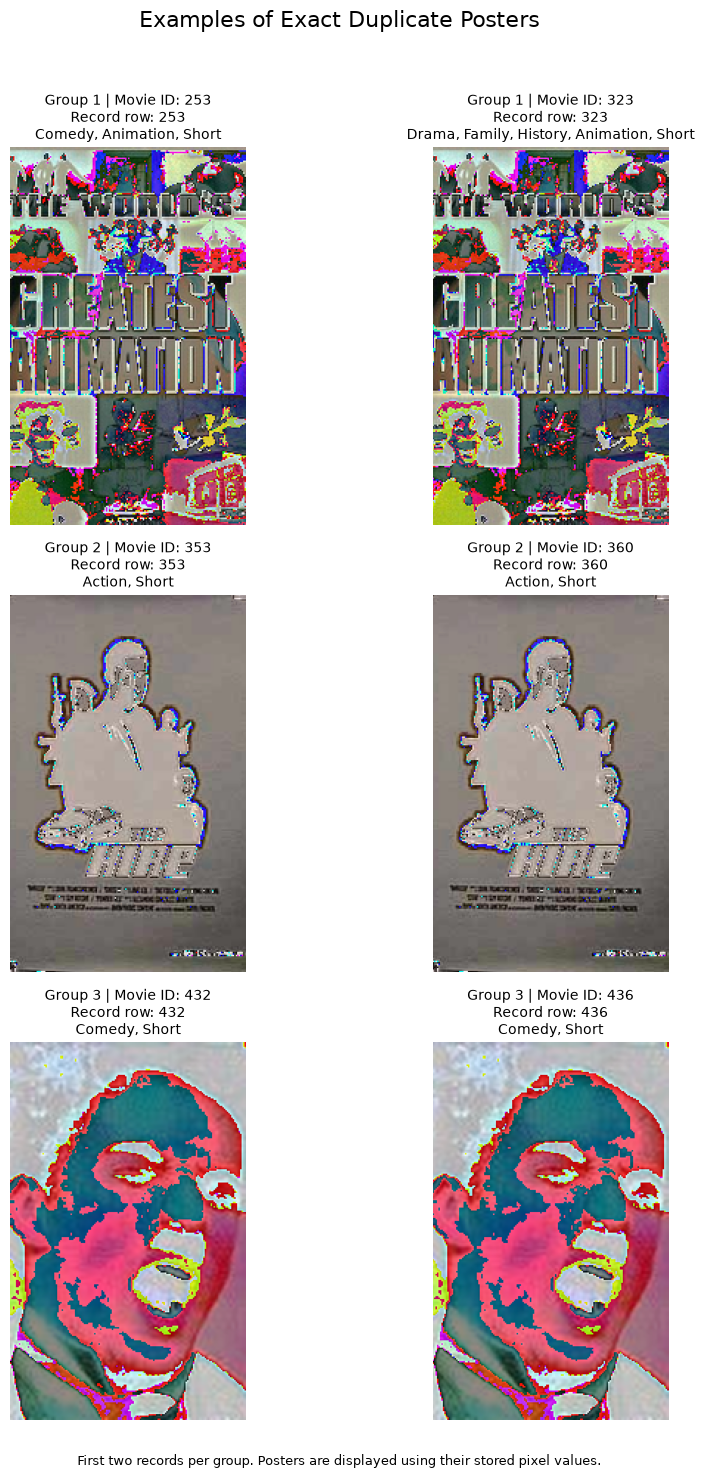


Stored 63 duplicate poster groups in image_duplicate_groups for the later data split.
Duplicate detection checks exact pixels, not visually similar posters.
Valid dimensions and pixel ranges do not establish colour accuracy.
All original posters and movie records are retained.


In [16]:
import hashlib
# Use the aligned images, movie records and validated labels from earlier sections.
required_variables = ["records", "images", "labels", "genres", "summaries"]
missing_variables = [
    name for name in required_variables if name not in globals()
]
if missing_variables:
    raise RuntimeError(
        "Run Parts 1 and 2 first. Missing: " + ", ".join(missing_variables)
    )
# Confirm that the arrays contain the same number of movie entries.
n_posters = len(images)
if not (n_posters == len(records) == len(labels) == len(summaries)):
    raise ValueError("The numbers of posters, records, labels and summaries differ.")
if n_posters == 0:
    raise ValueError("The poster array is empty.")
# Expect channel-first images with three colour channels.
if images.ndim != 4 or images.shape[1] != 3:
    raise ValueError(
        f"Expected an image array shaped (N, 3, H, W), received {images.shape}."
    )
# Analyse the original uint8 pixels without converting or rescaling the dataset.
if images.dtype != np.uint8:
    raise TypeError(
        f"Expected raw uint8 posters, received {images.dtype}. "
        "Inspect the image encoding before applying these pixel checks."
    )
# Show the observed structure before scanning individual posters.
poster_structure_df = pd.DataFrame({
    "Property": [
        "Number of posters",
        "Image array shape",
        "Poster shape (CHW)",
        "Data type"
    ],
    "Observed value": [
        n_posters,
        str(images.shape),
        str(images.shape[1:]),
        str(images.dtype)
    ]
})
print("POSTER ARRAY STRUCTURE")
display(poster_structure_df)
# Collect small per-image statistics rather than copying the entire image array.
image_quality_rows = []
image_hashes = []
hash_row_groups = {}
channel_histograms = np.zeros((3, 256), dtype=np.int64)
print("\nChecking poster pixels and computing image hashes ...", flush=True)
for i, poster in enumerate(images):
    # Calculate the minimum and maximum within each colour channel.
    channel_min = poster.min(axis=(1, 2))
    channel_max = poster.max(axis=(1, 2))
    # A constant-colour image has no spatial variation in any channel.
    # This includes solid colours whose red, green and blue values differ.
    image_quality_rows.append({
        "Record row": i,
        "Movie ID": records[i, 0],
        "Pixel min": int(channel_min.min()),
        "Pixel max": int(channel_max.max()),
        "Pixel mean": float(poster.mean()),
        "Pixel std": float(poster.std()),
        "All-zero": bool(channel_max.max() == 0),
        "Constant colour": bool(np.all(channel_min == channel_max))
    })
    # Accumulate the observed pixel frequencies for each stored RGB channel.
    for channel in range(3):
        channel_histograms[channel] += np.bincount(
            poster[channel].ravel(), minlength=256
        )
    # Hash the original pixel bytes to find candidate duplicate images.
    digest = hashlib.sha256(poster.tobytes(order="C")).hexdigest()
    image_hashes.append(digest)
    hash_row_groups.setdefault(digest, []).append(i)
    # Report progress without printing a separate line for every image.
    if (i + 1) % 5000 == 0 or i + 1 == n_posters:
        print(f"Checked {i + 1:,} / {n_posters:,} posters.", flush=True)
# Keep image statistics and hashes aligned with the original record rows.
image_quality_df = pd.DataFrame(image_quality_rows)
image_hashes = np.asarray(image_hashes)
# All entries in a regular image array share the same dimensions and data type.
expected_poster_shape = (3, 256, 160)
incorrect_shape_count = (
    n_posters if images.shape[1:] != expected_poster_shape else 0
)
outside_range = (
    (image_quality_df["Pixel min"] < 0)
    | (image_quality_df["Pixel max"] > 255)
)
# Flag cases for inspection; all-zero images also count as constant-colour images.
poster_quality_checks = pd.DataFrame({
    "Check": [
        "Posters with unexpected dimensions",
        "Posters with pixels outside 0–255",
        "All-zero posters",
        "Constant-colour posters"
    ],
    "Issue count": [
        incorrect_shape_count,
        int(outside_range.sum()),
        int(image_quality_df["All-zero"].sum()),
        int(image_quality_df["Constant colour"].sum())
    ]
})
poster_quality_checks["Result"] = np.where(
    poster_quality_checks["Issue count"] == 0, "PASS", "REVIEW"
)
print("\nPOSTER QUALITY CHECKS")
display(poster_quality_checks)
print("Expected poster shape (CHW):", expected_poster_shape)
print(
    "Observed pixel range:",
    int(image_quality_df["Pixel min"].min()),
    "to",
    int(image_quality_df["Pixel max"].max())
)
print("All-zero posters are also included in the constant-colour count.")
# Summarise how pixel statistics vary between individual posters.
pixel_statistics = image_quality_df[
    ["Pixel min", "Pixel max", "Pixel mean", "Pixel std"]
].agg(["min", "mean", "median", "max", "std"]).T
print("\nPER-POSTER PIXEL STATISTICS")
display(pixel_statistics.round(2))
# Show affected rows when zero or constant-colour posters are present.
flagged_posters = image_quality_df[
    image_quality_df["All-zero"] | image_quality_df["Constant colour"]
]
if not flagged_posters.empty:
    print("\nZERO OR CONSTANT-COLOUR POSTERS (UP TO 10 ROWS)")
    display(flagged_posters.head(10).round(2))
# Derive pooled channel statistics from the accumulated pixel histograms.
pixel_values = np.arange(256, dtype=np.float64)
channel_names = ["Red", "Green", "Blue"]
channel_statistics_rows = []
for channel_name, histogram in zip(channel_names, channel_histograms):
    occupied_values = np.flatnonzero(histogram)
    channel_mean = float(
        np.dot(histogram, pixel_values) / histogram.sum()
    )
    channel_std = float(np.sqrt(
        np.dot(histogram, (pixel_values - channel_mean) ** 2)
        / histogram.sum()
    ))
    channel_statistics_rows.append({
        "Channel": channel_name,
        "Minimum": int(occupied_values[0]),
        "Maximum": int(occupied_values[-1]),
        "Mean": channel_mean,
        "Standard deviation": channel_std
    })
channel_statistics_df = pd.DataFrame(channel_statistics_rows)
print("\nRGB CHANNEL STATISTICS")
display(channel_statistics_df.round(2))
# Visualise per-poster statistics and the pooled RGB pixel distributions.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(
    image_quality_df["Pixel mean"],
    bins=40,
    color="#287A91",
    edgecolor="white"
)
axes[0].set_title("Distribution of Mean Pixel Values")
axes[0].set_xlabel("Mean Pixel Value per Poster")
axes[0].set_ylabel("Number of Posters")
axes[1].hist(
    image_quality_df["Pixel std"],
    bins=40,
    color="#568A64",
    edgecolor="white"
)
axes[1].set_title("Distribution of Pixel Standard Deviations")
axes[1].set_xlabel("Pixel Standard Deviation per Poster")
axes[1].set_ylabel("Number of Posters")
# Express each channel histogram as a percentage of that channel's pixels.
for channel_name, histogram, colour in zip(
    channel_names, channel_histograms, ["red", "green", "blue"]
):
    axes[2].plot(
        pixel_values,
        histogram / histogram.sum() * 100,
        label=channel_name,
        color=colour,
        linewidth=1.2,
        alpha=0.75
    )
axes[2].set_title("RGB Pixel Value Distributions")
axes[2].set_xlabel("Pixel Value")
axes[2].set_ylabel("Pixels within Channel (%)")
axes[2].set_xlim(0, 255)
axes[2].legend()
for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
# Retain hash groups containing more than one poster.
image_duplicate_groups = [
    np.asarray(rows, dtype=np.int64)
    for rows in hash_row_groups.values()
    if len(rows) > 1
]
image_duplicate_groups.sort(
    key=lambda rows: (-len(rows), int(rows[0]))
)
# Confirm every candidate group using direct pixel comparisons.
for rows in image_duplicate_groups:
    reference_poster = images[int(rows[0])]
    if not all(
        np.array_equal(reference_poster, images[int(row)])
        for row in rows[1:]
    ):
        raise ValueError(
            "A hash group failed exact pixel comparison. Inspect this group."
        )
# Distinguish duplicate groups, affected records and additional copies.
n_image_duplicate_groups = len(image_duplicate_groups)
n_image_duplicate_rows = sum(
    len(rows) for rows in image_duplicate_groups
)
n_extra_image_copies = (
    n_image_duplicate_rows - n_image_duplicate_groups
)
image_duplicate_statistics = pd.DataFrame({
    "Check": [
        "Total posters",
        "Unique posters",
        "Groups of identical posters",
        "Rows belonging to duplicate groups",
        "Additional copies beyond one per group"
    ],
    "Count": [
        n_posters,
        len(hash_row_groups),
        n_image_duplicate_groups,
        n_image_duplicate_rows,
        n_extra_image_copies
    ]
})
print("\nEXACT POSTER DUPLICATE CHECKS")
display(image_duplicate_statistics)
# Inspect whether identical posters also share the same labels and plot text.
image_duplicate_details = []
for group_number, rows in enumerate(image_duplicate_groups, start=1):
    image_duplicate_details.append({
        "Group": group_number,
        "Number of movies": len(rows),
        "Record rows": rows.tolist(),
        "Movie IDs": records[rows, 0].tolist(),
        "Identical genre vectors": bool(
            np.all(labels[rows] == labels[rows[0]])
        ),
        "Identical plots": all(
            summaries[int(row)] == summaries[int(rows[0])]
            for row in rows[1:]
        )
    })
image_duplicate_summary = pd.DataFrame(
    image_duplicate_details,
    columns=[
        "Group",
        "Number of movies",
        "Record rows",
        "Movie IDs",
        "Identical genre vectors",
        "Identical plots"
    ]
)
if n_image_duplicate_groups > 0:
    print("\nDUPLICATE POSTER GROUPS (UP TO 10 GROUPS)")
    display(image_duplicate_summary.head(10))
    # Display two posters from each of the first three duplicate groups.
    n_groups_to_show = min(3, n_image_duplicate_groups)
    fig, axes = plt.subplots(
        n_groups_to_show,
        2,
        figsize=(10, 5 * n_groups_to_show),
        squeeze=False
    )
    for group_position, rows in enumerate(
        image_duplicate_groups[:n_groups_to_show]
    ):
        for column, row in enumerate(rows[:2]):
            row = int(row)
            ax = axes[group_position, column]
            # Rearrange CHW to HWC for display without changing pixel values.
            ax.imshow(np.moveaxis(images[row], 0, -1))
            genre_text = ", ".join(
                genres[j] for j in np.flatnonzero(labels[row] == 1)
            )
            ax.set_title(
                f"Group {group_position + 1} | Movie ID: {records[row, 0]}\n"
                f"Record row: {row}\n"
                + textwrap.fill(genre_text, width=45),
                fontsize=10
            )
            ax.axis("off")
    fig.suptitle("Examples of Exact Duplicate Posters", fontsize=16)
    fig.tight_layout(rect=[0, 0.03, 1, 0.96])
    fig.text(
        0.5,
        0.01,
        "First two records per group. Posters are displayed using their stored pixel values.",
        ha="center",
        fontsize=9
    )
    plt.show()
else:
    print("\nNo exact duplicate posters were found.")
# Preserve the confirmed groups for combining text and image groups in Part 6.
print(
    f"\nStored {n_image_duplicate_groups} duplicate poster groups "
    "in image_duplicate_groups for the later data split."
)
print("Duplicate detection checks exact pixels, not visually similar posters.")
print("Valid dimensions and pixel ranges do not establish colour accuracy.")
print("All original posters and movie records are retained.")

All 25,959 posters have the expected shape (3, 256, 160) and uint8 data type, with pixel values ranging from 0 to 255. No unexpected dimensions, all-zero images or constant-colour posters were found. The average per-poster pixel mean is 136.63. These checks confirm structural consistency but do not establish colour accuracy. There are 25,871 unique posters and 63 exact duplicate groups involving 151 records, representing 88 additional copies. Some identical posters have different plots and genre labels. All records are retained, and duplicate groups are stored for the later data split to prevent identical posters from appearing across subsets.

### 6. Preprocessing and data splitting:

For this section we split the data into approximately 60% for training, 10% for validation and 30% for testing and keep duplicate groups together. We provide tables and figures to show the split in numbers as well as genre distribution and content overlap. For text we standardize whitespace and apply DistilBERT tokenization. CLIP preprocessing is applied to the poster tensors. We check token lengths, truncation rates and sample alignment. Importantly we keep all original records.

Summaries changed by whitespace cleaning: 0

GROUPING SUMMARY


,Measure,Count
0,Original plot duplicate groups,11
1,Cleaned plot duplicate groups,11
2,Poster duplicate groups,63
3,"Combined groups, including single records",25863
4,Combined groups containing multiple records,68
5,Largest combined group,6



DATA SPLIT SUMMARY


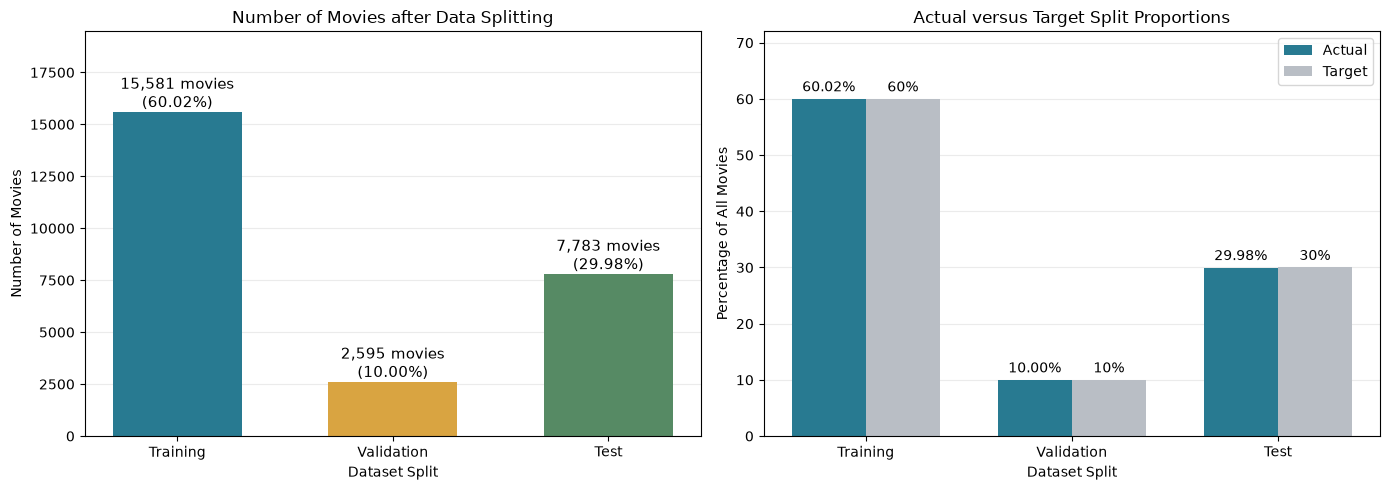

,Split,Movies,Percentage,Groups
0,train,15581,60.02,15517
1,validation,2595,10.00,2587
2,test,7783,29.98,7759


All original records are retained: True
The requested proportions apply to groups, so movie proportions are approximate.

EXACT-CONTENT AND GROUP OVERLAP CHECKS


,Split pair,Shared rows,Shared groups,Shared original plots,Shared cleaned plots,Shared poster hashes,Result
0,train / validation,0,0,0,0,0,PASS
1,train / test,0,0,0,0,0,PASS
2,validation / test,0,0,0,0,0,PASS



GENRE DISTRIBUTION BY SPLIT


,Genre,Train count,Train (%),Validation count,Validation (%),Test count,Test (%)
0,Drama,8378,53.77,1432,55.18,4157,53.41
1,Comedy,5210,33.44,824,31.75,2558,32.87
2,Romance,3259,20.92,535,20.62,1570,20.17
3,Thriller,3136,20.13,517,19.92,1539,19.77
4,Crime,2272,14.58,372,14.34,1194,15.34
5,Action,2170,13.93,342,13.18,1038,13.34
6,Adventure,1641,10.53,267,10.29,802,10.30
7,Horror,1564,10.04,267,10.29,872,11.20
8,Documentary,1260,8.09,205,7.90,617,7.93
9,Mystery,1220,7.83,196,7.55,641,8.24


Genres with no positive examples in train: []
Genres with no positive examples in validation: []
Genres with no positive examples in test: []


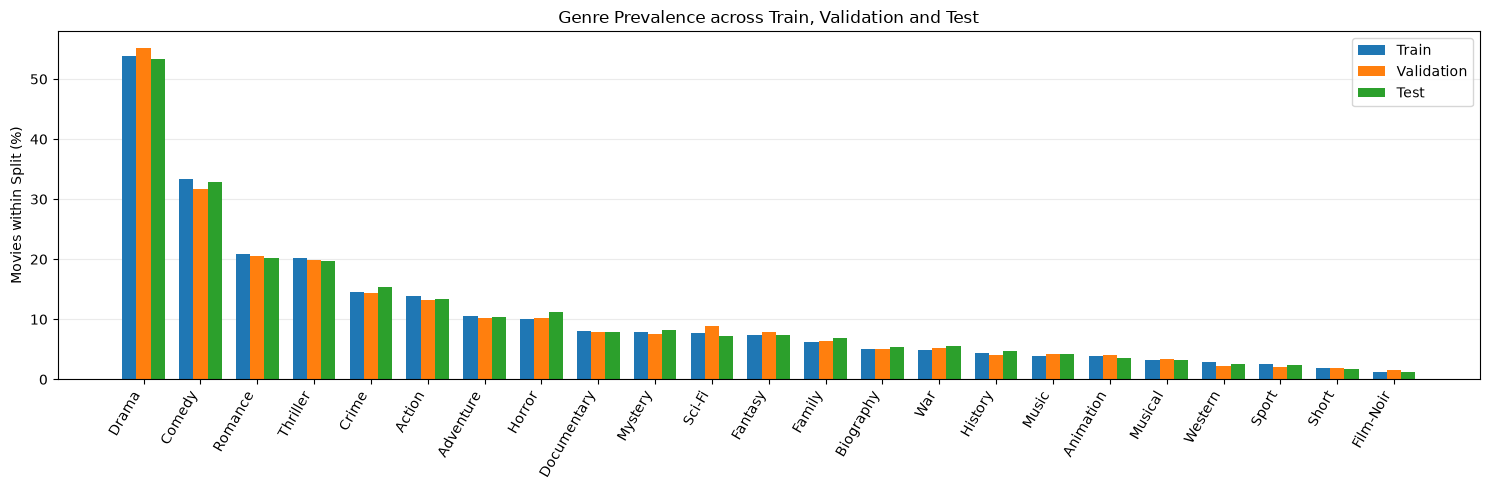


Loading the DistilBERT tokenizer and CLIP image processor ...
Counted tokens for 5,120 / 25,959 summaries.
Counted tokens for 10,240 / 25,959 summaries.
Counted tokens for 15,360 / 25,959 summaries.
Counted tokens for 20,480 / 25,959 summaries.
Counted tokens for 25,600 / 25,959 summaries.
Counted tokens for 25,959 / 25,959 summaries.

TOKEN LENGTHS BEFORE TRUNCATION


,Split,Minimum,Mean,Median,Maximum,Plots exceeding 256 tokens,Truncated plots (%)
0,train,3,136.42,117.0,1999,1621,10.40
1,validation,6,133.90,117.0,961,254,9.79
2,test,3,133.47,114.0,1251,793,10.19



TRAINING-SET TRUNCATION COMPARISON


,Token limit,Training plots requiring truncation,Training plots (%)
0,256,1621,10.40
1,512,73,0.47


Selected maximum sequence length: 256

PREPROCESSING CONFIGURATION


,Setting,Value
0,seed,42
1,split_ratios,"[0.6, 0.1, 0.3]"
2,text_model,distilbert/distilbert-base-uncased
3,text_revision,12040accade4e8a0f71eabdb258fecc2e7e948be
4,image_model,openai/clip-vit-base-patch32
5,image_revision,3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268
6,text_cleaning,Collapse whitespace; retain punctuation and st...
7,max_length,256
8,padding,max_length
9,image_resize,{'shortest_edge': 224}



PREPROCESSED TRAINING BATCH


,Tensor,Shape,Data type,All finite
0,input_ids,"(8, 256)",torch.int64,True
1,attention_mask,"(8, 256)",torch.int64,True
2,pixel_values,"(8, 3, 224, 224)",torch.float32,True
3,labels,"(8, 23)",torch.float32,True



BATCH ALIGNMENT AND TOKEN COUNTS


,Record row,Movie ID,Tokens before truncation,Tokens after truncation,Assigned genres
0,1,1,95,95,4
1,2,2,269,256,5
2,5,5,91,91,3
3,6,6,117,117,3
4,7,7,170,170,2
5,8,8,320,256,4
6,9,9,306,256,3
7,10,10,89,89,4


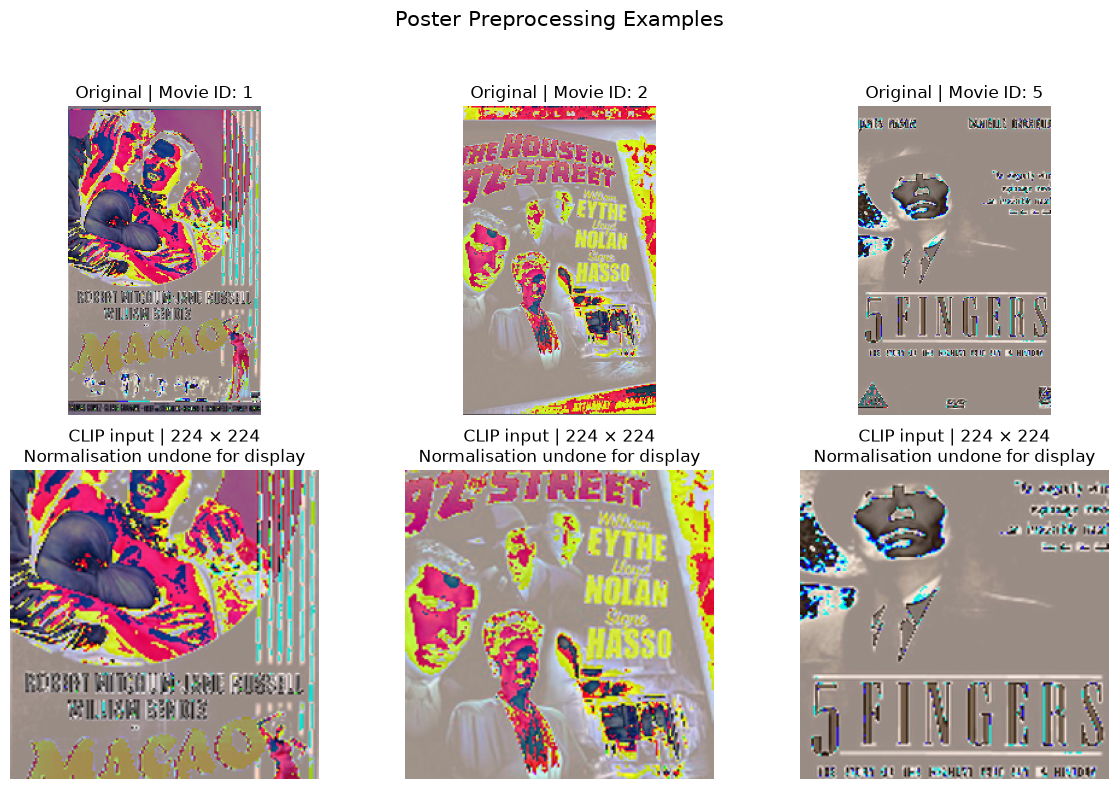


Preprocessing and split checks completed.
All original records are retained; only row indices define the splits.
The overlap checks cover exact content and the constructed groups.
CLIP preprocessing does not establish or correct poster colour accuracy.


In [18]:
# 6. Preprocessing and data splitting
# If needed, install missing packages in this kernel before running this cell.
# %pip install scikit-learn torch "transformers>=4.45,<5" pillow
from itertools import combinations
from sklearn.model_selection import GroupShuffleSplit
import torch
import transformers
from transformers import AutoTokenizer, AutoImageProcessor
# Require the original data and duplicate groups produced in Parts 1–5.
required_variables = [
    "records", "images", "labels", "genres", "summaries",
    "text_duplicate_groups", "image_duplicate_groups", "image_hashes"
]
missing_variables = [
    name for name in required_variables if name not in globals()
]
if missing_variables:
    raise RuntimeError(
        "Run Parts 1–5 first. Missing: " + ", ".join(missing_variables)
    )
n_movies = len(records)
if not (len(images) == len(summaries) == len(image_hashes) == n_movies):
    raise ValueError("Data lengths differ. Rerun the earlier checks.")
if labels.shape != (n_movies, len(genres)):
    raise ValueError("The label matrix does not match the movie records.")
# Fix the split and preprocessing settings before examining model performance.
SEED = 42
TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.60, 0.10, 0.30
MAX_LENGTH = 256
PREVIEW_BATCH_SIZE = 8
TEXT_MODEL_ID = "distilbert/distilbert-base-uncased"
IMAGE_MODEL_ID = "openai/clip-vit-base-patch32"
# Pin the pretrained file revisions so later runs use the same configuration.
TEXT_REVISION = "12040accade4e8a0f71eabdb258fecc2e7e948be"
IMAGE_REVISION = "3d74acf9a28c67741b2f4f2ea7635f0aaf6f0268"
# Standardise whitespace while preserving the original summaries separately.
# Keep punctuation, stopwords and short summaries.
cleaned_summaries = [" ".join(text.split()) for text in summaries]
changed_text_count = sum(
    original != cleaned
    for original, cleaned in zip(summaries, cleaned_summaries)
)
print("Summaries changed by whitespace cleaning:", changed_text_count)
# Check whether whitespace cleaning makes additional summaries identical.
cleaned_row_groups = pd.Series(cleaned_summaries).groupby(
    pd.Series(cleaned_summaries), sort=False
).indices
cleaned_duplicate_groups = [
    np.asarray(rows, dtype=np.int64)
    for rows in cleaned_row_groups.values()
    if len(rows) > 1
]
# Connect records that share an original plot, cleaned plot or exact poster.
# Connections are transitive: if A shares text with B and B shares an image
# with C, all three records must stay in the same split.
parent = np.arange(n_movies)
def find_group(row):
    while parent[row] != row:
        parent[row] = parent[parent[row]]
        row = parent[row]
    return int(row)
for rows in (
    text_duplicate_groups + image_duplicate_groups + cleaned_duplicate_groups
):
    for row in rows[1:]:
        root_a = find_group(int(rows[0]))
        root_b = find_group(int(row))
        parent[max(root_a, root_b)] = min(root_a, root_b)
group_ids = np.asarray(
    [find_group(row) for row in range(n_movies)], dtype=np.int64
)
_, group_sizes = np.unique(group_ids, return_counts=True)
group_summary_df = pd.DataFrame({
    "Measure": [
        "Original plot duplicate groups",
        "Cleaned plot duplicate groups",
        "Poster duplicate groups",
        "Combined groups, including single records",
        "Combined groups containing multiple records",
        "Largest combined group"
    ],
    "Count": [
        len(text_duplicate_groups),
        len(cleaned_duplicate_groups),
        len(image_duplicate_groups),
        len(group_sizes),
        int(np.sum(group_sizes > 1)),
        int(group_sizes.max())
    ]
})
print("\nGROUPING SUMMARY")
display(group_summary_df)
# Split groups into approximately 70% development data and 30% test data.
all_indices = np.arange(n_movies)
split_1 = GroupShuffleSplit(
    n_splits=1, test_size=TEST_RATIO, random_state=SEED
)
train_val_pos, test_pos = next(
    split_1.split(all_indices, groups=group_ids)
)
train_val_idx = all_indices[train_val_pos]
test_idx = all_indices[test_pos]
# Allocate approximately 10% of all data to validation and 60% to training.
split_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=VAL_RATIO / (TRAIN_RATIO + VAL_RATIO),
    random_state=SEED
)
train_pos, val_pos = next(
    split_2.split(train_val_idx, groups=group_ids[train_val_idx])
)
train_idx = train_val_idx[train_pos]
val_idx = train_val_idx[val_pos]
split_indices = {"train": train_idx, "validation": val_idx, "test": test_idx}
# Verify that every original row appears exactly once across the three splits.
assigned_rows = np.concatenate(list(split_indices.values()))
if not np.array_equal(np.sort(assigned_rows), all_indices):
    raise ValueError("The splits contain missing, repeated or invalid row indices.")
split_summary_df = pd.DataFrame([
    {
        "Split": name,
        "Movies": len(indices),
        "Percentage": len(indices) / n_movies * 100,
        "Groups": len(np.unique(group_ids[indices]))
    }
    for name, indices in split_indices.items()
])
print("\nDATA SPLIT SUMMARY")
# Visualise the actual number and percentage of movies in each split.
split_names = ["train", "validation", "test"]
split_display_names = ["Training", "Validation", "Test"]
split_movie_counts = np.array([
    len(split_indices[name]) for name in split_names
])
split_movie_percentages = split_movie_counts / len(records) * 100
target_percentages = np.array([
    TRAIN_RATIO, VAL_RATIO, TEST_RATIO
]) * 100
# Create two panels showing movie counts and actual versus target proportions.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
split_colours = ["#287A91", "#D9A441", "#568A64"]
bars = axes[0].bar(
    split_display_names,
    split_movie_counts,
    color=split_colours,
    width=0.6
)
# Annotate each split with its actual movie count and percentage.
for bar, count, percentage in zip(
    bars, split_movie_counts, split_movie_percentages
):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,} movies\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11
    )
axes[0].set_title("Number of Movies after Data Splitting")
axes[0].set_xlabel("Dataset Split")
axes[0].set_ylabel("Number of Movies")
axes[0].set_ylim(0, split_movie_counts.max() * 1.25)
# Compare achieved movie proportions with the intended 60/10/30 allocation.
positions = np.arange(len(split_names))
actual_bars = axes[1].bar(
    positions - 0.18,
    split_movie_percentages,
    width=0.36,
    color="#287A91",
    label="Actual"
)
target_bars = axes[1].bar(
    positions + 0.18,
    target_percentages,
    width=0.36,
    color="#B9BEC5",
    label="Target"
)
# Display percentages directly above both sets of bars.
axes[1].bar_label(actual_bars, fmt="%.2f%%", padding=3, fontsize=10)
axes[1].bar_label(target_bars, fmt="%.0f%%", padding=3, fontsize=10)
axes[1].set_xticks(positions)
axes[1].set_xticklabels(split_display_names)
axes[1].set_title("Actual versus Target Split Proportions")
axes[1].set_xlabel("Dataset Split")
axes[1].set_ylabel("Percentage of All Movies")
axes[1].set_ylim(
    0, max(split_movie_percentages.max(), target_percentages.max()) * 1.2
)
axes[1].legend()
for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
display(split_summary_df.round({"Percentage": 2}))
print("All original records are retained:", len(assigned_rows) == n_movies)
print("The requested proportions apply to groups, so movie proportions are approximate.")
# Preserve one manifest linking each original row, movie ID, group and split.
row_split = np.empty(n_movies, dtype=object)
for name, indices in split_indices.items():
    row_split[indices] = name
split_manifest = pd.DataFrame({
    "Record row": all_indices,
    "Movie ID": records[:, 0],
    "Group ID": group_ids,
    "Split": row_split
})
# Check overlap using row indices, combined groups and exact modality content.
split_sets = {}
for name, indices in split_indices.items():
    split_sets[name] = {
        "Shared rows": set(indices.tolist()),
        "Shared groups": set(group_ids[indices].tolist()),
        "Shared original plots": {summaries[int(i)] for i in indices},
        "Shared cleaned plots": {cleaned_summaries[int(i)] for i in indices},
        "Shared poster hashes": {image_hashes[int(i)] for i in indices}
    }
overlap_columns = list(split_sets["train"])
leakage_rows = []
for left, right in combinations(split_indices, 2):
    result = {"Split pair": f"{left} / {right}"}
    for column in overlap_columns:
        result[column] = len(split_sets[left][column] & split_sets[right][column])
    leakage_rows.append(result)
leakage_df = pd.DataFrame(leakage_rows)
leakage_df["Result"] = np.where(
    leakage_df[overlap_columns].sum(axis=1) == 0, "PASS", "FAIL"
)
print("\nEXACT-CONTENT AND GROUP OVERLAP CHECKS")
display(leakage_df)
if (leakage_df["Result"] == "FAIL").any():
    raise ValueError("An overlap check failed. Do not continue to training.")
# Compare label prevalence because this group split is not stratified.
split_label_distribution = pd.DataFrame({"Genre": genres})
for name, indices in split_indices.items():
    counts = labels[indices].sum(axis=0)
    split_label_distribution[f"{name.title()} count"] = counts
    split_label_distribution[f"{name.title()} (%)"] = counts / len(indices) * 100
print("\nGENRE DISTRIBUTION BY SPLIT")
display(split_label_distribution.round(2))
for name, indices in split_indices.items():
    missing_genres = [
        genres[j] for j in np.flatnonzero(labels[indices].sum(axis=0) == 0)
    ]
    print(f"Genres with no positive examples in {name}: {missing_genres}")
# Use percentages to compare splits with different numbers of movies.
fig, ax = plt.subplots(figsize=(15, 5))
positions = np.arange(len(genres))
for offset, (name, indices) in zip([-0.25, 0, 0.25], split_indices.items()):
    ax.bar(
        positions + offset,
        labels[indices].mean(axis=0) * 100,
        width=0.25,
        label=name.title()
    )
ax.set_xticks(positions)
ax.set_xticklabels(genres, rotation=60, ha="right")
ax.set_ylabel("Movies within Split (%)")
ax.set_title("Genre Prevalence across Train, Validation and Test")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()
# Load preprocessing components only; encoder weights are loaded in Part 7.
print("\nLoading the DistilBERT tokenizer and CLIP image processor ...", flush=True)
text_tokenizer = AutoTokenizer.from_pretrained(
    TEXT_MODEL_ID, revision=TEXT_REVISION, use_fast=True
)
image_processor = AutoImageProcessor.from_pretrained(
    IMAGE_MODEL_ID, revision=IMAGE_REVISION, use_fast=False
)
if MAX_LENGTH > text_tokenizer.model_max_length:
    raise ValueError("MAX_LENGTH exceeds the tokenizer's model input limit.")
# Count tokens without truncation or padding, including special tokens.
# Only lengths are retained, avoiding a full padded tensor for all summaries.
token_lengths = np.empty(n_movies, dtype=np.int32)
TOKEN_COUNT_BATCH_SIZE = 256
for start in range(0, n_movies, TOKEN_COUNT_BATCH_SIZE):
    end = min(start + TOKEN_COUNT_BATCH_SIZE, n_movies)
    encoded = text_tokenizer(
        cleaned_summaries[start:end],
        padding=False,
        truncation=False,
        add_special_tokens=True,
        return_attention_mask=False,
        verbose=False
    )
    token_lengths[start:end] = [len(ids) for ids in encoded["input_ids"]]
    if end % 5120 == 0 or end == n_movies:
        print(f"Counted tokens for {end:,} / {n_movies:,} summaries.", flush=True)
token_summary_df = pd.DataFrame([
    {
        "Split": name,
        "Minimum": int(token_lengths[indices].min()),
        "Mean": float(token_lengths[indices].mean()),
        "Median": float(np.median(token_lengths[indices])),
        "Maximum": int(token_lengths[indices].max()),
        f"Plots exceeding {MAX_LENGTH} tokens": int(
            np.sum(token_lengths[indices] > MAX_LENGTH)
        ),
        "Truncated plots (%)": float(
            np.mean(token_lengths[indices] > MAX_LENGTH) * 100
        )
    }
    for name, indices in split_indices.items()
])
print("\nTOKEN LENGTHS BEFORE TRUNCATION")
display(token_summary_df.round(2))
# Compare candidate lengths using training data only.
# Keep the proposal's 256-token setting for the feasibility test.
truncation_comparison_df = pd.DataFrame([
    {
        "Token limit": limit,
        "Training plots requiring truncation": int(
            np.sum(token_lengths[train_idx] > limit)
        ),
        "Training plots (%)": float(
            np.mean(token_lengths[train_idx] > limit) * 100
        )
    }
    for limit in [256, 512]
])
print("\nTRAINING-SET TRUNCATION COMPARISON")
display(truncation_comparison_df.round(2))
print("Selected maximum sequence length:", MAX_LENGTH)
# Store configuration for later feature extraction and documentation.
preprocessing_config = {
    "seed": SEED,
    "split_ratios": [TRAIN_RATIO, VAL_RATIO, TEST_RATIO],
    "text_model": TEXT_MODEL_ID,
    "text_revision": TEXT_REVISION,
    "image_model": IMAGE_MODEL_ID,
    "image_revision": IMAGE_REVISION,
    "text_cleaning": "Collapse whitespace; retain punctuation and stopwords",
    "max_length": MAX_LENGTH,
    "padding": "max_length",
    "image_resize": image_processor.size,
    "image_crop": image_processor.crop_size,
    "image_mean": image_processor.image_mean,
    "image_std": image_processor.image_std,
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__
}
print("\nPREPROCESSING CONFIGURATION")
display(pd.DataFrame({
    "Setting": list(preprocessing_config),
    "Value": [str(value) for value in preprocessing_config.values()]
}))
# Prepare aligned text, image and label tensors for any batch of row indices.
def preprocess_batch(row_indices):
    row_indices = np.asarray(row_indices, dtype=np.int64)
    batch_texts = [cleaned_summaries[int(i)] for i in row_indices]
    text_inputs = text_tokenizer(
        batch_texts,
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )
    # Supply raw uint8 HWC images; the processor rescales and normalises them.
    # Do not divide by 255 beforehand, because the processor performs that step.
    batch_images = [
        np.moveaxis(images[int(i)], 0, -1) for i in row_indices
    ]
    image_inputs = image_processor(
        images=batch_images,
        input_data_format="channels_last",
        return_tensors="pt"
    )
    # Floating-point binary targets are suitable for the later multi-label loss.
    batch_labels = torch.as_tensor(labels[row_indices], dtype=torch.float32)
    return text_inputs, image_inputs, batch_labels
# Process a small training batch without allocating tensors for all posters.
preview_indices = train_idx[:min(PREVIEW_BATCH_SIZE, len(train_idx))]
text_inputs, image_inputs, batch_labels = preprocess_batch(preview_indices)
pixel_values = image_inputs["pixel_values"]
batch_tensors = {
    "input_ids": text_inputs["input_ids"],
    "attention_mask": text_inputs["attention_mask"],
    "pixel_values": pixel_values,
    "labels": batch_labels
}
tensor_summary_df = pd.DataFrame([
    {
        "Tensor": name,
        "Shape": str(tuple(tensor.shape)),
        "Data type": str(tensor.dtype),
        "All finite": bool(torch.isfinite(tensor).all().item())
    }
    for name, tensor in batch_tensors.items()
])
print("\nPREPROCESSED TRAINING BATCH")
display(tensor_summary_df)
batch_size = len(preview_indices)
assert text_inputs["input_ids"].shape == (batch_size, MAX_LENGTH)
assert text_inputs["attention_mask"].shape == (batch_size, MAX_LENGTH)
assert pixel_values.shape == (batch_size, 3, 224, 224)
assert batch_labels.shape == (batch_size, len(genres))
assert tensor_summary_df["All finite"].all()
assert np.array_equal(batch_labels.numpy(), labels[preview_indices])
batch_alignment_df = pd.DataFrame({
    "Record row": preview_indices,
    "Movie ID": records[preview_indices, 0],
    "Tokens before truncation": token_lengths[preview_indices],
    "Tokens after truncation": text_inputs["attention_mask"].sum(dim=1).numpy(),
    "Assigned genres": labels[preview_indices].sum(axis=1)
})
print("\nBATCH ALIGNMENT AND TOKEN COUNTS")
display(batch_alignment_df)
# Compare original images with the resized and cropped model inputs.
# Undo normalisation only for display; leave the actual model tensors unchanged.
n_show = min(3, batch_size)
fig, axes = plt.subplots(2, n_show, figsize=(4 * n_show, 8), squeeze=False)
display_mean = np.asarray(image_processor.image_mean, dtype=np.float32)
display_std = np.asarray(image_processor.image_std, dtype=np.float32)
for column, row in enumerate(preview_indices[:n_show]):
    axes[0, column].imshow(np.moveaxis(images[int(row)], 0, -1))
    axes[0, column].set_title(f"Original | Movie ID: {records[row, 0]}")
    display_image = pixel_values[column].permute(1, 2, 0).numpy()
    display_image = display_image * display_std + display_mean
    axes[1, column].imshow(np.clip(display_image, 0, 1))
    axes[1, column].set_title("CLIP input | 224 × 224\nNormalisation undone for display")
    axes[0, column].axis("off")
    axes[1, column].axis("off")
fig.suptitle("Poster Preprocessing Examples", fontsize=15)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()
print("\nPreprocessing and split checks completed.")
print("All original records are retained; only row indices define the splits.")
print("The overlap checks cover exact content and the constructed groups.")
print("CLIP preprocessing does not establish or correct poster colour accuracy.")

Whitespace cleaning changed no summaries. Grouping produced 25,863 groups, including 68 containing multiple records. All records were retained, with 15,581 movies (60.02%) allocated to training, 2,595 (10.00%) to validation and 7,783 (29.98%) to testing. All overlap checks returned zero, and all 23 genres are represented in each subset. The selected 256-token limit requires truncation for 10.40% of training plots, 9.79% of validation plots and 10.19% of test plots. Increasing the limit to 512 would reduce training-set truncation from 1,621 plots to 73 (0.47%). The sample batch contains finite text tensors of shape (8, 256), image tensors of (8, 3, 224, 224) and labels of (8, 23). Poster examples illustrate resizing and cropping, while the unusual colours remain unresolved.

### 7. Computational feasibility testing:

In this experiment, Frozen DistilBERT and CLIP vision encoders are run on the same 8 training movies. They are set to use float32 on CPU or CUDA if available. For each model, a model is run through 3 “warm-up” runs, followed by 10 measurement runs to get a average and measure variability. The number of dimensions in the embedding is verified to be finite, and a separate run measures sampled process RAM as well as peak GPU tensor memory (where available). Results are summarized in tables and charts, and the processing time to run the encoders (encoder-only) does not include model loading, amd input preprocessing.

COMPUTATIONAL ENVIRONMENT


,Property,Value
0,Operating system,Windows-10-10.0.26200-SP0
1,CPU,"AMD64 Family 25 Model 80 Stepping 0, AuthenticAMD"
2,Logical CPU cores,16
3,PyTorch CPU threads,8
4,PyTorch version,2.13.0+cpu
5,Transformers version,4.57.6
6,CUDA build version,Not included in this build
7,CUDA available to PyTorch,False
8,Selected device,cpu
9,System RAM (GiB),13.86


Using CPU because CUDA is unavailable to this PyTorch installation.

Loading DistilBERT encoder ...
Loading CLIP vision encoder ...

ENCODER CONFIGURATION


,Encoder,Representation,Feature dimension,Parameters (millions),Trainable parameters
0,DistilBERT,First token hidden state,768,66.36,0
1,CLIP Vision,Vision pooler output,768,87.46,0



Training rows used: [1, 2, 5, 6, 7, 8, 9, 10]
Warm-up runs per encoder: 3
Timed runs per encoder: 10

BENCHMARK INPUTS


,Tensor,Shape,Data type,All finite
0,input_ids,"(8, 256)",torch.int64,True
1,attention_mask,"(8, 256)",torch.int64,True
2,pixel_values,"(8, 3, 224, 224)",torch.float32,True
3,labels,"(8, 23)",torch.float32,True


... (5 outputs left out)

,Encoder,Process RAM before probe (MiB),Sampled peak process RAM (MiB),GPU allocated before probe (MiB),Peak GPU allocated (MiB),Additional GPU peak (MiB)
0,DistilBERT,942.55,949.32,N/A,N/A,N/A
1,CLIP Vision,1262.60,1262.62,N/A,N/A,N/A


Process RAM includes the dataset, loaded models, libraries and other notebook objects.
Sampled peak RAM is approximate; short spikes may be missed.
GPU figures describe PyTorch tensor allocations in this process, not total GPU usage.
Memory was measured after warm-up; GPU columns are N/A when running on CPU.

APPROXIMATE ENCODER-ONLY TIME BY SPLIT


,Split,Movies,Estimated text forward (min),Estimated image forward (min),Estimated combined forward (min)
0,train,15581,24.60,10.25,34.85
1,validation,2595,4.10,1.71,5.81
2,test,7783,12.29,5.12,17.41


These are extrapolations from one batch, not measured full-extraction times.
Full extraction also includes preprocessing, transfers and saving features.


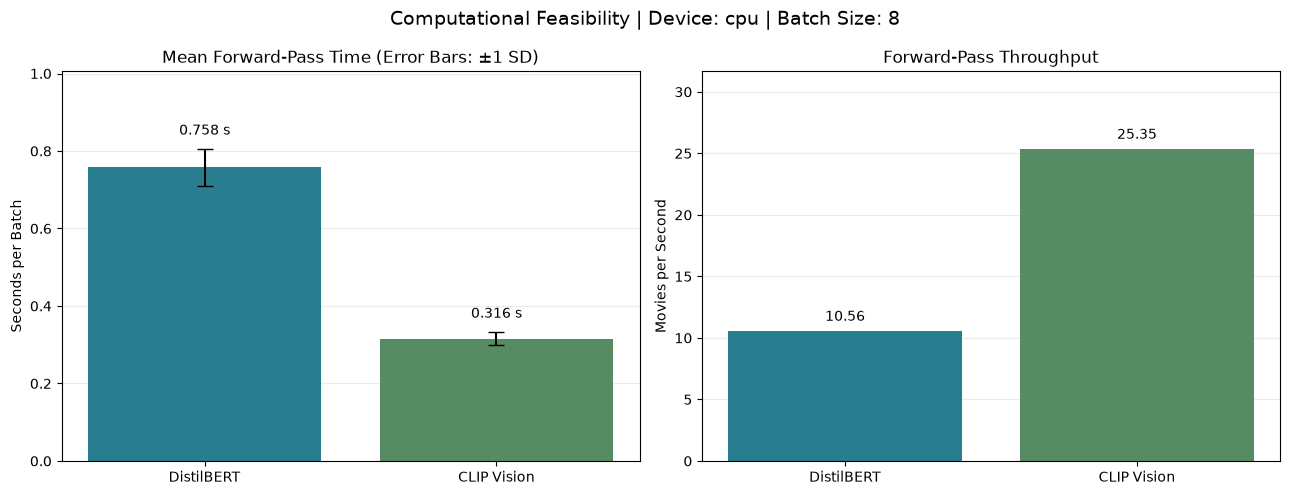

In [21]:
# If psutil is missing, run %pip install psutil in a separate cell first.
import gc
import time
import platform
import threading
import psutil
from transformers import AutoModel, CLIPVisionModel
# Reuse the split, preprocessing function and pinned models from Part 6.
required_variables = [
    "records", "train_idx", "split_indices", "preprocess_batch",
    "TEXT_MODEL_ID", "IMAGE_MODEL_ID", "TEXT_REVISION", "IMAGE_REVISION",
    "MAX_LENGTH", "SEED"
]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise RuntimeError("Run Part 6 first. Missing: " + ", ".join(missing_variables))
# Use a small training batch and repeated forward passes without training.
FEASIBILITY_BATCH_SIZE = 8
WARMUP_RUNS = 3
TIMED_RUNS = 10
RAM_SAMPLE_INTERVAL = 0.02
torch.manual_seed(SEED)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
process = psutil.Process()
system_memory = psutil.virtual_memory()
# Report the device available to this PyTorch installation.
environment_info = {
    "Operating system": platform.platform(),
    "CPU": platform.processor() or platform.machine(),
    "Logical CPU cores": psutil.cpu_count(logical=True),
    "PyTorch CPU threads": torch.get_num_threads(),
    "PyTorch version": torch.__version__,
    "Transformers version": transformers.__version__,
    "CUDA build version": torch.version.cuda or "Not included in this build",
    "CUDA available to PyTorch": torch.cuda.is_available(),
    "Selected device": str(device),
    "System RAM (GiB)": round(system_memory.total / 1024**3, 2),
    "Available system RAM (GiB)": round(system_memory.available / 1024**3, 2),
    "Current process RAM (GiB)": round(process.memory_info().rss / 1024**3, 2)
}
if device.type == "cuda":
    environment_info["GPU"] = torch.cuda.get_device_name(device)
    environment_info["GPU capacity (GiB)"] = round(
        torch.cuda.get_device_properties(device).total_memory / 1024**3, 2
    )
environment_df = pd.DataFrame(environment_info.items(), columns=["Property", "Value"])
print("COMPUTATIONAL ENVIRONMENT")
display(environment_df)
if device.type == "cpu":
    print("Using CPU because CUDA is unavailable to this PyTorch installation.")
# Load encoder weights once; the first run may download files.
# Keep both models on CPU initially and test one encoder at a time.
print("\nLoading DistilBERT encoder ...", flush=True)
text_model = AutoModel.from_pretrained(TEXT_MODEL_ID, revision=TEXT_REVISION)
text_model = text_model.to("cpu").float().eval().requires_grad_(False)
print("Loading CLIP vision encoder ...", flush=True)
image_model = CLIPVisionModel.from_pretrained(IMAGE_MODEL_ID, revision=IMAGE_REVISION)
image_model = image_model.to("cpu").float().eval().requires_grad_(False)
# Preserve the feature representations used in the proposal feasibility test.
model_summary_df = pd.DataFrame([
    {
        "Encoder": "DistilBERT",
        "Representation": "First token hidden state",
        "Feature dimension": text_model.config.dim,
        "Parameters (millions)": sum(p.numel() for p in text_model.parameters()) / 1e6,
        "Trainable parameters": sum(
            p.numel() for p in text_model.parameters() if p.requires_grad
        )
    },
    {
        "Encoder": "CLIP Vision",
        "Representation": "Vision pooler output",
        "Feature dimension": image_model.config.hidden_size,
        "Parameters (millions)": sum(p.numel() for p in image_model.parameters()) / 1e6,
        "Trainable parameters": sum(
            p.numel() for p in image_model.parameters() if p.requires_grad
        )
    }
])
print("\nENCODER CONFIGURATION")
display(model_summary_df.round(2))
# Prepare aligned text, image and label tensors from training rows only.
feasibility_indices = np.asarray(train_idx[:FEASIBILITY_BATCH_SIZE], dtype=np.int64)
if len(feasibility_indices) == 0:
    raise ValueError("The training split is empty.")
feasibility_text_inputs, feasibility_image_inputs, feasibility_labels = (
    preprocess_batch(feasibility_indices)
)
actual_batch_size = len(feasibility_indices)
print("\nTraining rows used:", feasibility_indices.tolist())
print("Warm-up runs per encoder:", WARMUP_RUNS)
print("Timed runs per encoder:", TIMED_RUNS)
input_summary_df = pd.DataFrame([
    {
        "Tensor": name,
        "Shape": str(tuple(tensor.shape)),
        "Data type": str(tensor.dtype),
        "All finite": bool(torch.isfinite(tensor).all().item())
    }
    for name, tensor in {
        **feasibility_text_inputs,
        **feasibility_image_inputs,
        "labels": feasibility_labels
    }.items()
])
print("\nBENCHMARK INPUTS")
display(input_summary_df)
if not input_summary_df["All finite"].all():
    raise ValueError("Non-finite values were found in the input batch.")
# Synchronise CUDA so timing includes completed GPU work.
def synchronise_device():
    if device.type == "cuda":
        torch.cuda.synchronize(device)
# Extract features without gradients, dropout or classifier training.
@torch.inference_mode()
def extract_batch_features(model, inputs, modality):
    outputs = model(**inputs)
    if modality == "text":
        features = outputs.last_hidden_state[:, 0, :]
    else:
        features = outputs.pooler_output
    return features.contiguous()
# Benchmark forward passes separately from preprocessing and data transfers.
def benchmark_encoder(name, model, cpu_inputs, modality, expected_dimension):
    device_inputs = {}
    features_device = None
    try:
        model.to(device)
        device_inputs = {key: value.to(device) for key, value in cpu_inputs.items()}
        print(f"\n{name}: running {WARMUP_RUNS} warm-up passes ...", flush=True)
        for _ in range(WARMUP_RUNS):
            features_device = extract_batch_features(model, device_inputs, modality)
            del features_device
            features_device = None
        synchronise_device()
        durations = []
        for run in range(1, TIMED_RUNS + 1):
            synchronise_device()
            start = time.perf_counter()
            features_device = extract_batch_features(model, device_inputs, modality)
            synchronise_device()
            elapsed = time.perf_counter() - start
            durations.append(elapsed)
            del features_device
            features_device = None
            print(f"{name} | Run {run:02d}/{TIMED_RUNS}: {elapsed:.4f} seconds", flush=True)
        # Measure memory in a separate warmed-up pass to avoid polling during timing.
        gc.collect()
        synchronise_device()
        rss_before = process.memory_info().rss
        rss_samples = [rss_before]
        stop_sampling = threading.Event()
        def sample_process_ram():
            while not stop_sampling.wait(RAM_SAMPLE_INTERVAL):
                rss_samples.append(process.memory_info().rss)
        if device.type == "cuda":
            torch.cuda.reset_peak_memory_stats(device)
            gpu_baseline = torch.cuda.memory_allocated(device)
        else:
            gpu_baseline = np.nan
        sampler = threading.Thread(target=sample_process_ram, daemon=True)
        sampler.start()
        try:
            features_device = extract_batch_features(model, device_inputs, modality)
            synchronise_device()
        finally:
            stop_sampling.set()
            sampler.join()
            rss_samples.append(process.memory_info().rss)
        gpu_peak = (
            torch.cuda.max_memory_allocated(device)
            if device.type == "cuda" else np.nan
        )
        # Validate and retain only the small feature batch on CPU.
        features_cpu = features_device.detach().cpu().clone()
        if tuple(features_cpu.shape) != (actual_batch_size, expected_dimension):
            raise ValueError(f"{name}: unexpected feature shape {tuple(features_cpu.shape)}.")
        if not torch.isfinite(features_cpu).all().item():
            raise ValueError(f"{name}: non-finite embeddings detected.")
        times = np.asarray(durations, dtype=np.float64)
        timing_summary = {
            "Encoder": name,
            "Device": str(device),
            "Batch size": actual_batch_size,
            "Mean batch time (s)": float(times.mean()),
            "Std batch time (s)": float(times.std(ddof=1)),
            "Median batch time (s)": float(np.median(times)),
            "Throughput (movies/s)": float(actual_batch_size / times.mean())
        }
        memory_summary = {
            "Encoder": name,
            "Process RAM before probe (MiB)": rss_before / 1024**2,
            "Sampled peak process RAM (MiB)": max(rss_samples) / 1024**2,
            "GPU allocated before probe (MiB)": gpu_baseline / 1024**2,
            "Peak GPU allocated (MiB)": gpu_peak / 1024**2,
            "Additional GPU peak (MiB)": (gpu_peak - gpu_baseline) / 1024**2
        }
        run_rows = [
            {"Encoder": name, "Run": run, "Batch time (s)": duration}
            for run, duration in enumerate(durations, start=1)
        ]
        return timing_summary, memory_summary, features_cpu, run_rows
    finally:
        # Release device inputs and return the encoder to CPU for the next stage.
        features_device = None
        device_inputs.clear()
        model.to("cpu")
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
# Test the two modalities independently using the same movie rows.
feasibility_rows = []
memory_rows = []
run_rows = []
feasibility_embeddings = {}
encoder_specs = [
    ("DistilBERT", text_model, feasibility_text_inputs, "text", text_model.config.dim),
    ("CLIP Vision", image_model, feasibility_image_inputs, "image", image_model.config.hidden_size)
]
for name, model, inputs, modality, dimension in encoder_specs:
    timing, memory, embeddings, measured_runs = benchmark_encoder(
        name, model, inputs, modality, dimension
    )
    feasibility_rows.append(timing)
    memory_rows.append(memory)
    run_rows.extend(measured_runs)
    feasibility_embeddings[modality] = embeddings
feasibility_results_df = pd.DataFrame(feasibility_rows)
feasibility_memory_df = pd.DataFrame(memory_rows)
feasibility_runs_df = pd.DataFrame(run_rows)
embedding_summary_df = pd.DataFrame([
    {
        "Modality": modality,
        "Embedding shape": str(tuple(embeddings.shape)),
        "Data type": str(embeddings.dtype),
        "All finite": bool(torch.isfinite(embeddings).all().item())
    }
    for modality, embeddings in feasibility_embeddings.items()
])
print("\nEMBEDDING CHECKS")
display(embedding_summary_df)
print("\nFORWARD-PASS TIMING AND THROUGHPUT")
display(feasibility_results_df.round(4))
print("Timing excludes model loading, preprocessing, data transfers and file writing.")
print("\nMEMORY MEASUREMENTS")
display(feasibility_memory_df.round(2).fillna("N/A"))
print("Process RAM includes the dataset, loaded models, libraries and other notebook objects.")
print("Sampled peak RAM is approximate; short spikes may be missed.")
print("GPU figures describe PyTorch tensor allocations in this process, not total GPU usage.")
print("Memory was measured after warm-up; GPU columns are N/A when running on CPU.")
# Estimate encoder-only processing time without extracting the full dataset.
mean_times = feasibility_results_df.set_index("Encoder")["Mean batch time (s)"]
estimate_rows = []
for split_name, indices in split_indices.items():
    batches = int(np.ceil(len(indices) / actual_batch_size))
    text_minutes = batches * mean_times["DistilBERT"] / 60
    image_minutes = batches * mean_times["CLIP Vision"] / 60
    estimate_rows.append({
        "Split": split_name,
        "Movies": len(indices),
        "Estimated text forward (min)": text_minutes,
        "Estimated image forward (min)": image_minutes,
        "Estimated combined forward (min)": text_minutes + image_minutes
    })
feasibility_estimates_df = pd.DataFrame(estimate_rows)
print("\nAPPROXIMATE ENCODER-ONLY TIME BY SPLIT")
display(feasibility_estimates_df.round(2))
print("These are extrapolations from one batch, not measured full-extraction times.")
print("Full extraction also includes preprocessing, transfers and saving features.")
# Visualise measured batch latency and throughput for the two encoders.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
encoder_names = feasibility_results_df["Encoder"]
colours = ["#287D8E", "#578B63"]
bars = axes[0].bar(
    encoder_names, feasibility_results_df["Mean batch time (s)"],
    yerr=feasibility_results_df["Std batch time (s)"],
    capsize=6, color=colours
)
axes[0].bar_label(bars, fmt="%.3f s", padding=8)
axes[0].set_ylabel("Seconds per Batch")
axes[0].set_title("Mean Forward-Pass Time (Error Bars: ±1 SD)")
bars = axes[1].bar(
    encoder_names, feasibility_results_df["Throughput (movies/s)"], color=colours
)
axes[1].bar_label(bars, fmt="%.2f", padding=5)
axes[1].set_ylabel("Movies per Second")
axes[1].set_title("Forward-Pass Throughput")
for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)
    ax.margins(y=0.25)
fig.suptitle(
    f"Computational Feasibility | Device: {device} | Batch Size: {actual_batch_size}",
    fontsize=14
)
fig.tight_layout()
plt.show()
# Retain the benchmark settings and results for later reporting.
feasibility_config = {
    "device": str(device),
    "batch_size": actual_batch_size,
    "warmup_runs": WARMUP_RUNS,
    "timed_runs": TIMED_RUNS,
    "dtype": "float32",
    "max_length": MAX_LENGTH,
    "text_pooling": "First token hidden state",
    "image_pooling": "Vision pooler output",
    "cpu_threads": torch.get_num_threads(),
    "ram_sampling_interval_seconds": RAM_SAMPLE_INTERVAL,
    "training_rows": feasibility_indices.tolist()
}

Both frozen encoders successfully processed eight movies on CPU using eight PyTorch threads. CUDA was unavailable in the installed PyTorch build. Text and image embeddings both had shape (8, 768), with all values finite. DistilBERT averaged 0.7577 seconds per batch, achieving 10.5578 movies/second. CLIP Vision was faster in this benchmark, averaging 0.3156 seconds per batch and 25.3471 movies/second. Sampled peak process RAM was 949.32 MiB during the DistilBERT probe and 1,262.62 MiB during the CLIP probe. These measurements include other notebook objects and do not isolate encoder memory. Estimated combined encoder processing times were 34.85 minutes for training, 5.81 minutes for validation and 17.41 minutes for testing. These estimates are extrapolated from one batch and exclude model loading, preprocessing, data transfers and file writing.

### 8. Full feature extraction:

Available features are cached from previous calls to memory or the cache. Features are extracted by frozen DistilBERT and CLIP encoders. The encoded features are 768-dimensional vectors that are extracted in batches of eight features. The first-token hidden state of Text features and the vision pooler output of Image features are used as feature representations. Features are stored in memory-mapped float32 arrays to prevent unnecessary memory copies. Numerical validity, alignment and variability on the training set are assessed and stored as diagnostic tables and visualizations for reporting purposes.


FULL FEATURE EXTRACTION SUMMARY


,Split,Modality,Movies,Status,Processing time (s),Processing time (min)
0,train,text,15581,Loaded from cache,1727.4172,28.7903
1,validation,text,2595,Loaded from cache,1768.2722,29.4712
2,test,text,7783,Loaded from cache,30681.5271,511.3588
3,train,image,15581,Loaded from cache,9448.4829,157.4747
4,validation,image,2595,Loaded from cache,113.5094,1.8918
5,test,image,7783,Loaded from cache,4138.5261,68.9754


Feature dimensions: {'text': 768, 'image': 768}
Cache directory: mmimdb_features\v2_317223387d28dbac\feature_cache\e842d52851f771f2
Cached rows retain their original extraction times.
Loading cached arrays is not reported as a new extraction.
New extraction times include preprocessing, inference and feature writes.
Model loading is excluded from these extraction times.

FEATURE INTEGRITY AND EXTRACTION SUMMARY


,Split,Modality,Feature shape,Non-finite values,Zero vectors,Rows and labels aligned,Array storage (MiB),Recorded extraction (s)
0,train,Image,"(15581, 768)",0,0,True,45.6475,9448.4829
1,train,Text,"(15581, 768)",0,0,True,45.6475,1727.4172
2,validation,Image,"(2595, 768)",0,0,True,7.6025,113.5094
3,validation,Text,"(2595, 768)",0,0,True,7.6025,1768.2722
4,test,Image,"(7783, 768)",0,0,True,22.8018,4138.5261
5,test,Text,"(7783, 768)",0,0,True,22.8018,30681.5271


Array storage describes feature elements only, not process RAM or encoder memory.

TRAINING FEATURE VARIABILITY
Near-constant threshold: population standard deviation <= 1e-08


,Modality,Training movies,Feature dimensions,Near-constant features,Minimum feature std,Median feature std,Maximum feature std
0,Image,15581,768,0,0.459066,0.603991,2.625090
1,Text,15581,768,0,0.100844,0.138588,0.528345



TRAINING EMBEDDING L2 NORMS


,Modality,Minimum,Mean,Median,Maximum,Population std
0,Image,24.4636,26.1734,26.1216,28.4923,0.5598
1,Text,10.5319,12.1316,12.1194,14.6579,0.4396


Image near-constant feature indices (up to 20): []
Text near-constant feature indices (up to 20): []

TRAINING TOKEN LENGTHS BEFORE TRUNCATION


,Training plots,Minimum tokens,Mean tokens,Median tokens,Maximum tokens,Token limit,Plots requiring truncation,Truncated plots (%)
0,15581,3,136.42,117.0,1999,256,1621,10.4


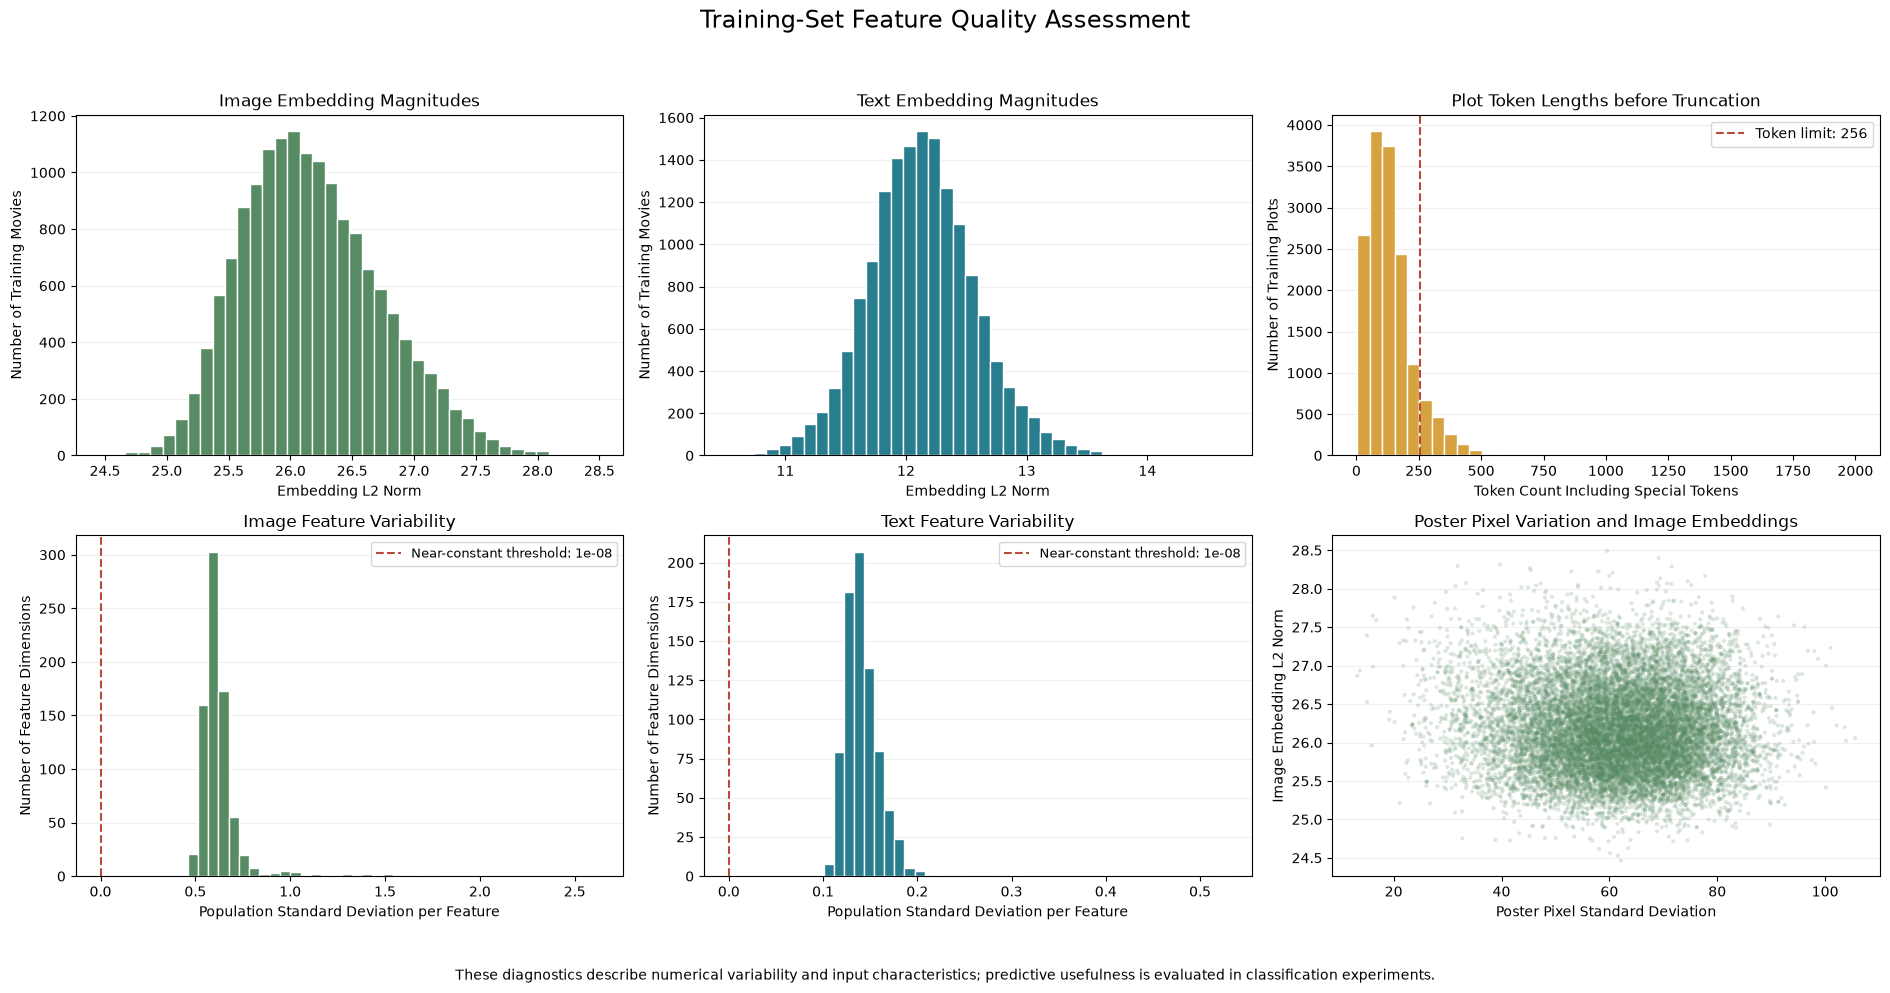


SAVED QUALITY-ASSESSMENT FILES
 - mmimdb_features\v2_317223387d28dbac\quality_assessment\feature_integrity.csv
 - mmimdb_features\v2_317223387d28dbac\quality_assessment\training_feature_variability.csv
 - mmimdb_features\v2_317223387d28dbac\quality_assessment\training_embedding_norms.csv
 - mmimdb_features\v2_317223387d28dbac\quality_assessment\training_feature_columns.csv
 - mmimdb_features\v2_317223387d28dbac\quality_assessment\training_token_summary.csv
 - mmimdb_features\v2_317223387d28dbac\quality_assessment\training_movie_diagnostics.csv
 - mmimdb_features\v2_317223387d28dbac\quality_assessment\training_feature_quality.png


In [40]:
from pathlib import Path
from time import perf_counter
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
# Reuse the data, split indices and preprocessing settings from Parts 1–6.
required = [
    "records", "images", "labels", "split_indices", "cleaned_summaries",
    "image_hashes", "preprocessing_config", "text_tokenizer", "image_processor",
    "token_lengths", "MAX_LENGTH", "image_quality_df"
]
missing = [name for name in required if name not in globals()]
if missing:
    raise RuntimeError("Run Parts 1–6 first. Missing: " + ", ".join(missing))
if MAX_LENGTH != preprocessing_config["max_length"]:
    raise ValueError("MAX_LENGTH differs from the preprocessing configuration.")
BATCH_SIZE = 8
feature_dimensions = {"text": 768, "image": 768}
extraction_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Use the feature directory associated with the reported experiment.
FEATURE_DIR = Path("mmimdb_features") / "v2_317223387d28dbac"
# Identify the inputs and settings without hashing all poster pixels again.
cache_config = {
    "format_version": 1,
    "preprocessing": preprocessing_config,
    "text_pooling": "First token hidden state",
    "image_pooling": "Vision pooler output",
    "dimensions": feature_dimensions,
    "dtype": "float32",
    "batch_size": BATCH_SIZE,
    "device": str(extraction_device),
    "image_shape": list(images.shape)
}
cache_hash = hashlib.sha256(json.dumps(cache_config, sort_keys=True).encode())
for row in range(len(records)):
    item = [str(records[row, 0]), cleaned_summaries[row], str(image_hashes[row])]
    cache_hash.update(json.dumps(item, ensure_ascii=False).encode("utf-8"))
cache_hash.update(np.asarray(labels, dtype=np.float32).tobytes())
for split_name, rows in split_indices.items():
    cache_hash.update(split_name.encode())
    cache_hash.update(np.asarray(rows, dtype=np.int64).tobytes())
cache_signature = cache_hash.hexdigest()
CACHE_DIR = FEATURE_DIR / "feature_cache" / cache_signature[:16]
CACHE_DIR.mkdir(parents=True, exist_ok=True)
manifest_path = CACHE_DIR / "manifest.json"
# Write JSON through a temporary file so interrupted writes are not accepted.
def save_cache_manifest(manifest):
    temporary = manifest_path.with_suffix(".json.part")
    temporary.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
    temporary.replace(manifest_path)
if manifest_path.is_file():
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    if manifest["signature"] != cache_signature:
        raise ValueError("Cached settings do not match this experiment.")
else:
    manifest = {"signature": cache_signature, "config": cache_config, "completed": {}}
    save_cache_manifest(manifest)
# Validate feature blocks without creating a full-sized temporary copy.
def check_feature_matrix(matrix, expected_rows, modality):
    if matrix.shape != (expected_rows, feature_dimensions[modality]):
        raise ValueError(f"Incorrect {modality} feature shape: {matrix.shape}")
    if matrix.dtype != np.float32:
        raise ValueError(f"{modality} features must use float32.")
    for start in range(0, expected_rows, 1024):
        if not np.isfinite(matrix[start:start + 1024]).all():
            raise ValueError(f"Non-finite {modality} features detected.")
# Reuse current features only from the same experiment.
# Existing features do not require another encoder pass.
existing_features = globals().get("feature_data")
if existing_features is not None and globals().get("_part8_signature", cache_signature) != cache_signature:
    raise ValueError("Settings changed. Set feature_data = None before extracting new features.")
existing_times = globals().get("extraction_times_df")
recorded_seconds = {}
if existing_times is not None:
    for _, item in existing_times.iterrows():
        recorded_seconds[
            (item["Split"], str(item["Modality"]).lower())
        ] = float(item["Processing time (s)"])
expected_metadata = {}
for split_name, rows in split_indices.items():
    rows = np.asarray(rows, dtype=np.int64)
    expected = {
        "row_indices": rows,
        "movie_ids": np.asarray([str(records[row, 0]) for row in rows]),
        "labels": np.asarray(labels[rows], dtype=np.float32)
    }
    expected_metadata[split_name] = expected
    if existing_features is not None:
        current = existing_features[split_name]
        if not all(np.array_equal(current[key], value) for key, value in expected.items()):
            raise ValueError(f"Existing features are misaligned: {split_name}")
        for modality in feature_dimensions:
            check_feature_matrix(current[modality], len(rows), modality)
    # Store small alignment arrays separately from the feature matrices.
    for key, value in expected.items():
        path = CACHE_DIR / f"{split_name}_{key}.npy"
        if path.is_file():
            if not np.array_equal(np.load(path, allow_pickle=False), value):
                raise ValueError(f"Cached metadata differs: {path.name}")
        else:
            with path.with_suffix(".npy.part").open("wb") as file:
                np.save(file, value, allow_pickle=False)
            path.with_suffix(".npy.part").replace(path)
if existing_features is not None:
    del current
# Extract only the requested modality to avoid unnecessary preprocessing.
def extract_feature_matrix(model, modality, rows, temporary_path):
    matrix = np.lib.format.open_memmap(
        temporary_path, mode="w+", dtype=np.float32,
        shape=(len(rows), feature_dimensions[modality])
    )
    model.to(extraction_device).float().eval().requires_grad_(False)
    if extraction_device.type == "cuda":
        torch.cuda.synchronize(extraction_device)
    start_time = perf_counter()
    try:
        with torch.inference_mode():
            for start in range(0, len(rows), BATCH_SIZE):
                end = min(start + BATCH_SIZE, len(rows))
                batch_rows = rows[start:end]
                if modality == "text":
                    inputs = text_tokenizer(
                        [cleaned_summaries[int(row)] for row in batch_rows],
                        padding="max_length", truncation=True,
                        max_length=preprocessing_config["max_length"],
                        return_token_type_ids=False, return_tensors="pt"
                    )
                else:
                    inputs = image_processor(
                        images=[
                            np.moveaxis(images[int(row)], 0, -1)
                            for row in batch_rows
                        ],
                        input_data_format="channels_last", return_tensors="pt"
                    )
                inputs = {
                    key: value.to(extraction_device)
                    for key, value in inputs.items()
                }
                outputs = model(**inputs)
                # Preserve the representations benchmarked in Part 7.
                if modality == "text":
                    features = outputs.last_hidden_state[:, 0, :]
                else:
                    features = outputs.pooler_output
                block = features.cpu().numpy().astype(np.float32, copy=False)
                check_feature_matrix(block, end - start, modality)
                # Write batches directly to disk instead of accumulating a list.
                matrix[start:end] = block
                del inputs, outputs, features, block
                if (start // BATCH_SIZE + 1) % 100 == 0 or end == len(rows):
                    print(
                        f"{modality.title()}: {end:,} / {len(rows):,} movies",
                        flush=True
                    )
        matrix.flush()
        seconds = perf_counter() - start_time
    finally:
        # Release the file mapping before renaming it on Windows.
        del matrix
        model.to("cpu")
        if extraction_device.type == "cuda":
            torch.cuda.empty_cache()
    return seconds
extraction_rows = []
# Complete one matrix at a time and reuse completed matrices after interruptions.
for modality in ["text", "image"]:
    model = None
    for split_name, expected in expected_metadata.items():
        rows = expected["row_indices"]
        key = f"{split_name}_{modality}"
        path = CACHE_DIR / f"{key}.npy"
        temporary_path = path.with_suffix(".part.npy")
        if path.is_file() and key in manifest["completed"]:
            seconds = manifest["completed"][key]["seconds"]
            status = "Loaded from cache"
        else:
            if existing_features is not None:
                # Save current embeddings once and retain their original timings.
                with temporary_path.open("wb") as file:
                    np.save(
                        file, existing_features[split_name][modality],
                        allow_pickle=False
                    )
                seconds = recorded_seconds.get((split_name, modality), np.nan)
                status = "Saved existing features"
            else:
                if model is None:
                    model = globals().get(f"{modality}_model")
                    if model is None:
                        raise RuntimeError("Run Part 7 first to load the frozen encoders.")
                print(f"\nExtracting {split_name} / {modality} ...", flush=True)
                seconds = extract_feature_matrix(
                    model, modality, rows, temporary_path
                )
                status = "New extraction"
            temporary_path.replace(path)
            # Missing historical times remain unavailable rather than becoming zero.
            manifest["completed"][key] = {
                "seconds": seconds if np.isfinite(seconds) else None
            }
            save_cache_manifest(manifest)
        extraction_rows.append({
            "Split": split_name,
            "Modality": modality,
            "Movies": len(rows),
            "Status": status,
            "Processing time (s)": np.nan if seconds is None else seconds
        })
# Open features read-only using memory mapping to limit unnecessary RAM copies.
# Preserve the feature_data structure required by Parts 9–12.
prepared_features = {}
for split_name, expected in expected_metadata.items():
    prepared_features[split_name] = dict(expected)
    for modality in feature_dimensions:
        matrix = np.load(
            CACHE_DIR / f"{split_name}_{modality}.npy",
            mmap_mode="r", allow_pickle=False
        )
        check_feature_matrix(matrix, len(expected["row_indices"]), modality)
        prepared_features[split_name][modality] = matrix
feature_data = prepared_features
_part8_signature = cache_signature
extraction_times_df = pd.DataFrame(extraction_rows)
extraction_times_df["Processing time (min)"] = (
    extraction_times_df["Processing time (s)"] / 60
)
extraction_times_df.to_csv(CACHE_DIR / "extraction_times.csv", index=False)
# Release the temporary reference to old in-memory features after saving.
del existing_features
print("\nFULL FEATURE EXTRACTION SUMMARY")
display(extraction_times_df.round(4))
print("Feature dimensions:", feature_dimensions)
print("Cache directory:", CACHE_DIR)
print("Cached rows retain their original extraction times.")
print("Loading cached arrays is not reported as a new extraction.")
print("New extraction times include preprocessing, inference and feature writes.")
print("Model loading is excluded from these extraction times.")
# Configure the existing feature-quality assessment.
NEAR_CONSTANT_THRESHOLD = 1e-8
QUALITY_BLOCK_SIZE = 1024
QUALITY_DIR = Path(FEATURE_DIR) / "quality_assessment"
QUALITY_DIR.mkdir(parents=True, exist_ok=True)
# Reuse measured extraction times without running either encoder again.
recorded_times = extraction_times_df.set_index(
    ["Split", "Modality"]
)["Processing time (s)"]
if not recorded_times.index.is_unique:
    raise ValueError("Duplicate extraction-time entries found.")
integrity_rows = []
# Check feature structure, numerical values and alignment in every split.
for split_name, indices in split_indices.items():
    arrays = feature_data[split_name]
    indices = np.asarray(indices, dtype=np.int64)
    expected_ids = np.asarray([str(records[i, 0]) for i in indices])
    aligned = (
        np.array_equal(arrays["row_indices"], indices)
        and np.array_equal(arrays["movie_ids"], expected_ids)
        and np.array_equal(arrays["labels"], labels[indices])
    )
    for modality in ["image", "text"]:
        matrix = arrays[modality]
        expected_shape = (len(indices), feature_dimensions[modality])
        if matrix.ndim != 2 or matrix.shape != expected_shape:
            raise ValueError(f"Unexpected feature shape: {split_name} / {modality}")
        if matrix.dtype != np.float32:
            raise ValueError(f"Expected float32 features: {split_name} / {modality}")
        non_finite_count = 0
        zero_vector_count = 0
        for start in range(0, len(indices), QUALITY_BLOCK_SIZE):
            block = matrix[start:start + QUALITY_BLOCK_SIZE]
            non_finite_count += int((~np.isfinite(block)).sum())
            zero_vector_count += int(np.all(block == 0, axis=1).sum())
        integrity_rows.append({
            "Split": split_name,
            "Modality": modality.title(),
            "Feature shape": str(matrix.shape),
            "Non-finite values": non_finite_count,
            "Zero vectors": zero_vector_count,
            "Rows and labels aligned": aligned,
            "Array storage (MiB)": matrix.nbytes / 1024**2,
            "Recorded extraction (s)": float(
                recorded_times.loc[(split_name, modality)]
            )
        })
feature_integrity_df = pd.DataFrame(integrity_rows)
print("\nFEATURE INTEGRITY AND EXTRACTION SUMMARY")
display(feature_integrity_df.round(4))
if (
    feature_integrity_df["Non-finite values"].sum() != 0
    or not feature_integrity_df["Rows and labels aligned"].all()
):
    raise ValueError("Resolve non-finite values or alignment errors before further analysis.")
print("Array storage describes feature elements only, not process RAM or encoder memory.")
# Use training features for variability analysis and visual inspection.
training_arrays = feature_data["train"]
training_rows = np.asarray(training_arrays["row_indices"], dtype=np.int64)
if len(training_rows) < 2:
    raise ValueError("At least two training movies are required for variability analysis.")
# Calculate statistics in blocks to avoid copying a full feature matrix.
def training_feature_statistics(matrix):
    n_samples, n_features = matrix.shape
    column_sums = np.zeros(n_features, dtype=np.float64)
    vector_norms = np.empty(n_samples, dtype=np.float64)
    for start in range(0, n_samples, QUALITY_BLOCK_SIZE):
        end = min(start + QUALITY_BLOCK_SIZE, n_samples)
        block = np.asarray(matrix[start:end], dtype=np.float64)
        column_sums += block.sum(axis=0)
        vector_norms[start:end] = np.linalg.norm(block, axis=1)
    column_means = column_sums / n_samples
    squared_deviations = np.zeros(n_features, dtype=np.float64)
    # A second pass computes population standard deviations around the means.
    for start in range(0, n_samples, QUALITY_BLOCK_SIZE):
        block = np.array(
            matrix[start:start + QUALITY_BLOCK_SIZE],
            dtype=np.float64, copy=True
        )
        block -= column_means
        np.square(block, out=block)
        squared_deviations += block.sum(axis=0)
    column_stds = np.sqrt(squared_deviations / n_samples)
    return column_means, column_stds, vector_norms
training_feature_stats = {}
variability_rows = []
norm_rows = []
column_tables = []
for modality in ["image", "text"]:
    matrix = training_arrays[modality]
    means, stds, norms = training_feature_statistics(matrix)
    near_constant = stds <= NEAR_CONSTANT_THRESHOLD
    training_feature_stats[modality] = {
        "means": means,
        "stds": stds,
        "norms": norms,
        "near_constant": near_constant
    }
    variability_rows.append({
        "Modality": modality.title(),
        "Training movies": matrix.shape[0],
        "Feature dimensions": matrix.shape[1],
        "Near-constant features": int(near_constant.sum()),
        "Minimum feature std": float(stds.min()),
        "Median feature std": float(np.median(stds)),
        "Maximum feature std": float(stds.max())
    })
    norm_rows.append({
        "Modality": modality.title(),
        "Minimum": float(norms.min()),
        "Mean": float(norms.mean()),
        "Median": float(np.median(norms)),
        "Maximum": float(norms.max()),
        "Population std": float(norms.std(ddof=0))
    })
    column_tables.append(pd.DataFrame({
        "Modality": modality.title(),
        "Feature index": np.arange(matrix.shape[1]),
        "Training mean": means,
        "Training population std": stds,
        "Near constant": near_constant
    }))
feature_variability_df = pd.DataFrame(variability_rows)
embedding_norm_summary_df = pd.DataFrame(norm_rows)
feature_column_statistics_df = pd.concat(column_tables, ignore_index=True)
print("\nTRAINING FEATURE VARIABILITY")
print(f"Near-constant threshold: population standard deviation <= {NEAR_CONSTANT_THRESHOLD:g}")
display(feature_variability_df.round(6))
print("\nTRAINING EMBEDDING L2 NORMS")
display(embedding_norm_summary_df.round(4))
for modality, statistics in training_feature_stats.items():
    flagged_columns = np.flatnonzero(statistics["near_constant"])
    print(
        f"{modality.title()} near-constant feature indices (up to 20):",
        flagged_columns[:20].tolist()
    )
# Align original poster statistics to feature rows using record-row identifiers.
poster_quality = image_quality_df.set_index("Record row")
if not poster_quality.index.is_unique:
    raise ValueError("Duplicate record rows in poster-quality statistics.")
training_poster_quality = poster_quality.loc[training_rows]
if not np.array_equal(
    training_poster_quality["Movie ID"].astype(str).to_numpy(),
    training_arrays["movie_ids"]
):
    raise ValueError("Poster-quality statistics do not match the training feature rows.")
training_pixel_std = training_poster_quality["Pixel std"].to_numpy(dtype=np.float64)
if not np.isfinite(training_pixel_std).all():
    raise ValueError("Poster pixel statistics contain non-finite values.")
# Reuse untruncated token counts from Part 6 rather than tokenising again.
if len(token_lengths) != len(records):
    raise ValueError("Token counts no longer match the original movie records.")
training_token_lengths = np.asarray(token_lengths)[training_rows]
truncated_training_count = int((training_token_lengths > MAX_LENGTH).sum())
training_token_summary_df = pd.DataFrame([{
    "Training plots": len(training_rows),
    "Minimum tokens": int(training_token_lengths.min()),
    "Mean tokens": float(training_token_lengths.mean()),
    "Median tokens": float(np.median(training_token_lengths)),
    "Maximum tokens": int(training_token_lengths.max()),
    "Token limit": MAX_LENGTH,
    "Plots requiring truncation": truncated_training_count,
    "Truncated plots (%)": truncated_training_count / len(training_rows) * 100
}])
print("\nTRAINING TOKEN LENGTHS BEFORE TRUNCATION")
display(training_token_summary_df.round(2))
# Keep per-movie diagnostics in the verified training feature order.
training_feature_diagnostics_df = pd.DataFrame({
    "Record row": training_rows,
    "Movie ID": training_arrays["movie_ids"],
    "Image embedding L2 norm": training_feature_stats["image"]["norms"],
    "Text embedding L2 norm": training_feature_stats["text"]["norms"],
    "Poster pixel std": training_pixel_std,
    "Tokens before truncation": training_token_lengths,
    "Truncation required": training_token_lengths > MAX_LENGTH
})
# Show embedding magnitudes, feature variability and input characteristics.
fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for column, modality, colour in [(0, "image", "#578B63"), (1, "text", "#287D8E")]:
    statistics = training_feature_stats[modality]
    axes[0, column].hist(
        statistics["norms"], bins=40, color=colour, edgecolor="white"
    )
    axes[0, column].set_title(f"{modality.title()} Embedding Magnitudes")
    axes[0, column].set_xlabel("Embedding L2 Norm")
    axes[0, column].set_ylabel("Number of Training Movies")
    axes[1, column].hist(
        statistics["stds"], bins=40, color=colour, edgecolor="white"
    )
    axes[1, column].axvline(
        NEAR_CONSTANT_THRESHOLD,
        color="#B84A39", linestyle="--",
        label=f"Near-constant threshold: {NEAR_CONSTANT_THRESHOLD:g}"
    )
    axes[1, column].set_title(f"{modality.title()} Feature Variability")
    axes[1, column].set_xlabel("Population Standard Deviation per Feature")
    axes[1, column].set_ylabel("Number of Feature Dimensions")
    axes[1, column].legend(fontsize=9)
# Token lengths describe input coverage, not semantic embedding quality.
axes[0, 2].hist(
    training_token_lengths, bins=40, color="#D6A340", edgecolor="white"
)
axes[0, 2].axvline(
    MAX_LENGTH, color="#B84A39", linestyle="--",
    label=f"Token limit: {MAX_LENGTH}"
)
axes[0, 2].set_title("Plot Token Lengths before Truncation")
axes[0, 2].set_xlabel("Token Count Including Special Tokens")
axes[0, 2].set_ylabel("Number of Training Plots")
axes[0, 2].legend()
# Inspect the relationship between stored pixel variation and image embeddings.
axes[1, 2].scatter(
    training_pixel_std,
    training_feature_stats["image"]["norms"],
    s=9, alpha=0.2, color="#578B63", edgecolors="none"
)
axes[1, 2].set_title("Poster Pixel Variation and Image Embeddings")
axes[1, 2].set_xlabel("Poster Pixel Standard Deviation")
axes[1, 2].set_ylabel("Image Embedding L2 Norm")
for ax in axes.flat:
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
fig.suptitle("Training-Set Feature Quality Assessment", fontsize=17, y=0.99)
fig.tight_layout(rect=[0, 0.065, 1, 0.96])
fig.text(
    0.5, 0.02,
    "These diagnostics describe numerical variability and input characteristics; "
    "predictive usefulness is evaluated in classification experiments.",
    ha="center", fontsize=10
)
figure_path = QUALITY_DIR / "training_feature_quality.png"
fig.savefig(figure_path, dpi=200, bbox_inches="tight")
plt.show()
# Save the diagnostic tables and figure without changing the extracted features.
diagnostic_tables = {
    "feature_integrity.csv": feature_integrity_df,
    "training_feature_variability.csv": feature_variability_df,
    "training_embedding_norms.csv": embedding_norm_summary_df,
    "training_feature_columns.csv": feature_column_statistics_df,
    "training_token_summary.csv": training_token_summary_df,
    "training_movie_diagnostics.csv": training_feature_diagnostics_df
}
for filename, table in diagnostic_tables.items():
    table.to_csv(QUALITY_DIR / filename, index=False)
print("\nSAVED QUALITY-ASSESSMENT FILES")
for filename in [*diagnostic_tables, figure_path.name]:
    print(" -", QUALITY_DIR / filename)

Both modalities were saved as 768-dimensional feature matrices (feat_matrix) for the training set of 15,581 movies, the validation set of 2,595 movies and the test set of 7,783 movies. All feature matrices contained zero non-finite values and no all-zero vectors. The processing times reported above were recorded during the feature extraction and thus do not correspond to the time it took to read the feature matrices from the cache. Moreover, the two modalities do not differ in terms of predictive superiority, but rather in terms of representation scale and variability. Before truncation, the average number of tokens in a training summary was 136.42 with a median of 117 tokens. 1,621 summaries (10.40%) of the training set exceeded the limit of 256 input tokens and had to be truncated in the following experiments. The figures show the embedding magnitudes, feature variability, number of tokens and the relation between poster pixel variation and image embedding magnitudes. These are the diagnostics that assess numerical integrity as opposed to predictive usefulness, which will be measured in the following classification experiments. 

### 9. Unimodal baselines:

For the text-only MLP and the image-only MLP we use cached 768-dimensional embeddings, Layer Normalization, 256 input units in the hidden layer and dropout. We use AdamW for training and binary cross-entropy as the loss in the positive class that is weighted by the training labels. We use Validation Macro-F1 at threshold 0.5 to select the best checkpoint and to trigger early stopping. A global threshold is then selected on the validation data for each model, and the learning curves, the corresponding metrics and the generated prediction probabilities are saved.

UNIMODAL TRAINING INPUTS


,Split,Modality,Feature shape,Label shape
0,train,Text,"(15581, 768)","(15581, 23)"
1,train,Image,"(15581, 768)","(15581, 23)"
2,validation,Text,"(2595, 768)","(2595, 23)"
3,validation,Image,"(2595, 768)","(2595, 23)"



TRAINING CONFIGURATION


,Setting,Value
0,seed,42
1,hidden_dim,256
2,dropout,0.3
3,batch_size,256
4,evaluation_batch_size,512
5,max_epochs,30
6,patience,5
7,learning_rate,0.001
8,weight_decay,0.0001
9,normalisation,LayerNorm per movie embedding



TRAINING CLASS WEIGHTS


,Genre,Training positives,Training negatives,Positive weight
0,Drama,8378,7203,0.859800
1,Comedy,5210,10371,1.990600
2,Romance,3259,12322,3.780900
3,Thriller,3136,12445,3.968400
4,Crime,2272,13309,5.857800
5,Action,2170,13411,6.180200
6,Adventure,1641,13940,8.494800
7,Horror,1564,14017,8.962300
8,Documentary,1260,14321,11.365900
9,Mystery,1220,14361,11.771300



TEXT-ONLY | Device: cpu | Trainable head parameters: 204,311
UnimodalMLP(
  (network): Sequential(
    (0): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (1): Linear(in_features=768, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=23, bias=True)
  )
)
Epoch 01 | Loss: train=0.7529, val=0.7420 | Macro-F1@0.5: train=0.3946, val=0.3977 | Val Micro-F1@0.5=0.4576 | Best checkpoint
Epoch 02 | Loss: train=0.6870, val=0.6849 | Macro-F1@0.5: train=0.4184, val=0.4196 | Val Micro-F1@0.5=0.4749 | Best checkpoint
Epoch 03 | Loss: train=0.6591, val=0.6628 | Macro-F1@0.5: train=0.4646, val=0.4689 | Val Micro-F1@0.5=0.5360 | Best checkpoint
Epoch 04 | Loss: train=0.6317, val=0.6410 | Macro-F1@0.5: train=0.4397, val=0.4386 | Val Micro-F1@0.5=0.4960
Epoch 05 | Loss: train=0.6207, val=0.6347 | Macro-F1@0.5: train=0.4570, val=0.4525 | Val Micro-F1@0.5=0.5141
Epoch 06 | Loss: train=0.6038, val=0.6264 |

,Model,Threshold,Macro-F1,Micro-F1
0,Text-only,0.05,0.2262,0.2627
1,Text-only,0.10,0.2646,0.3100
2,Text-only,0.15,0.2982,0.3503
3,Text-only,0.20,0.3291,0.3867
4,Text-only,0.25,0.3558,0.4180
5,Text-only,0.30,0.3816,0.4471
6,Text-only,0.35,0.4053,0.4737
7,Text-only,0.40,0.4309,0.4999
8,Text-only,0.45,0.4506,0.5179
9,Text-only,0.50,0.4708,0.5354



UNIMODAL VALIDATION RESULTS


,Model,Best epoch,Epochs run,Threshold,Val Macro-F1 @0.5,Val Micro-F1 @0.5,Train Macro-F1,Val Macro-F1,Val Micro-F1,Train-val Macro-F1 gap,Validation weighted BCE,Training loop (s)
0,Text-only,8,13,0.75,0.4708,0.5354,0.5386,0.5350,0.5409,0.0036,0.6154,11.2777
1,Image-only,9,14,0.60,0.2885,0.3484,0.3869,0.2974,0.3538,0.0895,1.0721,12.9324


Unqualified F1 columns use each model's selected threshold; @0.5 columns use 0.5.
The train-validation gap uses the same selected checkpoint and threshold.
Training-loop time includes epoch training and evaluation, but excludes feature extraction and final saving.


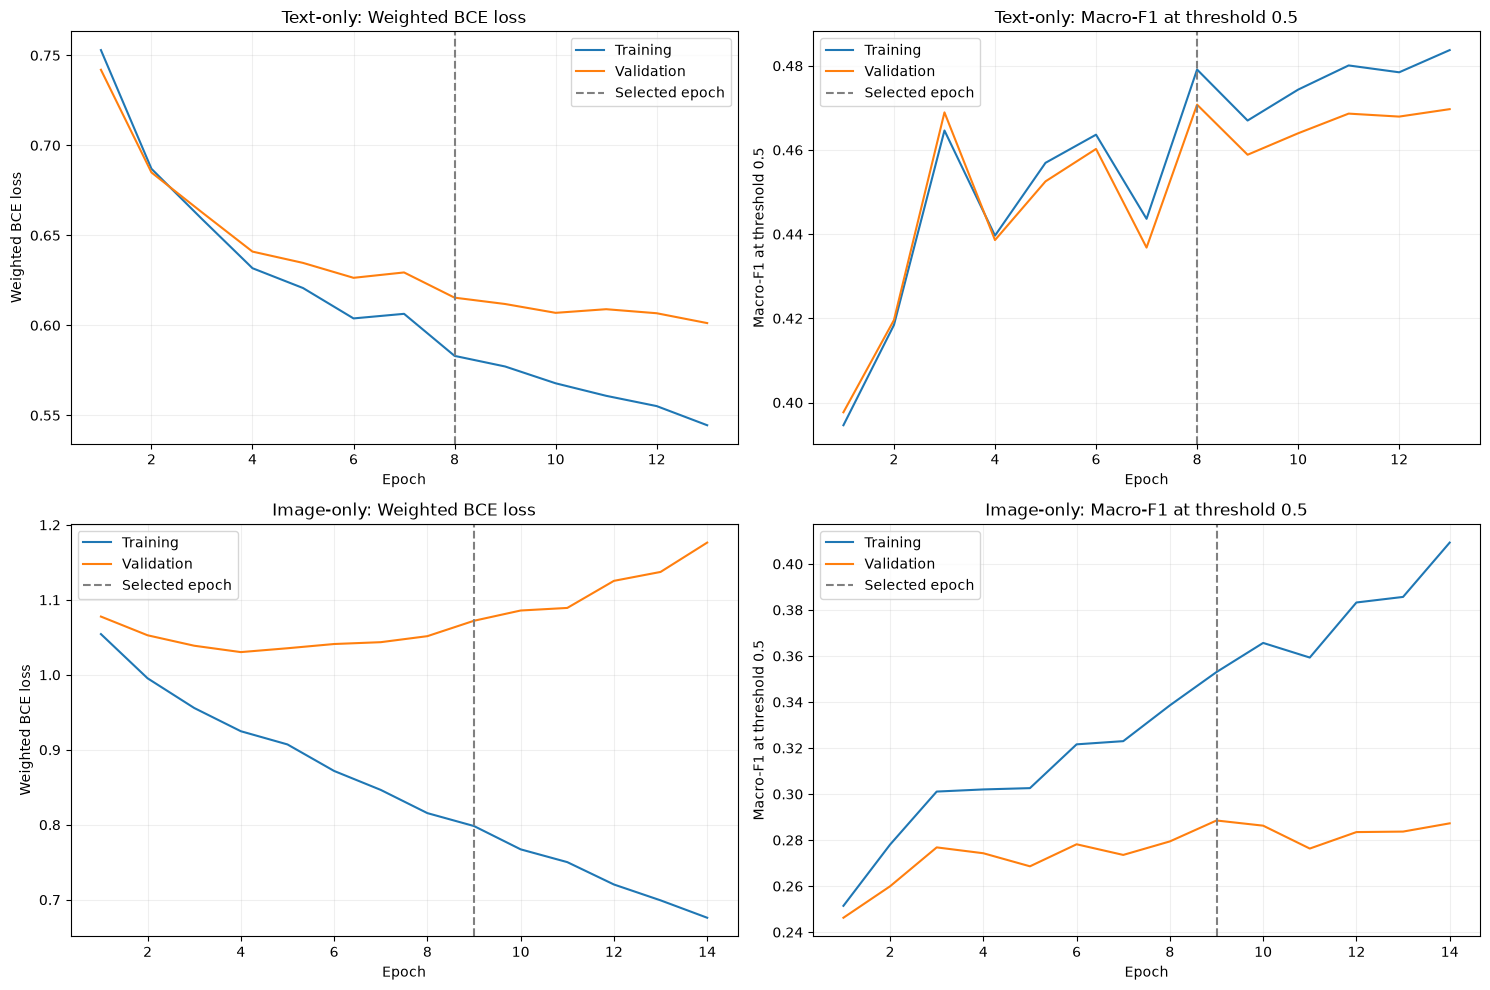

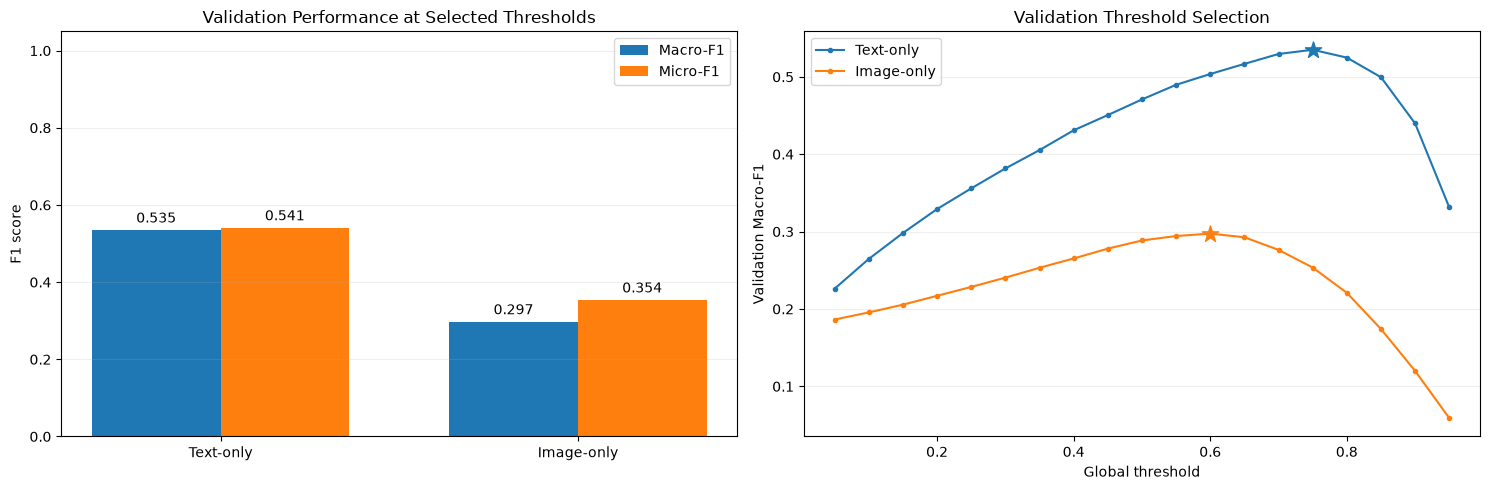


SAVED UNIMODAL RESULTS
 - class_weights.csv
 - image_best.pt
 - image_history.csv
 - image_threshold_search.csv
 - image_train_predictions.npz
 - image_validation_predictions.npz
 - text_best.pt
 - text_history.csv
 - text_threshold_search.csv
 - text_train_predictions.npz
 - text_validation_predictions.npz
 - threshold_search.csv
 - training_config.json
 - training_history.csv
 - unimodal_learning_curves.png
 - unimodal_validation_comparison.png
 - validation_results.csv


In [35]:
from pathlib import Path
from datetime import datetime
from time import perf_counter
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import f1_score
from IPython.display import display
# Use the complete feature matrices produced in Part 8.
required_variables = ["feature_data", "split_indices", "records", "labels", "genres", "FEATURE_DIR"]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise RuntimeError("Complete Part 8 first. Missing: " + ", ".join(missing_variables))
# Apply the same training settings to both modalities.
unimodal_config = {
    "seed": 42, "hidden_dim": 256, "dropout": 0.3,
    "batch_size": 256, "evaluation_batch_size": 512,
    "max_epochs": 30, "patience": 5,
    "learning_rate": 1e-3, "weight_decay": 1e-4,
    "normalisation": "LayerNorm per movie embedding",
    "optimizer": "AdamW", "loss": "BCEWithLogitsLoss",
    "positive_weight": "Training negatives / training positives",
    "checkpoint_metric": "Validation Macro-F1 at threshold 0.5",
    "threshold_grid": np.round(np.linspace(0.05, 0.95, 19), 2).tolist()
}
training_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
unimodal_config.update({
    "device": str(training_device),
    "torch_version": str(torch.__version__),
    "cpu_threads": torch.get_num_threads(),
    "feature_directory": str(Path(FEATURE_DIR).resolve()),
    "genres": list(genres)
})
# Keep each run in its own directory so earlier experiments remain available.
UNIMODAL_DIR = Path(FEATURE_DIR) / "unimodal_baselines" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
UNIMODAL_DIR.mkdir(parents=True, exist_ok=False)
# Validate only the training and validation inputs used in this section.
baseline_labels = {}
input_rows = []
for split_name in ["train", "validation"]:
    arrays = feature_data[split_name]
    indices = np.asarray(split_indices[split_name], dtype=np.int64)
    expected_ids = np.asarray([str(records[i, 0]) for i in indices])
    if not (
        np.array_equal(arrays["row_indices"], indices)
        and np.array_equal(arrays["movie_ids"], expected_ids)
        and np.array_equal(arrays["labels"], labels[indices])
    ):
        raise ValueError(f"Feature, ID or label alignment failed: {split_name}")
    y = np.array(arrays["labels"], dtype=np.float32, copy=True)
    if y.shape != (len(indices), len(genres)) or not np.isin(y, [0, 1]).all():
        raise ValueError(f"Invalid label matrix: {split_name}")
    baseline_labels[split_name] = y
    for modality in ["text", "image"]:
        matrix = arrays[modality]
        if matrix.ndim != 2 or matrix.shape != (len(indices), 768):
            raise ValueError(f"Expected 768-dimensional features: {split_name} / {modality}")
        if not np.isfinite(matrix).all():
            raise ValueError(f"Non-finite features: {split_name} / {modality}")
        input_rows.append({
            "Split": split_name, "Modality": modality.title(),
            "Feature shape": str(matrix.shape), "Label shape": str(y.shape)
        })
if np.intersect1d(split_indices["train"], split_indices["validation"]).size:
    raise ValueError("Training and validation rows overlap.")
print("UNIMODAL TRAINING INPUTS")
display(pd.DataFrame(input_rows))
print("\nTRAINING CONFIGURATION")
display(pd.DataFrame({
    "Setting": list(unimodal_config),
    "Value": [str(value) for value in unimodal_config.values()]
}))
# Derive class weights from training labels only; both models use these weights.
positive_counts = baseline_labels["train"].sum(axis=0, dtype=np.float64)
negative_counts = len(baseline_labels["train"]) - positive_counts
if np.any(positive_counts == 0) or np.any(negative_counts == 0):
    raise ValueError("Every genre must have positive and negative training examples.")
positive_weights = (negative_counts / positive_counts).astype(np.float32)
class_weight_df = pd.DataFrame({
    "Genre": genres, "Training positives": positive_counts.astype(int),
    "Training negatives": negative_counts.astype(int), "Positive weight": positive_weights
})
print("\nTRAINING CLASS WEIGHTS")
display(class_weight_df.round(4))
class_weight_df.to_csv(UNIMODAL_DIR / "class_weights.csv", index=False)
with (UNIMODAL_DIR / "training_config.json").open("w", encoding="utf-8") as file:
    json.dump(unimodal_config, file, indent=2)
# Reset initialisation and batch-order seeds before training each classifier.
def set_baseline_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
# LayerNorm operates on each movie's feature vector; its parameters learn on train.
class UnimodalMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout):
        super().__init__()
        self.network = nn.Sequential(
            nn.LayerNorm(input_dim),
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim)
        )
    def forward(self, features):
        # Return logits; BCEWithLogitsLoss applies sigmoid internally.
        return self.network(features)
# Compute multilabel metrics without forcing each movie into a single genre.
def multilabel_scores(targets, probabilities, threshold=0.5):
    predictions = probabilities >= threshold
    return {
        "Macro-F1": f1_score(targets, predictions, average="macro", zero_division=0),
        "Micro-F1": f1_score(targets, predictions, average="micro", zero_division=0)
    }
# Evaluate the complete split in its saved row order with dropout disabled.
@torch.inference_mode()
def evaluate_head(model, loader, criterion):
    model.eval()
    loss_sum = 0.0
    probability_batches = []
    for features, targets in loader:
        features = features.to(training_device)
        targets = targets.to(training_device)
        logits = model(features)
        loss_sum += criterion(logits, targets).item() * len(targets)
        probability_batches.append(torch.sigmoid(logits).cpu().numpy())
    probabilities = np.concatenate(probability_batches, axis=0)
    if not np.isfinite(probabilities).all() or not np.isfinite(loss_sum):
        raise FloatingPointError("Non-finite classifier outputs or evaluation loss.")
    return loss_sum / len(loader.dataset), probabilities
# Use one validation-selected threshold for all genres within each model.
def select_global_threshold(targets, probabilities):
    rows = []
    for threshold in unimodal_config["threshold_grid"]:
        scores = multilabel_scores(targets, probabilities, threshold)
        rows.append({"Threshold": threshold, **scores})
    table = pd.DataFrame(rows)
    # Resolve Macro-F1 ties by proximity to 0.5, then by the lower threshold.
    ranked = table.assign(distance=(table["Threshold"] - 0.5).abs().round(8))
    best = ranked.sort_values(
        ["Macro-F1", "distance", "Threshold"], ascending=[False, True, True]
    ).iloc[0]
    return float(best["Threshold"]), table
def train_unimodal_baseline(modality):
    set_baseline_seed(unimodal_config["seed"])
    model_name = f"{modality.title()}-only"
    # Copy one modality into writable CPU tensors; saved features remain unchanged.
    train_dataset = TensorDataset(
        torch.from_numpy(np.array(feature_data["train"][modality], dtype=np.float32, copy=True)),
        torch.from_numpy(baseline_labels["train"])
    )
    validation_dataset = TensorDataset(
        torch.from_numpy(np.array(feature_data["validation"][modality], dtype=np.float32, copy=True)),
        torch.from_numpy(baseline_labels["validation"])
    )
    generator = torch.Generator().manual_seed(unimodal_config["seed"])
    train_loader = DataLoader(
        train_dataset, batch_size=unimodal_config["batch_size"],
        shuffle=True, generator=generator, num_workers=0
    )
    train_eval_loader = DataLoader(
        train_dataset, batch_size=unimodal_config["evaluation_batch_size"],
        shuffle=False, num_workers=0
    )
    validation_loader = DataLoader(
        validation_dataset, batch_size=unimodal_config["evaluation_batch_size"],
        shuffle=False, num_workers=0
    )
    model = UnimodalMLP(
        input_dim=train_dataset.tensors[0].shape[1],
        hidden_dim=unimodal_config["hidden_dim"],
        output_dim=len(genres), dropout=unimodal_config["dropout"]
    ).to(training_device)
    criterion = nn.BCEWithLogitsLoss(
        pos_weight=torch.tensor(positive_weights, device=training_device)
    )
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=unimodal_config["learning_rate"],
        weight_decay=unimodal_config["weight_decay"]
    )
    parameter_count = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    print(f"\n{model_name.upper()} | Device: {training_device} | Trainable head parameters: {parameter_count:,}")
    print(model)
    history = []
    best_macro = -np.inf
    best_epoch = 0
    best_state = None
    epochs_without_improvement = 0
    if training_device.type == "cuda":
        torch.cuda.synchronize()
    training_start = perf_counter()
    for epoch in range(1, unimodal_config["max_epochs"] + 1):
        epoch_start = perf_counter()
        model.train()
        for features, targets in train_loader:
            features, targets = features.to(training_device), targets.to(training_device)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(features), targets)
            if not torch.isfinite(loss).item():
                raise FloatingPointError(f"Non-finite training loss: {model_name}, epoch {epoch}")
            loss.backward()
            optimizer.step()
        # Evaluate both losses with the same frozen epoch weights and dropout off.
        train_loss, train_probabilities = evaluate_head(model, train_eval_loader, criterion)
        val_loss, val_probabilities = evaluate_head(model, validation_loader, criterion)
        train_scores = multilabel_scores(baseline_labels["train"], train_probabilities)
        val_scores = multilabel_scores(baseline_labels["validation"], val_probabilities)
        # Keep the earliest epoch if the validation Macro-F1 is exactly tied.
        improved = val_scores["Macro-F1"] > best_macro
        if improved:
            best_macro = val_scores["Macro-F1"]
            best_epoch = epoch
            best_state = {name: tensor.detach().cpu().clone() for name, tensor in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        history.append({
            "Model": model_name, "Epoch": epoch,
            "Train loss": train_loss, "Validation loss": val_loss,
            "Train Macro-F1 @0.5": train_scores["Macro-F1"],
            "Validation Macro-F1 @0.5": val_scores["Macro-F1"],
            "Validation Micro-F1 @0.5": val_scores["Micro-F1"],
            "Epoch seconds": perf_counter() - epoch_start
        })
        print(
            f"Epoch {epoch:02d} | Loss: train={train_loss:.4f}, val={val_loss:.4f} | "
            f"Macro-F1@0.5: train={train_scores['Macro-F1']:.4f}, val={val_scores['Macro-F1']:.4f} | "
            f"Val Micro-F1@0.5={val_scores['Micro-F1']:.4f}"
            + (" | Best checkpoint" if improved else ""), flush=True
        )
        if epochs_without_improvement >= unimodal_config["patience"]:
            print(f"Early stopping after {epoch} epochs.")
            break
    if training_device.type == "cuda":
        torch.cuda.synchronize()
    training_seconds = perf_counter() - training_start
    # Restore the selected checkpoint before threshold tuning and final reporting.
    model.load_state_dict(best_state)
    train_loss, train_probabilities = evaluate_head(model, train_eval_loader, criterion)
    val_loss, val_probabilities = evaluate_head(model, validation_loader, criterion)
    threshold, threshold_table = select_global_threshold(
        baseline_labels["validation"], val_probabilities
    )
    threshold_table.insert(0, "Model", model_name)
    default_scores = multilabel_scores(baseline_labels["validation"], val_probabilities)
    train_scores = multilabel_scores(baseline_labels["train"], train_probabilities, threshold)
    val_scores = multilabel_scores(baseline_labels["validation"], val_probabilities, threshold)
    summary = {
        "Model": model_name, "Best epoch": best_epoch, "Epochs run": len(history),
        "Threshold": threshold,
        "Val Macro-F1 @0.5": default_scores["Macro-F1"],
        "Val Micro-F1 @0.5": default_scores["Micro-F1"],
        "Train Macro-F1": train_scores["Macro-F1"],
        "Val Macro-F1": val_scores["Macro-F1"], "Val Micro-F1": val_scores["Micro-F1"],
        "Train-val Macro-F1 gap": train_scores["Macro-F1"] - val_scores["Macro-F1"],
        "Validation weighted BCE": val_loss, "Training loop (s)": training_seconds
    }
    history_df = pd.DataFrame(history)
    history_df.to_csv(UNIMODAL_DIR / f"{modality}_history.csv", index=False)
    threshold_table.to_csv(UNIMODAL_DIR / f"{modality}_threshold_search.csv", index=False)
    # Save CPU weights and reconstruction settings, rather than a pickled model.
    checkpoint_path = UNIMODAL_DIR / f"{modality}_best.pt"
    torch.save({
        "state_dict": best_state, "input_dim": train_dataset.tensors[0].shape[1],
        "hidden_dim": unimodal_config["hidden_dim"], "output_dim": len(genres),
        "dropout": unimodal_config["dropout"], "best_epoch": best_epoch,
        "threshold": threshold, "positive_weights": positive_weights.tolist(),
        "genres": list(genres), "feature_directory": str(Path(FEATURE_DIR).resolve())
    }, checkpoint_path)
    # Retain continuous scores and row identities for late fusion and error analysis.
    for split_name, probabilities in [("train", train_probabilities), ("validation", val_probabilities)]:
        np.savez_compressed(
            UNIMODAL_DIR / f"{modality}_{split_name}_predictions.npz",
            probabilities=probabilities, labels=baseline_labels[split_name],
            row_indices=feature_data[split_name]["row_indices"],
            movie_ids=np.asarray(feature_data[split_name]["movie_ids"], dtype=str)
        )
    print(f"Selected epoch: {best_epoch} | Selected threshold: {threshold:.2f}")
    print(f"Validation Macro-F1: {val_scores['Macro-F1']:.4f} | Micro-F1: {val_scores['Micro-F1']:.4f}")
    # Keep the selected model on CPU until it is needed again.
    model.to("cpu").eval()
    return {
        "model": model, "threshold": threshold, "history": history_df,
        "threshold_search": threshold_table, "summary": summary,
        "train_probabilities": train_probabilities,
        "val_probabilities": val_probabilities, "checkpoint_path": checkpoint_path
    }
# Train separate classifiers; neither encoder is fine-tuned in this section.
unimodal_results = {}
for modality in ["text", "image"]:
    unimodal_results[modality] = train_unimodal_baseline(modality)
unimodal_validation_df = pd.DataFrame([result["summary"] for result in unimodal_results.values()])
unimodal_history_df = pd.concat([result["history"] for result in unimodal_results.values()], ignore_index=True)
unimodal_threshold_search_df = pd.concat([result["threshold_search"] for result in unimodal_results.values()], ignore_index=True)
print("\nVALIDATION THRESHOLD SEARCH")
display(unimodal_threshold_search_df.round(4))
print("\nUNIMODAL VALIDATION RESULTS")
display(unimodal_validation_df.round(4))
print("Unqualified F1 columns use each model's selected threshold; @0.5 columns use 0.5.")
print("The train-validation gap uses the same selected checkpoint and threshold.")
print("Training-loop time includes epoch training and evaluation, but excludes feature extraction and final saving.")
# Plot losses and fixed-threshold Macro-F1 so every epoch is directly comparable.
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for row, modality in enumerate(["text", "image"]):
    result = unimodal_results[modality]
    history = result["history"]
    model_name = result["summary"]["Model"]
    for column, train_column, val_column, ylabel in [
        (0, "Train loss", "Validation loss", "Weighted BCE loss"),
        (1, "Train Macro-F1 @0.5", "Validation Macro-F1 @0.5", "Macro-F1 at threshold 0.5")
    ]:
        ax = axes[row, column]
        ax.plot(history["Epoch"], history[train_column], label="Training")
        ax.plot(history["Epoch"], history[val_column], label="Validation")
        ax.axvline(result["summary"]["Best epoch"], color="grey", linestyle="--", label="Selected epoch")
        ax.set(title=f"{model_name}: {ylabel}", xlabel="Epoch", ylabel=ylabel)
        ax.grid(alpha=0.2)
        ax.legend()
fig.tight_layout()
fig.savefig(UNIMODAL_DIR / "unimodal_learning_curves.png", dpi=200, bbox_inches="tight")
plt.show()
# Compare validation F1 scores and show sensitivity to the decision threshold.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
positions = np.arange(len(unimodal_validation_df))
for offset, column, label in [
    (-0.18, "Val Macro-F1", "Macro-F1"), (0.18, "Val Micro-F1", "Micro-F1")
]:
    bars = axes[0].bar(positions + offset, unimodal_validation_df[column], width=0.36, label=label)
    axes[0].bar_label(bars, fmt="%.3f", padding=3)
axes[0].set_xticks(positions, unimodal_validation_df["Model"])
axes[0].set(title="Validation Performance at Selected Thresholds", ylabel="F1 score", ylim=(0, 1.05))
axes[0].legend()
for modality, result in unimodal_results.items():
    table = result["threshold_search"]
    line, = axes[1].plot(table["Threshold"], table["Macro-F1"], marker=".", label=result["summary"]["Model"])
    axes[1].scatter(result["threshold"], result["summary"]["Val Macro-F1"], color=line.get_color(), marker="*", s=150)
axes[1].set(title="Validation Threshold Selection", xlabel="Global threshold", ylabel="Validation Macro-F1")
axes[1].legend()
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(UNIMODAL_DIR / "unimodal_validation_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
# Save combined tables for the report and subsequent model comparisons.
unimodal_validation_df.to_csv(UNIMODAL_DIR / "validation_results.csv", index=False)
unimodal_history_df.to_csv(UNIMODAL_DIR / "training_history.csv", index=False)
unimodal_threshold_search_df.to_csv(UNIMODAL_DIR / "threshold_search.csv", index=False)
print("\nSAVED UNIMODAL RESULTS")
for path in sorted(UNIMODAL_DIR.iterdir()):
    print(" -", path.name)

Both unimodal classifiers used 768-dimensional features from 15,581 training movies and 2,595 validation movies, with 204,311 trainable parameters per classifier. The text-only model stopped after 13 epochs and selected the checkpoint from epoch 8, while the image-only model stopped after 14 epochs and selected epoch 9. Checkpoints were selected using validation Macro-F1 at a threshold of 0.5, followed by validation-based threshold selection. At its selected threshold of 0.75, the text-only model achieved a validation Macro-F1 of 0.5350 and Micro-F1 of 0.5409. The image-only model achieved a Macro-F1 of 0.2974 and Micro-F1 of 0.3538 at a threshold of 0.60, making text the stronger baseline in this experiment. The train–validation Macro-F1 gaps were 0.0036 for text and 0.0895 for images. The larger image-model gap, together with declining training loss and increasing validation loss during later epochs, indicates stronger signs of overfitting. Validation weighted BCE at the selected checkpoints was 0.6154 for text and 1.0721 for images. Training-loop times were 11.2777 seconds and 12.9324 seconds, respectively, including epoch training and evaluation but excluding feature extraction and final saving. Model checkpoints, predictions, training histories, threshold-search results and comparison figures were saved for subsequent fusion experiments.

### 10. Early fusion:

Text and image embeddings are normalized separately using LayerNorm. The resulting 1,536-dimensional text embeddings and 1,536-dimensional image embeddings are then concatenated and input into a joint MLP with 256 hidden units and dropout of 0.3 that is trained using AdamW with weighted binary cross-entropy loss. Validation Macro-F1 at threshold 0.5 is used for checkpoint selection and early stopping. Additionally, global threshold is chosen using validation-based approach. Learning curves and validation metrics are also compared against unimodal baselines.

EARLY FUSION INPUTS


,Split,Movies,Text shape,Image shape,Fused representation shape,Label shape,Rows and labels aligned
0,train,15581,"torch.Size([15581, 768])","torch.Size([15581, 768])","(15581, 1536)","(15581, 23)",True
1,validation,2595,"torch.Size([2595, 768])","torch.Size([2595, 768])","(2595, 1536)","(2595, 23)",True



EARLY FUSION CONFIGURATION


,Setting,Value
0,seed,42
1,hidden_dim,256
2,dropout,0.3
3,batch_size,256
4,evaluation_batch_size,512
5,max_epochs,30
6,patience,5
7,learning_rate,0.001
8,weight_decay,0.0001
9,normalisation,Separate LayerNorm for each modality



EARLY FUSION MODEL
EarlyFusionMLP(
  (text_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (image_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (classifier): Sequential(
    (0): Linear(in_features=1536, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=23, bias=True)
  )
)
Training device: cpu
Trainable fusion-head parameters: 402,455
Epoch 01 | Loss: train=0.7215, val=0.7260 | Macro-F1@0.5: train=0.4139, val=0.4139 | Val Micro-F1@0.5=0.4767 | Best checkpoint
Epoch 02 | Loss: train=0.6262, val=0.6574 | Macro-F1@0.5: train=0.4638, val=0.4564 | Val Micro-F1@0.5=0.5151 | Best checkpoint
Epoch 03 | Loss: train=0.5905, val=0.6485 | Macro-F1@0.5: train=0.4912, val=0.4773 | Val Micro-F1@0.5=0.5416 | Best checkpoint
Epoch 04 | Loss: train=0.5489, val=0.6164 | Macro-F1@0.5: train=0.4812, val=0.4649 | Val Micro-F1@0.5=0.5347
Epoch 05 | Loss: train=0.5269, val=0.

,Model,Threshold,Macro-F1,Micro-F1
0,Early fusion,0.05,0.3522,0.4066
1,Early fusion,0.10,0.4004,0.4565
2,Early fusion,0.15,0.4348,0.4930
3,Early fusion,0.20,0.4594,0.5189
4,Early fusion,0.25,0.4806,0.5403
5,Early fusion,0.30,0.4991,0.5589
6,Early fusion,0.35,0.5134,0.5737
7,Early fusion,0.40,0.5283,0.5892
8,Early fusion,0.45,0.5400,0.6010
9,Early fusion,0.50,0.5515,0.6115



VALIDATION COMPARISON


,Model,Best epoch,Epochs run,Threshold,Val Macro-F1 @0.5,Val Micro-F1 @0.5,Train Macro-F1,Val Macro-F1,Val Micro-F1,Train-val Macro-F1 gap,Validation weighted BCE,Training loop (s),Trainable parameters,Macro-F1 difference vs best baseline
0,Text-only,8,13,0.75,0.4708,0.5354,0.5386,0.5350,0.5409,0.0036,0.6154,11.2777,204311,0.0000
1,Image-only,9,14,0.60,0.2885,0.3484,0.3869,0.2974,0.3538,0.0895,1.0721,12.9324,204311,-0.2376
2,Early fusion,27,30,0.65,0.5515,0.6115,0.7360,0.5706,0.6163,0.1654,0.8013,33.6609,402455,0.0356


Selected epoch: 27 | Selected threshold: 0.65
Early fusion Macro-F1 difference vs best baseline: +0.0356
Unqualified F1 columns use each model's validation-selected threshold.
Training settings are shared; early fusion has more parameters because its input is larger.


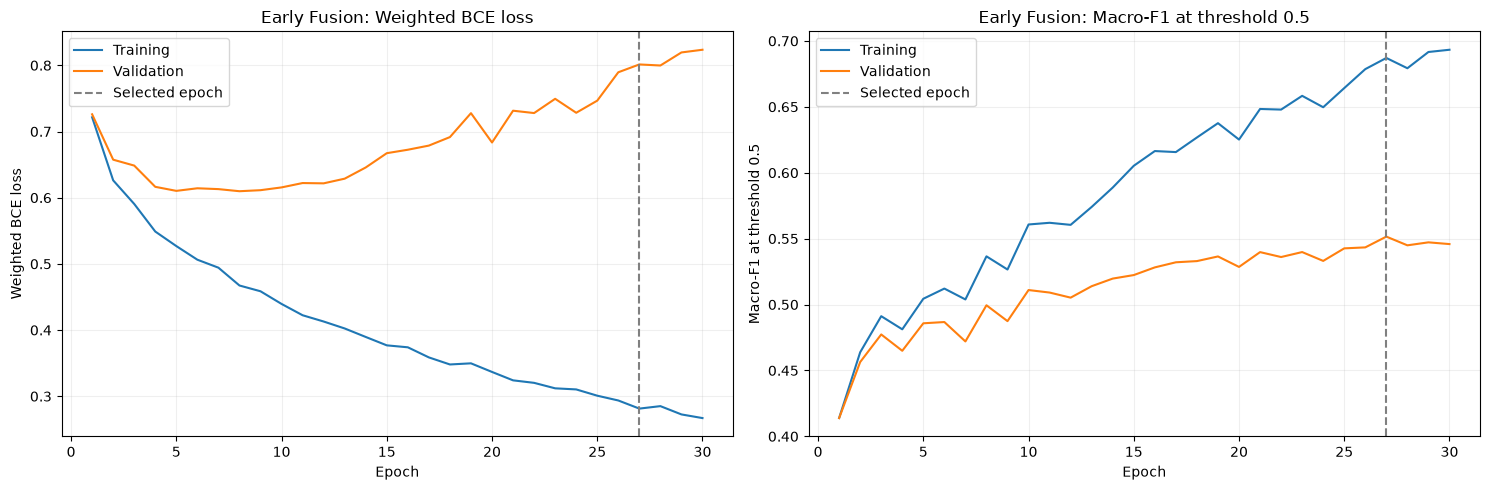

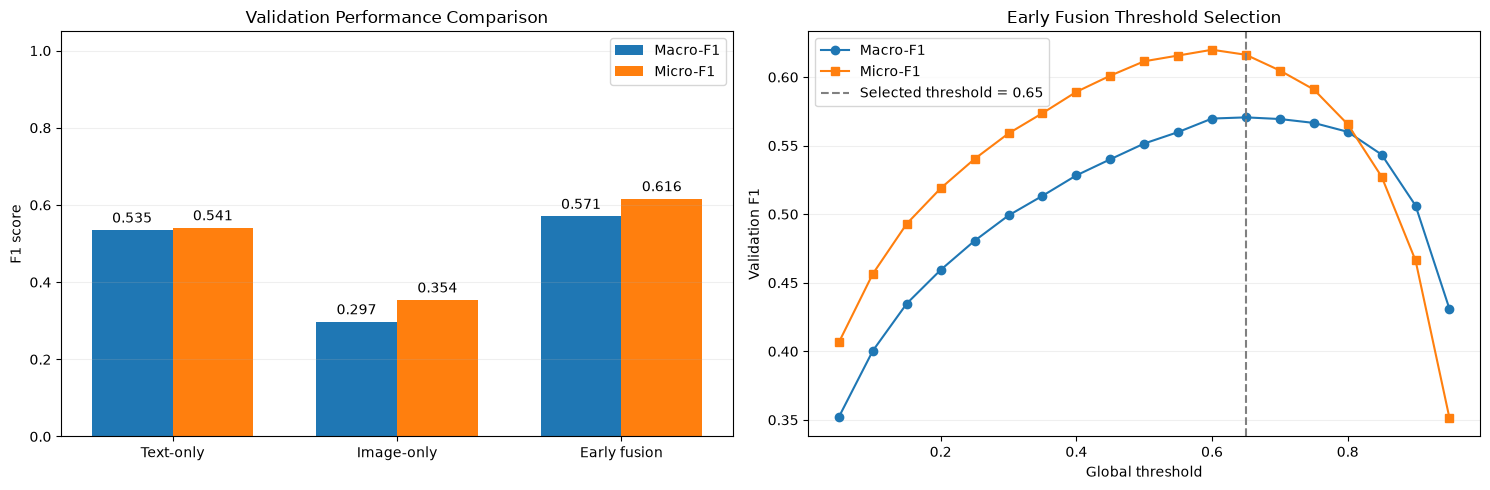


SAVED EARLY FUSION RESULTS
 - baseline_comparison.csv
 - early_fusion_best.pt
 - early_fusion_learning_curves.png
 - early_fusion_train_predictions.npz
 - early_fusion_validation_comparison.png
 - early_fusion_validation_predictions.npz
 - threshold_search.csv
 - training_config.json
 - training_history.csv
 - validation_results.csv
Results directory: C:\Users\Lenovo\OneDrive - University of Adelaide\Desktop\SEMESTER 2 2026\Multi-Modal Data Analysis\ASSIGNMENT 5\mmimdb_features\v2_317223387d28dbac\early_fusion\20261101_142034_798319


In [36]:
from pathlib import Path
from datetime import datetime
from time import perf_counter
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display
# Reuse the training settings, metric functions and baseline results from Part 9.
required_variables = [
    "feature_data", "split_indices", "records", "labels", "genres", "FEATURE_DIR",
    "unimodal_config", "unimodal_results", "unimodal_validation_df",
    "positive_weights", "training_device", "set_baseline_seed",
    "multilabel_scores", "select_global_threshold", "UNIMODAL_DIR"
]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise RuntimeError("Complete Part 9 first. Missing: " + ", ".join(missing_variables))
# Copy the configuration so the stored baseline settings remain unchanged.
early_fusion_config = dict(unimodal_config)
early_fusion_config.update({
    "model": "Early fusion", "text_dim": 768, "image_dim": 768,
    "fused_dim": 1536, "fusion_order": ["text", "image"],
    "normalisation": "Separate LayerNorm for each modality",
    "baseline_directory": str(Path(UNIMODAL_DIR).resolve())
})
if Path(unimodal_config["feature_directory"]).resolve() != Path(FEATURE_DIR).resolve():
    raise ValueError("The baseline and fusion experiments must use the same feature directory.")
if list(unimodal_config["genres"]) != list(genres):
    raise ValueError("Genre order differs from the baseline configuration.")
EARLY_FUSION_DIR = Path(FEATURE_DIR) / "early_fusion" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
EARLY_FUSION_DIR.mkdir(parents=True, exist_ok=False)
# Verify paired text, image and label rows before building the joint datasets.
fusion_datasets = {}
fusion_labels = {}
fusion_input_rows = []
for split_name in ["train", "validation"]:
    arrays = feature_data[split_name]
    indices = np.asarray(split_indices[split_name], dtype=np.int64)
    expected_ids = np.asarray([str(records[i, 0]) for i in indices])
    if not (
        np.array_equal(arrays["row_indices"], indices)
        and np.array_equal(arrays["movie_ids"], expected_ids)
        and np.array_equal(arrays["labels"], labels[indices])
    ):
        raise ValueError(f"Multimodal alignment failed: {split_name}")
    y = np.array(arrays["labels"], dtype=np.float32, copy=True)
    if y.shape != (len(indices), len(genres)) or not np.isin(y, [0, 1]).all():
        raise ValueError(f"Invalid label matrix: {split_name}")
    tensors = []
    for modality in ["text", "image"]:
        matrix = arrays[modality]
        if matrix.shape != (len(indices), early_fusion_config[f"{modality}_dim"]):
            raise ValueError(f"Unexpected feature shape: {split_name} / {modality}")
        if not np.isfinite(matrix).all():
            raise ValueError(f"Non-finite features: {split_name} / {modality}")
        # Writable copies prevent any changes to the saved feature arrays.
        tensors.append(torch.from_numpy(np.array(matrix, dtype=np.float32, copy=True)))
    fusion_labels[split_name] = y
    # All three tensors use the same row order and are shuffled together.
    fusion_datasets[split_name] = TensorDataset(*tensors, torch.from_numpy(y))
    fusion_input_rows.append({
        "Split": split_name, "Movies": len(indices),
        "Text shape": str(tensors[0].shape), "Image shape": str(tensors[1].shape),
        "Fused representation shape": str((len(indices), early_fusion_config["fused_dim"])),
        "Label shape": str(y.shape), "Rows and labels aligned": True
    })
if np.intersect1d(split_indices["train"], split_indices["validation"]).size:
    raise ValueError("Training and validation rows overlap.")
# Verify that the training-derived class weights are identical to those in Part 9.
fusion_positive_counts = fusion_labels["train"].sum(axis=0, dtype=np.float64)
fusion_negative_counts = len(fusion_labels["train"]) - fusion_positive_counts
if np.any(fusion_positive_counts == 0) or np.any(fusion_negative_counts == 0):
    raise ValueError("Every genre must have positive and negative training examples.")
expected_weights = (fusion_negative_counts / fusion_positive_counts).astype(np.float32)
if not np.array_equal(expected_weights, np.asarray(positive_weights)):
    raise ValueError("Class weights differ from the current training labels.")
print("EARLY FUSION INPUTS")
display(pd.DataFrame(fusion_input_rows))
print("\nEARLY FUSION CONFIGURATION")
display(pd.DataFrame({
    "Setting": list(early_fusion_config),
    "Value": [str(value) for value in early_fusion_config.values()]
}))
# Normalise each modality separately, then concatenate the vectors inside the model.
class EarlyFusionMLP(nn.Module):
    def __init__(self, text_dim, image_dim, hidden_dim, output_dim, dropout):
        super().__init__()
        self.text_norm = nn.LayerNorm(text_dim)
        self.image_norm = nn.LayerNorm(image_dim)
        self.classifier = nn.Sequential(
            nn.Linear(text_dim + image_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, output_dim)
        )
    def forward(self, text_features, image_features):
        normalised_text = self.text_norm(text_features)
        normalised_image = self.image_norm(image_features)
        fused_features = torch.cat([normalised_text, normalised_image], dim=1)
        # Return 23 logits; sigmoid is applied when generating prediction scores.
        return self.classifier(fused_features)
# Set the seed before model initialisation and use the baseline batch-order seed.
set_baseline_seed(early_fusion_config["seed"])
fusion_generator = torch.Generator().manual_seed(early_fusion_config["seed"])
fusion_train_loader = DataLoader(
    fusion_datasets["train"], batch_size=early_fusion_config["batch_size"],
    shuffle=True, generator=fusion_generator, num_workers=0
)
fusion_eval_loaders = {
    split_name: DataLoader(
        dataset, batch_size=early_fusion_config["evaluation_batch_size"],
        shuffle=False, num_workers=0
    )
    for split_name, dataset in fusion_datasets.items()
}
early_fusion_model = EarlyFusionMLP(
    text_dim=early_fusion_config["text_dim"],
    image_dim=early_fusion_config["image_dim"],
    hidden_dim=early_fusion_config["hidden_dim"],
    output_dim=len(genres), dropout=early_fusion_config["dropout"]
).to(training_device)
fusion_parameter_count = sum(
    parameter.numel() for parameter in early_fusion_model.parameters() if parameter.requires_grad
)
print("\nEARLY FUSION MODEL")
print(early_fusion_model)
print("Training device:", training_device)
print("Trainable fusion-head parameters:", f"{fusion_parameter_count:,}")
fusion_criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(expected_weights, device=training_device)
)
fusion_optimizer = torch.optim.AdamW(
    early_fusion_model.parameters(), lr=early_fusion_config["learning_rate"],
    weight_decay=early_fusion_config["weight_decay"]
)
# Evaluate complete splits with dropout disabled and saved row order preserved.
@torch.inference_mode()
def evaluate_early_fusion(model, loader, criterion):
    model.eval()
    loss_sum = 0.0
    probability_batches = []
    for text_batch, image_batch, targets in loader:
        text_batch = text_batch.to(training_device)
        image_batch = image_batch.to(training_device)
        targets = targets.to(training_device)
        logits = model(text_batch, image_batch)
        loss_sum += criterion(logits, targets).item() * len(targets)
        probability_batches.append(torch.sigmoid(logits).cpu().numpy())
    probabilities = np.concatenate(probability_batches, axis=0)
    if not np.isfinite(probabilities).all() or not np.isfinite(loss_sum):
        raise FloatingPointError("Non-finite fusion predictions or evaluation loss.")
    return loss_sum / len(loader.dataset), probabilities
# Train only the fusion head; cached encoder features remain fixed.
fusion_history_rows = []
fusion_best_macro = -np.inf
fusion_best_epoch = 0
fusion_best_state = None
fusion_stale_epochs = 0
if training_device.type == "cuda":
    torch.cuda.synchronize()
fusion_training_start = perf_counter()
for epoch in range(1, early_fusion_config["max_epochs"] + 1):
    epoch_start = perf_counter()
    early_fusion_model.train()
    for text_batch, image_batch, targets in fusion_train_loader:
        text_batch = text_batch.to(training_device)
        image_batch = image_batch.to(training_device)
        targets = targets.to(training_device)
        fusion_optimizer.zero_grad(set_to_none=True)
        loss = fusion_criterion(early_fusion_model(text_batch, image_batch), targets)
        if not torch.isfinite(loss).item():
            raise FloatingPointError(f"Non-finite early fusion loss at epoch {epoch}.")
        loss.backward()
        fusion_optimizer.step()
    # Use the same epoch weights and evaluation mode for both loss curves.
    train_loss, train_probabilities = evaluate_early_fusion(
        early_fusion_model, fusion_eval_loaders["train"], fusion_criterion
    )
    val_loss, val_probabilities = evaluate_early_fusion(
        early_fusion_model, fusion_eval_loaders["validation"], fusion_criterion
    )
    train_scores = multilabel_scores(fusion_labels["train"], train_probabilities)
    val_scores = multilabel_scores(fusion_labels["validation"], val_probabilities)
    improved = val_scores["Macro-F1"] > fusion_best_macro
    if improved:
        fusion_best_macro = val_scores["Macro-F1"]
        fusion_best_epoch = epoch
        fusion_best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in early_fusion_model.state_dict().items()
        }
        fusion_stale_epochs = 0
    else:
        fusion_stale_epochs += 1
    fusion_history_rows.append({
        "Model": "Early fusion", "Epoch": epoch,
        "Train loss": train_loss, "Validation loss": val_loss,
        "Train Macro-F1 @0.5": train_scores["Macro-F1"],
        "Validation Macro-F1 @0.5": val_scores["Macro-F1"],
        "Validation Micro-F1 @0.5": val_scores["Micro-F1"],
        "Epoch seconds": perf_counter() - epoch_start
    })
    print(
        f"Epoch {epoch:02d} | Loss: train={train_loss:.4f}, val={val_loss:.4f} | "
        f"Macro-F1@0.5: train={train_scores['Macro-F1']:.4f}, val={val_scores['Macro-F1']:.4f} | "
        f"Val Micro-F1@0.5={val_scores['Micro-F1']:.4f}"
        + (" | Best checkpoint" if improved else ""), flush=True
    )
    if fusion_stale_epochs >= early_fusion_config["patience"]:
        print(f"Early stopping after {epoch} epochs.")
        break
if training_device.type == "cuda":
    torch.cuda.synchronize()
fusion_training_seconds = perf_counter() - fusion_training_start
# Restore the best checkpoint before selecting the global validation threshold.
early_fusion_model.load_state_dict(fusion_best_state)
fusion_train_loss, fusion_train_probabilities = evaluate_early_fusion(
    early_fusion_model, fusion_eval_loaders["train"], fusion_criterion
)
fusion_val_loss, fusion_val_probabilities = evaluate_early_fusion(
    early_fusion_model, fusion_eval_loaders["validation"], fusion_criterion
)
fusion_threshold, fusion_threshold_search_df = select_global_threshold(
    fusion_labels["validation"], fusion_val_probabilities
)
fusion_threshold_search_df.insert(0, "Model", "Early fusion")
fusion_default_scores = multilabel_scores(fusion_labels["validation"], fusion_val_probabilities)
fusion_train_scores = multilabel_scores(
    fusion_labels["train"], fusion_train_probabilities, fusion_threshold
)
fusion_val_scores = multilabel_scores(
    fusion_labels["validation"], fusion_val_probabilities, fusion_threshold
)
fusion_summary = {
    "Model": "Early fusion", "Best epoch": fusion_best_epoch,
    "Epochs run": len(fusion_history_rows), "Threshold": fusion_threshold,
    "Val Macro-F1 @0.5": fusion_default_scores["Macro-F1"],
    "Val Micro-F1 @0.5": fusion_default_scores["Micro-F1"],
    "Train Macro-F1": fusion_train_scores["Macro-F1"],
    "Val Macro-F1": fusion_val_scores["Macro-F1"],
    "Val Micro-F1": fusion_val_scores["Micro-F1"],
    "Train-val Macro-F1 gap": fusion_train_scores["Macro-F1"] - fusion_val_scores["Macro-F1"],
    "Validation weighted BCE": fusion_val_loss,
    "Training loop (s)": fusion_training_seconds
}
early_fusion_history_df = pd.DataFrame(fusion_history_rows)
early_fusion_validation_df = pd.DataFrame([fusion_summary])
# Keep baseline tables unchanged and create a separate comparison table.
fusion_comparison_df = pd.concat(
    [unimodal_validation_df, early_fusion_validation_df], ignore_index=True
)
parameter_counts = {
    result["summary"]["Model"]: sum(
        parameter.numel() for parameter in result["model"].parameters() if parameter.requires_grad
    )
    for result in unimodal_results.values()
}
parameter_counts["Early fusion"] = fusion_parameter_count
fusion_comparison_df["Trainable parameters"] = fusion_comparison_df["Model"].map(parameter_counts)
best_baseline_macro = float(unimodal_validation_df["Val Macro-F1"].max())
fusion_comparison_df["Macro-F1 difference vs best baseline"] = (
    fusion_comparison_df["Val Macro-F1"] - best_baseline_macro
)
print("\nEARLY FUSION THRESHOLD SEARCH")
display(fusion_threshold_search_df.round(4))
print("\nVALIDATION COMPARISON")
display(fusion_comparison_df.round(4))
print(f"Selected epoch: {fusion_best_epoch} | Selected threshold: {fusion_threshold:.2f}")
print(f"Early fusion Macro-F1 difference vs best baseline: {fusion_val_scores['Macro-F1'] - best_baseline_macro:+.4f}")
print("Unqualified F1 columns use each model's validation-selected threshold.")
print("Training settings are shared; early fusion has more parameters because its input is larger.")
# Save the selected state and settings needed to reconstruct the fusion model.
early_fusion_config["trainable_parameters"] = fusion_parameter_count
with (EARLY_FUSION_DIR / "training_config.json").open("w", encoding="utf-8") as file:
    json.dump(early_fusion_config, file, indent=2)
fusion_checkpoint_path = EARLY_FUSION_DIR / "early_fusion_best.pt"
torch.save({
    "state_dict": fusion_best_state,
    "text_dim": early_fusion_config["text_dim"],
    "image_dim": early_fusion_config["image_dim"],
    "hidden_dim": early_fusion_config["hidden_dim"],
    "output_dim": len(genres), "dropout": early_fusion_config["dropout"],
    "best_epoch": fusion_best_epoch, "threshold": fusion_threshold,
    "positive_weights": expected_weights.tolist(), "genres": list(genres),
    "fusion_order": ["text", "image"],
    "feature_directory": str(Path(FEATURE_DIR).resolve())
}, fusion_checkpoint_path)
for split_name, probabilities in [
    ("train", fusion_train_probabilities), ("validation", fusion_val_probabilities)
]:
    np.savez_compressed(
        EARLY_FUSION_DIR / f"early_fusion_{split_name}_predictions.npz",
        probabilities=probabilities, labels=fusion_labels[split_name],
        row_indices=feature_data[split_name]["row_indices"],
        movie_ids=np.asarray(feature_data[split_name]["movie_ids"], dtype=str)
    )
early_fusion_model.to("cpu").eval()
early_fusion_result = {
    "model": early_fusion_model, "threshold": fusion_threshold,
    "history": early_fusion_history_df, "summary": fusion_summary,
    "threshold_search": fusion_threshold_search_df,
    "train_probabilities": fusion_train_probabilities,
    "val_probabilities": fusion_val_probabilities,
    "checkpoint_path": fusion_checkpoint_path
}
# Show the learning curves using a fixed threshold of 0.5 for every epoch.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, train_column, val_column, ylabel in [
    (axes[0], "Train loss", "Validation loss", "Weighted BCE loss"),
    (axes[1], "Train Macro-F1 @0.5", "Validation Macro-F1 @0.5", "Macro-F1 at threshold 0.5")
]:
    ax.plot(early_fusion_history_df["Epoch"], early_fusion_history_df[train_column], label="Training")
    ax.plot(early_fusion_history_df["Epoch"], early_fusion_history_df[val_column], label="Validation")
    ax.axvline(fusion_best_epoch, color="grey", linestyle="--", label="Selected epoch")
    ax.set(title=f"Early Fusion: {ylabel}", xlabel="Epoch", ylabel=ylabel)
    ax.grid(alpha=0.2)
    ax.legend()
fig.tight_layout()
fig.savefig(EARLY_FUSION_DIR / "early_fusion_learning_curves.png", dpi=200, bbox_inches="tight")
plt.show()
# Compare all three models at their individually selected global thresholds.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
positions = np.arange(len(fusion_comparison_df))
for offset, column, label in [
    (-0.18, "Val Macro-F1", "Macro-F1"), (0.18, "Val Micro-F1", "Micro-F1")
]:
    bars = axes[0].bar(positions + offset, fusion_comparison_df[column], width=0.36, label=label)
    axes[0].bar_label(bars, fmt="%.3f", padding=3)
axes[0].set_xticks(positions, fusion_comparison_df["Model"])
axes[0].set(title="Validation Performance Comparison", ylabel="F1 score", ylim=(0, 1.05))
axes[0].legend()
axes[1].plot(
    fusion_threshold_search_df["Threshold"], fusion_threshold_search_df["Macro-F1"],
    marker="o", label="Macro-F1"
)
axes[1].plot(
    fusion_threshold_search_df["Threshold"], fusion_threshold_search_df["Micro-F1"],
    marker="s", label="Micro-F1"
)
axes[1].axvline(fusion_threshold, color="grey", linestyle="--", label=f"Selected threshold = {fusion_threshold:.2f}")
axes[1].set(title="Early Fusion Threshold Selection", xlabel="Global threshold", ylabel="Validation F1")
axes[1].legend()
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(EARLY_FUSION_DIR / "early_fusion_validation_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
# Archive the tables and retain the result objects for final evaluation.
early_fusion_history_df.to_csv(EARLY_FUSION_DIR / "training_history.csv", index=False)
fusion_threshold_search_df.to_csv(EARLY_FUSION_DIR / "threshold_search.csv", index=False)
early_fusion_validation_df.to_csv(EARLY_FUSION_DIR / "validation_results.csv", index=False)
fusion_comparison_df.to_csv(EARLY_FUSION_DIR / "baseline_comparison.csv", index=False)
print("\nSAVED EARLY FUSION RESULTS")
for path in sorted(EARLY_FUSION_DIR.iterdir()):
    print(" -", path.name)
print("Results directory:", EARLY_FUSION_DIR)

Early fusion combined the 768-dimensional text and image embeddings into a 1,536-dimensional representation for 15,581 training movies and 2,595 validation movies, with row identities and labels correctly aligned. The fusion classifier contained 402,455 trainable parameters and completed all 30 epochs. Epoch 27 was selected using validation Macro-F1 at a threshold of 0.5, achieving a Macro-F1 of 0.5515 and Micro-F1 of 0.6115. Subsequent threshold selection identified 0.65 as the best threshold for validation Macro-F1, yielding a Macro-F1 of 0.5706 and Micro-F1 of 0.6163. This exceeded the text-only baseline’s Macro-F1 of 0.5350 by 0.0356 and also surpassed the image-only result of 0.2974. At the selected checkpoint and threshold, training Macro-F1 was 0.7360, producing a train–validation gap of 0.1654, compared with 0.0036 for text and 0.0895 for images. This larger gap, together with increasing validation weighted BCE during later epochs, suggests overfitting despite the improved validation F1 scores. Validation weighted BCE at the selected checkpoint was 0.8013. The training loop took 33.6609 seconds on CPU, including epoch training and evaluation but excluding feature extraction and final saving. The fusion classifier used more parameters than either unimodal baseline because of its larger input representation. The selected checkpoint, predictions, training history, threshold-search results and comparison figures were saved.

### 11. Late fusion:

Late fusion combines aligned sigmoid scores from the text-only and image-only classifiers without retraining them. Equal weighting, a shared mixing weight and genre-specific weights are compared. Mixing weights and one global threshold per variant are selected using validation Macro-F1. Training–validation gaps, per-genre F1 and comparison plots are reported. Selected settings and prediction probabilities are saved for subsequent test evaluation.

LATE FUSION INPUTS


,Split,Modality,Prediction shape,Rows and labels aligned,Minimum score,Maximum score
0,train,Text,"(15581, 23)",True,0.0,1.0000
1,train,Image,"(15581, 23)",True,0.0,0.9997
2,validation,Text,"(2595, 23)",True,0.0,0.9999
3,validation,Image,"(2595, 23)",True,0.0,0.9992


Text-weight grid: [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
Global-threshold grid: [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95]
Fusion rule: alpha * text score + (1 - alpha) * image score.
Scores remain independent across genres; rows are not normalised to sum to one.
Evaluated text weight 0.00 across 19 thresholds.
Evaluated text weight 0.10 across 19 thresholds.
Evaluated text weight 0.20 across 19 thresholds.
Evaluated text weight 0.30 across 19 thresholds.
Evaluated text weight 0.40 across 19 thresholds.
Evaluated text weight 0.50 across 19 thresholds.
Evaluated text weight 0.60 across 19 thresholds.
Evaluated text weight 0.70 across 19 thresholds.
Evaluated text weight 0.80 across 19 thresholds.
Evaluated text weight 0.90 across 19 thresholds.
Evaluated text weight 1.00 across 19 thresholds.

GLOBAL WEIGHT SEARCH: BEST THRESHOLD PER WEIGHT


,Text weight,Image weight,Threshold,Macro-F1,Micro-F1
0,0.0,1.0,0.60,0.2974,0.3538
1,0.1,0.9,0.60,0.3375,0.4024
2,0.2,0.8,0.60,0.3862,0.4556
3,0.3,0.7,0.60,0.4477,0.5113
4,0.4,0.6,0.60,0.5058,0.5582
5,0.5,0.5,0.60,0.5377,0.5834
6,0.6,0.4,0.65,0.5514,0.5766
7,0.7,0.3,0.65,0.5566,0.5844
8,0.8,0.2,0.70,0.5518,0.5646
9,0.9,0.1,0.70,0.5413,0.5617



PER-GENRE WEIGHT SEARCH: BEST WEIGHTS AT EACH GLOBAL THRESHOLD


,Threshold,Macro-F1,Micro-F1,Mean text weight
0,0.05,0.2267,0.2643,0.9130
1,0.10,0.2653,0.3109,0.9565
2,0.15,0.2996,0.3517,0.9609
3,0.20,0.3310,0.3886,0.9261
4,0.25,0.3584,0.4209,0.9304
5,0.30,0.3863,0.4539,0.8739
6,0.35,0.4137,0.4844,0.8435
7,0.40,0.4452,0.5191,0.8043
8,0.45,0.4757,0.5482,0.7174
9,0.50,0.5060,0.5743,0.6217



SELECTED PER-GENRE WEIGHTS AND VALIDATION F1


,Genre,Validation positives,Text weight,Image weight,Text-only F1,Image-only F1,Late equal F1,Late global F1,Late per_genre F1
0,Drama,1432,1.0,0.0,0.4914,0.5434,0.6753,0.6164,0.5829
1,Comedy,824,1.0,0.0,0.4950,0.5591,0.6358,0.6057,0.5664
2,Romance,535,1.0,0.0,0.5113,0.4190,0.5478,0.5463,0.5427
3,Thriller,517,1.0,0.0,0.5195,0.4490,0.5991,0.5876,0.5533
4,Crime,372,1.0,0.0,0.6223,0.3230,0.6098,0.6104,0.6265
5,Action,342,0.6,0.4,0.6212,0.4107,0.6215,0.6362,0.6357
6,Adventure,267,0.8,0.2,0.5965,0.3671,0.5728,0.6040,0.6107
7,Horror,267,0.9,0.1,0.6985,0.4136,0.6801,0.7110,0.7096
8,Documentary,205,0.7,0.3,0.7663,0.2762,0.7669,0.7683,0.7982
9,Mystery,196,0.9,0.1,0.4454,0.2029,0.3678,0.4217,0.4408



VALIDATION COMPARISON


,Model,Threshold,Val Macro-F1 @0.5,Val Micro-F1 @0.5,Train Macro-F1,Val Macro-F1,Val Micro-F1,Train-val Macro-F1 gap,Macro-F1 difference vs best baseline,Macro-F1 difference vs early fusion
0,Text-only,0.75,0.4708,0.5354,0.5386,0.5350,0.5409,0.0036,0.0000,-0.0356
1,Image-only,0.60,0.2885,0.3484,0.3869,0.2974,0.3538,0.0895,-0.2376,-0.2733
2,Early fusion,0.65,0.5515,0.6115,0.7360,0.5706,0.6163,0.1654,0.0356,0.0000
3,Late fusion (equal),0.60,0.4933,0.5664,0.6031,0.5377,0.5834,0.0654,0.0027,-0.0329
4,Late fusion (global),0.65,0.4943,0.5627,0.5914,0.5566,0.5844,0.0348,0.0216,-0.0140
5,Late fusion (per-genre),0.70,0.4904,0.5548,0.6072,0.5718,0.5839,0.0355,0.0368,0.0011


Main late fusion variant: per-genre weights.
Selected global threshold: 0.7
Weight and threshold search time: 3.9327 seconds.
Search time excludes feature extraction, base-classifier training, loading and final saving.
More mixing weights provide more tuning flexibility; validation gains require confirmation on test.


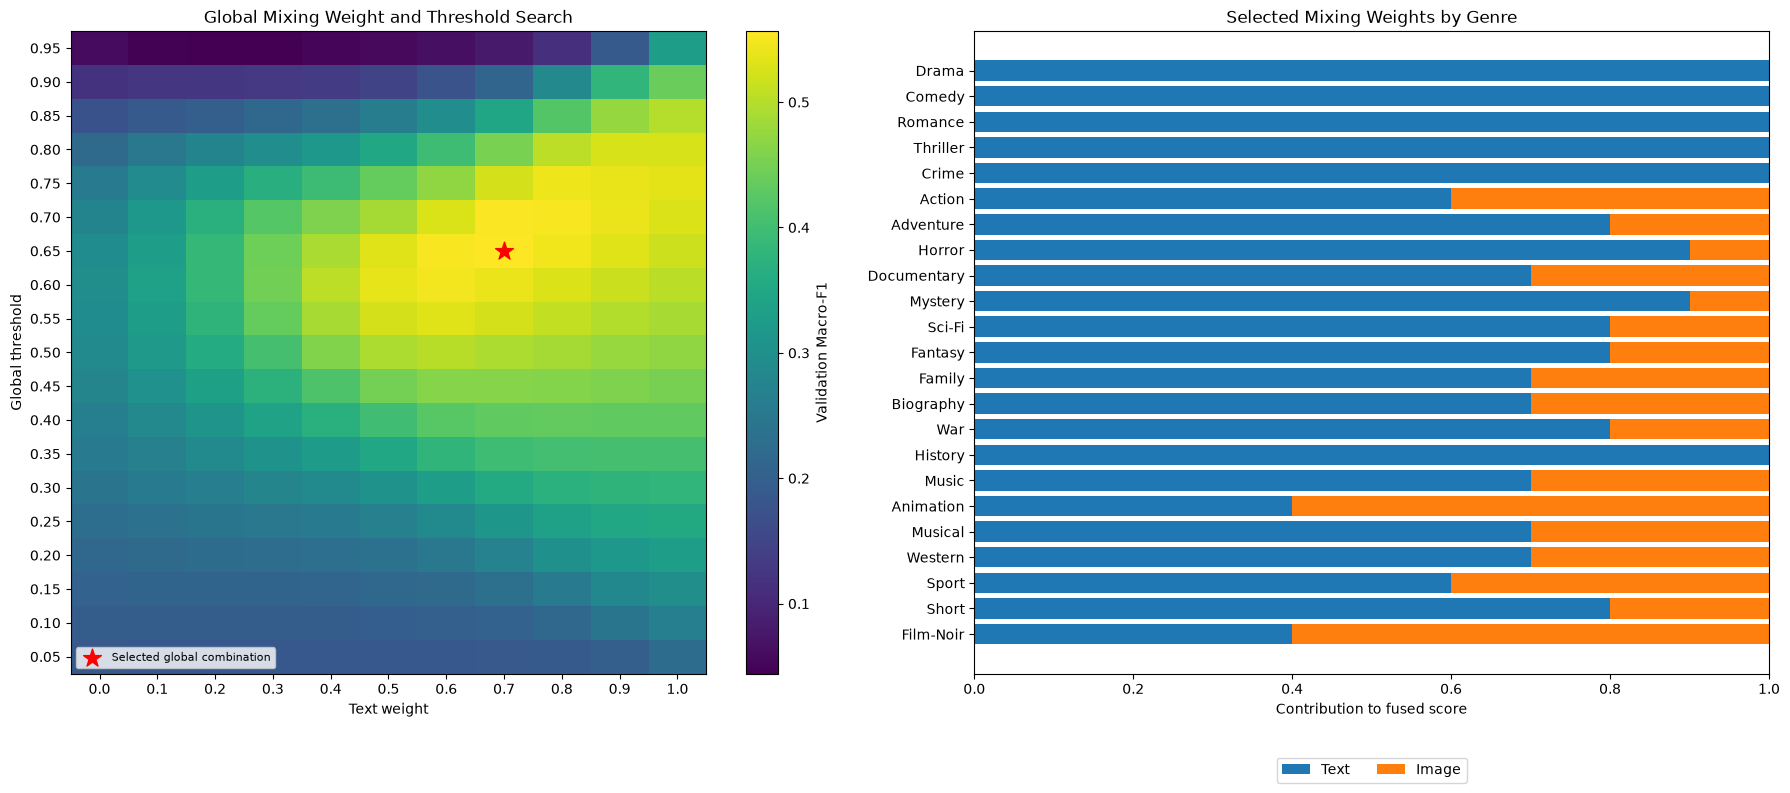

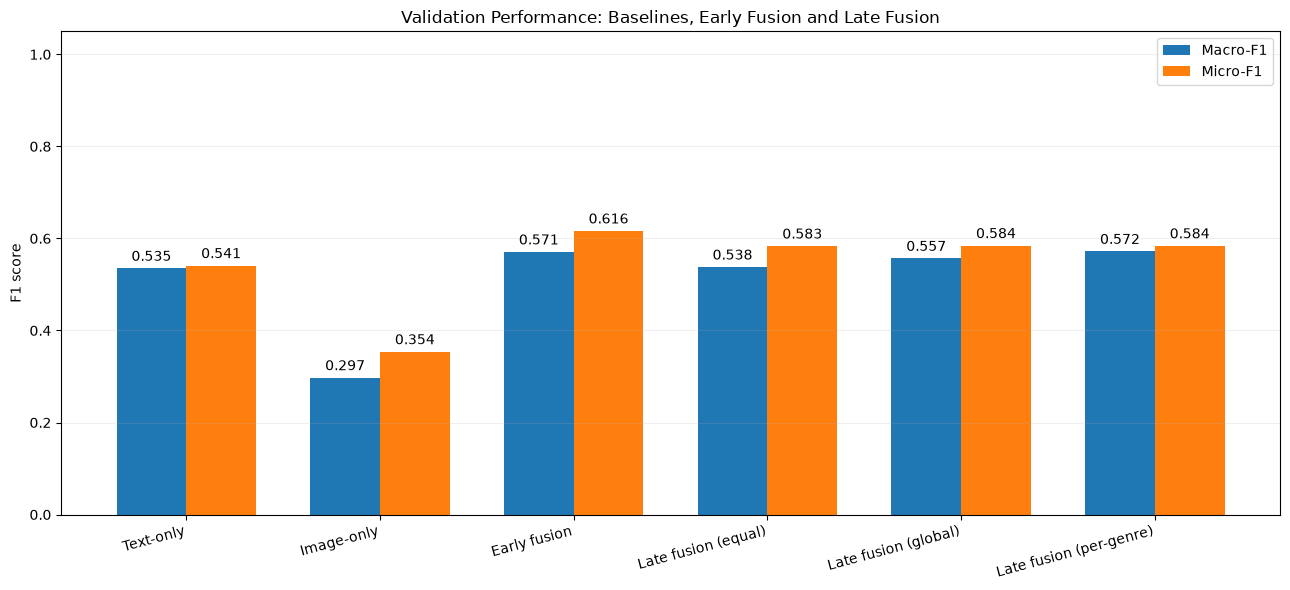


SAVED LATE FUSION RESULTS
 - all_model_validation_comparison.csv
 - best_threshold_per_global_weight.csv
 - equal_train_predictions.npz
 - equal_validation_predictions.npz
 - global_train_predictions.npz
 - global_validation_predictions.npz
 - global_weight_threshold_search.csv
 - late_fusion_config.json
 - late_fusion_validation_comparison.png
 - late_fusion_weight_analysis.png
 - per_genre_threshold_search.csv
 - per_genre_train_predictions.npz
 - per_genre_validation_predictions.npz
 - prediction_integrity.csv
 - selected_genre_weights.csv
 - validation_results.csv
Results directory: C:\Users\Lenovo\OneDrive - University of Adelaide\Desktop\SEMESTER 2 2026\Multi-Modal Data Analysis\ASSIGNMENT 5\mmimdb_features\v2_317223387d28dbac\late_fusion\20261101_142620_475936


In [37]:
from pathlib import Path
from datetime import datetime
from time import perf_counter
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
# Reuse predictions from Part 9 and the early fusion comparison from Part 10.
required_variables = [
    "feature_data", "split_indices", "records", "labels", "genres", "FEATURE_DIR",
    "unimodal_results", "unimodal_validation_df", "UNIMODAL_DIR",
    "early_fusion_validation_df", "EARLY_FUSION_DIR", "multilabel_scores"
]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise RuntimeError("Complete Parts 9 and 10 first. Missing: " + ", ".join(missing_variables))
# Read the saved configuration to preserve the baseline threshold-search grid.
with (Path(UNIMODAL_DIR) / "training_config.json").open(encoding="utf-8") as file:
    source_baseline_config = json.load(file)
with (Path(EARLY_FUSION_DIR) / "training_config.json").open(encoding="utf-8") as file:
    source_early_config = json.load(file)
for source_config in [source_baseline_config, source_early_config]:
    if Path(source_config["feature_directory"]).resolve() != Path(FEATURE_DIR).resolve():
        raise ValueError("All models must use the same cached features.")
    if source_config["genres"] != list(genres):
        raise ValueError("Genre order differs between experiments.")
if Path(source_early_config["baseline_directory"]).resolve() != Path(UNIMODAL_DIR).resolve():
    raise ValueError("Run Part 10 using the current Part 9 baseline results.")
# Alpha is the text contribution; the image contribution is 1 - alpha.
TEXT_WEIGHT_GRID = np.round(np.linspace(0.0, 1.0, 11), 2)
LATE_THRESHOLD_GRID = np.asarray(source_baseline_config["threshold_grid"], dtype=float)
LATE_FUSION_DIR = Path(FEATURE_DIR) / "late_fusion" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
LATE_FUSION_DIR.mkdir(parents=True, exist_ok=False)
late_inputs = {}
late_labels = {}
late_input_rows = []
# Read identifiers with the probabilities, rather than assuming that row counts imply alignment.
for split_name in ["train", "validation"]:
    indices = np.asarray(split_indices[split_name], dtype=np.int64)
    expected_ids = np.asarray([str(records[i, 0]) for i in indices])
    arrays = feature_data[split_name]
    if not (
        np.array_equal(arrays["row_indices"], indices)
        and np.array_equal(arrays["movie_ids"], expected_ids)
        and np.array_equal(arrays["labels"], labels[indices])
    ):
        raise ValueError(f"Feature metadata is misaligned: {split_name}")
    late_labels[split_name] = np.array(arrays["labels"], dtype=np.float32, copy=True)
    if not np.isin(late_labels[split_name], [0, 1]).all():
        raise ValueError(f"Non-binary labels: {split_name}")
    late_inputs[split_name] = {}
    for modality in ["text", "image"]:
        prediction_path = Path(UNIMODAL_DIR) / f"{modality}_{split_name}_predictions.npz"
        with np.load(prediction_path, allow_pickle=False) as saved:
            if not (
                np.array_equal(saved["row_indices"], indices)
                and np.array_equal(saved["movie_ids"], expected_ids)
                and np.array_equal(saved["labels"], late_labels[split_name])
            ):
                raise ValueError(f"Saved prediction alignment failed: {split_name} / {modality}")
            probabilities = np.array(saved["probabilities"], dtype=np.float32, copy=True)
        if probabilities.shape != (len(indices), len(genres)):
            raise ValueError(f"Incorrect probability shape: {split_name} / {modality}")
        if not np.isfinite(probabilities).all() or np.any((probabilities < 0) | (probabilities > 1)):
            raise ValueError(f"Invalid prediction scores: {split_name} / {modality}")
        result_key = "train_probabilities" if split_name == "train" else "val_probabilities"
        if not np.array_equal(probabilities, unimodal_results[modality][result_key]):
            raise ValueError("Saved predictions differ from the current baseline results.")
        late_inputs[split_name][modality] = probabilities
        late_input_rows.append({
            "Split": split_name, "Modality": modality.title(),
            "Prediction shape": str(probabilities.shape),
            "Rows and labels aligned": True,
            "Minimum score": float(probabilities.min()),
            "Maximum score": float(probabilities.max())
        })
if np.intersect1d(split_indices["train"], split_indices["validation"]).size:
    raise ValueError("Training and validation rows overlap.")
late_input_df = pd.DataFrame(late_input_rows)
print("LATE FUSION INPUTS")
display(late_input_df.round(4))
print("Text-weight grid:", TEXT_WEIGHT_GRID.tolist())
print("Global-threshold grid:", LATE_THRESHOLD_GRID.tolist())
print("Fusion rule: alpha * text score + (1 - alpha) * image score.")
print("Scores remain independent across genres; rows are not normalised to sum to one.")
# Broadcast a scalar or one text weight per genre over all movies.
def mix_late_probabilities(text_probabilities, image_probabilities, text_weights):
    weights = np.asarray(text_weights, dtype=np.float32)
    return weights * text_probabilities + (np.float32(1.0) - weights) * image_probabilities
# Calculate one F1 score per genre for selecting genre-specific mixing weights.
def per_genre_f1(targets, probabilities, threshold):
    actual = targets.astype(bool)
    predicted = probabilities >= threshold
    true_positives = np.count_nonzero(actual & predicted, axis=0)
    denominator = np.count_nonzero(actual, axis=0) + np.count_nonzero(predicted, axis=0)
    return np.divide(
        2.0 * true_positives, denominator,
        out=np.zeros(len(genres), dtype=np.float64), where=denominator > 0
    )
# Use the same threshold tie rule as Parts 9 and 10.
def choose_late_threshold(table):
    ranked = table.assign(distance=(table["Threshold"] - 0.5).abs().round(8))
    return ranked.sort_values(
        ["Macro-F1", "distance", "Threshold"], ascending=[False, True, True]
    ).iloc[0]
# Search only validation predictions; no classifier is retrained.
search_start = perf_counter()
global_search_rows = []
genre_score_grid = np.empty(
    (len(LATE_THRESHOLD_GRID), len(TEXT_WEIGHT_GRID), len(genres)), dtype=np.float64
)
for weight_index, alpha in enumerate(TEXT_WEIGHT_GRID):
    mixed = mix_late_probabilities(
        late_inputs["validation"]["text"], late_inputs["validation"]["image"], alpha
    )
    for threshold_index, threshold in enumerate(LATE_THRESHOLD_GRID):
        scores = multilabel_scores(late_labels["validation"], mixed, float(threshold))
        genre_score_grid[threshold_index, weight_index] = per_genre_f1(
            late_labels["validation"], mixed, float(threshold)
        )
        global_search_rows.append({
            "Text weight": float(alpha), "Image weight": float(1.0 - alpha),
            "Threshold": float(threshold), **scores
        })
    print(f"Evaluated text weight {alpha:.2f} across {len(LATE_THRESHOLD_GRID)} thresholds.", flush=True)
late_global_search_df = pd.DataFrame(global_search_rows)
# Equal fusion fixes the mixing weight at 0.5 and tunes only the threshold.
equal_candidates = late_global_search_df.loc[late_global_search_df["Text weight"] == 0.5]
equal_choice = choose_late_threshold(equal_candidates)
# Global fusion jointly selects one shared text weight and one global threshold.
global_ranked = late_global_search_df.assign(
    weight_distance=(late_global_search_df["Text weight"] - 0.5).abs().round(8),
    threshold_distance=(late_global_search_df["Threshold"] - 0.5).abs().round(8)
)
global_choice = global_ranked.sort_values(
    ["Macro-F1", "weight_distance", "threshold_distance", "Text weight", "Threshold"],
    ascending=[False, True, True, True, True]
).iloc[0]
# Summarise the best threshold for every shared mixing weight.
late_weight_summary_df = pd.DataFrame([
    choose_late_threshold(group).drop(labels="distance")
    for _, group in late_global_search_df.groupby("Text weight", sort=True)
]).reset_index(drop=True)
# For a fixed threshold, Macro-F1 is maximised by choosing each genre's best weight.
# Equal F1 values favour weights closest to 0.5, then the smaller text weight.
weight_priority = np.asarray(sorted(
    range(len(TEXT_WEIGHT_GRID)),
    key=lambda i: (round(abs(float(TEXT_WEIGHT_GRID[i]) - 0.5), 8), float(TEXT_WEIGHT_GRID[i]))
))
genre_candidate_weights = []
genre_candidate_rows = []
for threshold_index, threshold in enumerate(LATE_THRESHOLD_GRID):
    ordered_scores = genre_score_grid[threshold_index, weight_priority, :]
    best_indices = weight_priority[np.argmax(ordered_scores, axis=0)]
    selected_weights = TEXT_WEIGHT_GRID[best_indices].astype(np.float32)
    genre_candidate_weights.append(selected_weights)
    mixed = mix_late_probabilities(
        late_inputs["validation"]["text"], late_inputs["validation"]["image"], selected_weights
    )
    scores = multilabel_scores(late_labels["validation"], mixed, float(threshold))
    genre_candidate_rows.append({
        "Threshold": float(threshold), **scores,
        "Mean text weight": float(selected_weights.mean()),
        "Weight index": threshold_index
    })
late_genre_threshold_df = pd.DataFrame(genre_candidate_rows)
genre_choice = choose_late_threshold(late_genre_threshold_df)
selected_genre_weights = genre_candidate_weights[int(genre_choice["Weight index"])]
late_search_seconds = perf_counter() - search_start
# Per-genre weighting is the main late fusion variant specified in the proposal.
late_variant_settings = {
    "equal": {
        "name": "Late fusion (equal)",
        "weights": np.full(len(genres), 0.5, dtype=np.float32),
        "threshold": float(equal_choice["Threshold"])
    },
    "global": {
        "name": "Late fusion (global)",
        "weights": np.full(len(genres), float(global_choice["Text weight"]), dtype=np.float32),
        "threshold": float(global_choice["Threshold"])
    },
    "per_genre": {
        "name": "Late fusion (per-genre)",
        "weights": selected_genre_weights.copy(),
        "threshold": float(genre_choice["Threshold"])
    }
}
late_fusion_results = {}
for variant, settings in late_variant_settings.items():
    # Apply the validation-selected settings unchanged when calculating training metrics.
    train_probabilities = mix_late_probabilities(
        late_inputs["train"]["text"], late_inputs["train"]["image"], settings["weights"]
    )
    val_probabilities = mix_late_probabilities(
        late_inputs["validation"]["text"], late_inputs["validation"]["image"], settings["weights"]
    )
    train_scores = multilabel_scores(late_labels["train"], train_probabilities, settings["threshold"])
    val_scores = multilabel_scores(late_labels["validation"], val_probabilities, settings["threshold"])
    default_scores = multilabel_scores(late_labels["validation"], val_probabilities, 0.5)
    summary = {
        "Model": settings["name"], "Threshold": settings["threshold"],
        "Val Macro-F1 @0.5": default_scores["Macro-F1"],
        "Val Micro-F1 @0.5": default_scores["Micro-F1"],
        "Train Macro-F1": train_scores["Macro-F1"],
        "Val Macro-F1": val_scores["Macro-F1"],
        "Val Micro-F1": val_scores["Micro-F1"],
        "Train-val Macro-F1 gap": train_scores["Macro-F1"] - val_scores["Macro-F1"]
    }
    late_fusion_results[variant] = {
        "weights": settings["weights"].copy(), "threshold": settings["threshold"],
        "summary": summary, "train_probabilities": train_probabilities,
        "val_probabilities": val_probabilities
    }
late_fusion_result = late_fusion_results["per_genre"]
late_fusion_validation_df = pd.DataFrame([result["summary"] for result in late_fusion_results.values()])
# Show weights and per-genre F1; each method uses its own selected global threshold.
late_genre_weights_df = pd.DataFrame({
    "Genre": genres,
    "Validation positives": late_labels["validation"].sum(axis=0).astype(int),
    "Text weight": selected_genre_weights,
    "Image weight": 1.0 - selected_genre_weights
})
for modality in ["text", "image"]:
    late_genre_weights_df[f"{modality.title()}-only F1"] = per_genre_f1(
        late_labels["validation"], late_inputs["validation"][modality],
        unimodal_results[modality]["threshold"]
    )
for variant, result in late_fusion_results.items():
    late_genre_weights_df[f"Late {variant} F1"] = per_genre_f1(
        late_labels["validation"], result["val_probabilities"], result["threshold"]
    )
# Compare only quantities shared by independently trained and probability-fusion models.
comparison_columns = list(late_fusion_validation_df.columns)
late_fusion_comparison_df = pd.concat([
    unimodal_validation_df[comparison_columns],
    early_fusion_validation_df[comparison_columns],
    late_fusion_validation_df
], ignore_index=True)
best_unimodal_macro = float(unimodal_validation_df["Val Macro-F1"].max())
early_macro = float(early_fusion_validation_df.iloc[0]["Val Macro-F1"])
late_fusion_comparison_df["Macro-F1 difference vs best baseline"] = (
    late_fusion_comparison_df["Val Macro-F1"] - best_unimodal_macro
)
late_fusion_comparison_df["Macro-F1 difference vs early fusion"] = (
    late_fusion_comparison_df["Val Macro-F1"] - early_macro
)
print("\nGLOBAL WEIGHT SEARCH: BEST THRESHOLD PER WEIGHT")
display(late_weight_summary_df.round(4))
print("\nPER-GENRE WEIGHT SEARCH: BEST WEIGHTS AT EACH GLOBAL THRESHOLD")
display(late_genre_threshold_df.drop(columns="Weight index").round(4))
print("\nSELECTED PER-GENRE WEIGHTS AND VALIDATION F1")
display(late_genre_weights_df.round(4))
print("\nVALIDATION COMPARISON")
display(late_fusion_comparison_df.round(4))
print("Main late fusion variant: per-genre weights.")
print("Selected global threshold:", late_fusion_result["threshold"])
print(f"Weight and threshold search time: {late_search_seconds:.4f} seconds.")
print("Search time excludes feature extraction, base-classifier training, loading and final saving.")
print("More mixing weights provide more tuning flexibility; validation gains require confirmation on test.")
# Save the source checkpoints and all selected settings for fixed test-time inference.
late_fusion_config = {
    "feature_directory": str(Path(FEATURE_DIR).resolve()),
    "baseline_directory": str(Path(UNIMODAL_DIR).resolve()),
    "early_fusion_directory": str(Path(EARLY_FUSION_DIR).resolve()),
    "source_checkpoints": {
        modality: str(Path(unimodal_results[modality]["checkpoint_path"]).resolve())
        for modality in ["text", "image"]
    },
    "genres": list(genres), "main_variant": "per_genre",
    "formula": "alpha_g * text_score + (1 - alpha_g) * image_score",
    "text_weight_grid": TEXT_WEIGHT_GRID.tolist(),
    "threshold_grid": LATE_THRESHOLD_GRID.tolist(),
    "threshold_scope": "One global threshold per fusion variant",
    "selection_metric": "Validation Macro-F1",
    "search_seconds": late_search_seconds,
    "score_dtype": "float32", "additional_probability_calibration": False,
    "threshold_tie_rule": "Closest to 0.5, then smaller threshold",
    "weight_tie_rule": "Closest to 0.5, then smaller text weight",
    "global_tie_order": "Weight distance, threshold distance, text weight, threshold",
    "variants": {
        variant: {
            "name": settings["name"],
            "text_weights": settings["weights"].tolist(),
            "threshold": settings["threshold"]
        }
        for variant, settings in late_variant_settings.items()
    }
}
late_config_path = LATE_FUSION_DIR / "late_fusion_config.json"
with late_config_path.open("w", encoding="utf-8") as file:
    json.dump(late_fusion_config, file, indent=2)
for variant, result in late_fusion_results.items():
    result["config_path"] = late_config_path
    for split_name, key in [("train", "train_probabilities"), ("validation", "val_probabilities")]:
        np.savez_compressed(
            LATE_FUSION_DIR / f"{variant}_{split_name}_predictions.npz",
            probabilities=result[key], labels=late_labels[split_name],
            row_indices=feature_data[split_name]["row_indices"],
            movie_ids=np.asarray(feature_data[split_name]["movie_ids"], dtype=str)
        )
# Visualise the complete shared-weight search and the selected per-genre weights.
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
heatmap = late_global_search_df.pivot(
    index="Threshold", columns="Text weight", values="Macro-F1"
)
heat = axes[0].imshow(heatmap.to_numpy(), origin="lower", aspect="auto", cmap="viridis")
axes[0].set_xticks(np.arange(len(heatmap.columns)), [f"{v:.1f}" for v in heatmap.columns])
axes[0].set_yticks(np.arange(len(heatmap.index)), [f"{v:.2f}" for v in heatmap.index])
best_x = int(np.argmin(np.abs(heatmap.columns.to_numpy() - global_choice["Text weight"])))
best_y = int(np.argmin(np.abs(heatmap.index.to_numpy() - global_choice["Threshold"])))
axes[0].scatter(best_x, best_y, marker="*", s=180, color="red", label="Selected global combination")
axes[0].set(title="Global Mixing Weight and Threshold Search", xlabel="Text weight", ylabel="Global threshold")
axes[0].legend(loc="lower left", fontsize=8)
fig.colorbar(heat, ax=axes[0], label="Validation Macro-F1")
positions = np.arange(len(genres))
axes[1].barh(positions, selected_genre_weights, label="Text", color="tab:blue")
axes[1].barh(
    positions, 1.0 - selected_genre_weights, left=selected_genre_weights,
    label="Image", color="tab:orange"
)
axes[1].set_yticks(positions, genres)
axes[1].invert_yaxis()
axes[1].set(title="Selected Mixing Weights by Genre", xlabel="Contribution to fused score", xlim=(0, 1))
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
fig.tight_layout()
fig.savefig(LATE_FUSION_DIR / "late_fusion_weight_analysis.png", dpi=200, bbox_inches="tight")
plt.show()
# Compare validation results at each method's selected global threshold.
fig, ax = plt.subplots(figsize=(13, 6))
positions = np.arange(len(late_fusion_comparison_df))
for offset, column, label in [
    (-0.18, "Val Macro-F1", "Macro-F1"), (0.18, "Val Micro-F1", "Micro-F1")
]:
    bars = ax.bar(positions + offset, late_fusion_comparison_df[column], width=0.36, label=label)
    ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_xticks(positions, late_fusion_comparison_df["Model"], rotation=15, ha="right")
ax.set(title="Validation Performance: Baselines, Early Fusion and Late Fusion", ylabel="F1 score", ylim=(0, 1.05))
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
fig.savefig(LATE_FUSION_DIR / "late_fusion_validation_comparison.png", dpi=200, bbox_inches="tight")
plt.show()
# Save full search results as well as the displayed summaries.
late_input_df.to_csv(LATE_FUSION_DIR / "prediction_integrity.csv", index=False)
late_global_search_df.to_csv(LATE_FUSION_DIR / "global_weight_threshold_search.csv", index=False)
late_weight_summary_df.to_csv(LATE_FUSION_DIR / "best_threshold_per_global_weight.csv", index=False)
late_genre_threshold_df.drop(columns="Weight index").to_csv(
    LATE_FUSION_DIR / "per_genre_threshold_search.csv", index=False
)
late_genre_weights_df.to_csv(LATE_FUSION_DIR / "selected_genre_weights.csv", index=False)
late_fusion_validation_df.to_csv(LATE_FUSION_DIR / "validation_results.csv", index=False)
late_fusion_comparison_df.to_csv(LATE_FUSION_DIR / "all_model_validation_comparison.csv", index=False)
print("\nSAVED LATE FUSION RESULTS")
for path in sorted(LATE_FUSION_DIR.iterdir()):
    print(" -", path.name)
print("Results directory:", LATE_FUSION_DIR)

Late fusion combined aligned text and image prediction scores for 15,581 training movies and 2,595 validation movies across 23 genres. Validation-based selection evaluated 11 mixing weights and 19 global thresholds. Equal weighting achieved a validation Macro-F1 of 0.5377 and Micro-F1 of 0.5834 at a threshold of 0.60. The best global weighting assigned 0.70 to text and 0.30 to images, achieving a Macro-F1 of 0.5566 and Micro-F1 of 0.5844 at a threshold of 0.65. Per-genre weighting produced the highest validation Macro-F1 among the late fusion variants, reaching 0.5718 with a Micro-F1 of 0.5839 at a shared threshold of 0.70, and was selected as the main late fusion configuration. Its selected weights generally favoured text, with a mean text weight of 0.7826; however, Animation and Film-Noir each assigned 0.60 to images and 0.40 to text. Training Macro-F1 for this configuration was 0.6072, resulting in a train–validation gap of 0.0355. Its validation Macro-F1 exceeded the best unimodal baseline by 0.0368, although the global-weight variant achieved a slightly higher Micro-F1. Weight and threshold selection took 3.9327 seconds, excluding feature extraction, base-classifier training, loading and final saving. The additional flexibility of per-genre weights requires confirmation on the held-out test set. Selected weights, configurations, predictions, search tables and visualisations were saved.

### 12. Final evaluation and error analysis:

Here we evaluate the saved unimodal and fusion models on the held-out test set using the best set of checkpoints, thresholds, and mixing weights on validation data. We report the standard measures of Macro-F1, Micro-F1, as well as per-genre precision, recall, and F1. We also report the performance differences between training, validation and test data, and show the running time of five different inference methods using cached features. We provide several random error examples including the corresponding posters, and plot summaries for the false positives and false negatives.

FINAL TEST INPUTS


,Modality,Feature shape,Label shape,Rows and labels aligned
0,Text,"(7783, 768)","(7783, 23)",True
1,Image,"(7783, 768)","(7783, 23)",True


,Split pair,Shared rows,Shared groups
0,test / train,0,0
1,test / validation,0,0


Device: cpu | CPU threads: 8
Test movies: 7783


,Model,Fixed threshold
0,Text-only,0.75
1,Image-only,0.60
2,Early fusion,0.65
3,Late fusion (equal),0.60
4,Late fusion (global),0.65
5,Late fusion (per-genre),0.70


Text-only: (7783, 23); median test inference = 0.0179 s
Image-only: (7783, 23); median test inference = 0.0213 s
Early fusion: (7783, 23); median test inference = 0.0496 s
Late fusion (equal): (7783, 23); median test inference = 0.0422 s
Late fusion (global): (7783, 23); median test inference = 0.0421 s
Late fusion (per-genre): (7783, 23); median test inference = 0.0443 s

COMPUTATIONAL EFFICIENCY FROM CACHED FEATURES


... (5 outputs left out)


PER-GENRE ERROR ANALYSIS: Early fusion


,Genre,Support,Precision,Recall,F1,True positives,False positives,False negatives
46,Drama,4157,0.8244,0.5942,0.6906,2470,526,1687
47,Comedy,2558,0.7333,0.6341,0.6801,1622,590,936
48,Romance,1570,0.5162,0.5268,0.5214,827,775,743
49,Thriller,1539,0.5597,0.6576,0.6047,1012,796,527
50,Crime,1194,0.5772,0.6357,0.6050,759,556,435
51,Action,1038,0.5284,0.7254,0.6114,753,672,285
52,Adventure,802,0.4497,0.7132,0.5516,572,700,230
53,Horror,872,0.6483,0.7294,0.6865,636,345,236
54,Documentary,617,0.7391,0.8541,0.7925,527,186,90
55,Mystery,641,0.3524,0.5866,0.4403,376,691,265



PER-GENRE ERROR ANALYSIS: Late fusion (per-genre)


,Genre,Support,Precision,Recall,F1,True positives,False positives,False negatives
115,Drama,4157,0.8505,0.4419,0.5816,1837,323,2320
116,Comedy,2558,0.7562,0.4281,0.5467,1095,353,1463
117,Romance,1570,0.5343,0.4955,0.5142,778,678,792
118,Thriller,1539,0.5805,0.5036,0.5393,775,560,764
119,Crime,1194,0.5998,0.6164,0.6080,736,491,458
120,Action,1038,0.6150,0.5539,0.5829,575,360,463
121,Adventure,802,0.5588,0.5985,0.5780,480,379,322
122,Horror,872,0.6743,0.6789,0.6766,592,286,280
123,Documentary,617,0.7384,0.8736,0.8003,539,191,78
124,Mystery,641,0.3833,0.5429,0.4493,348,560,293


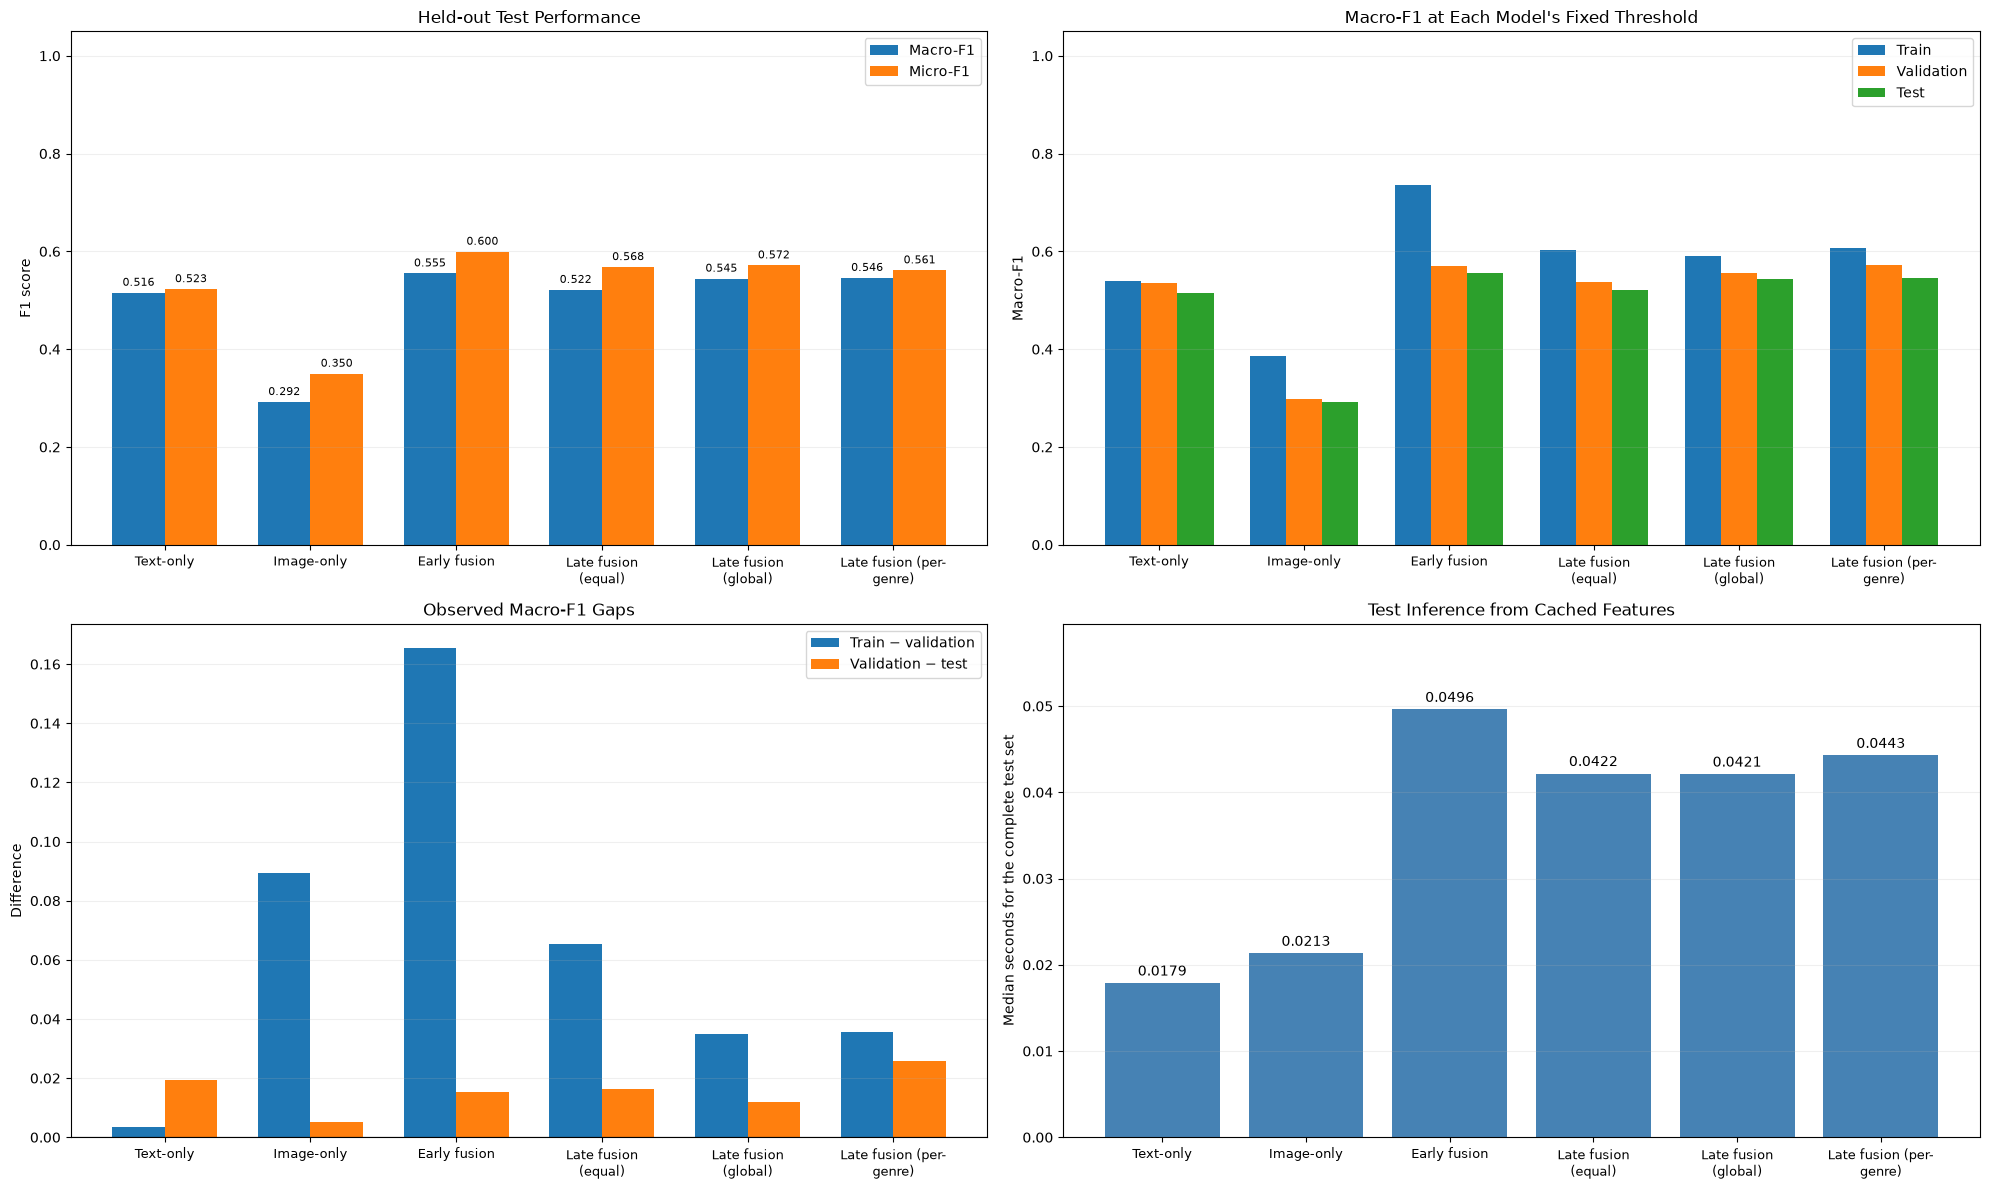

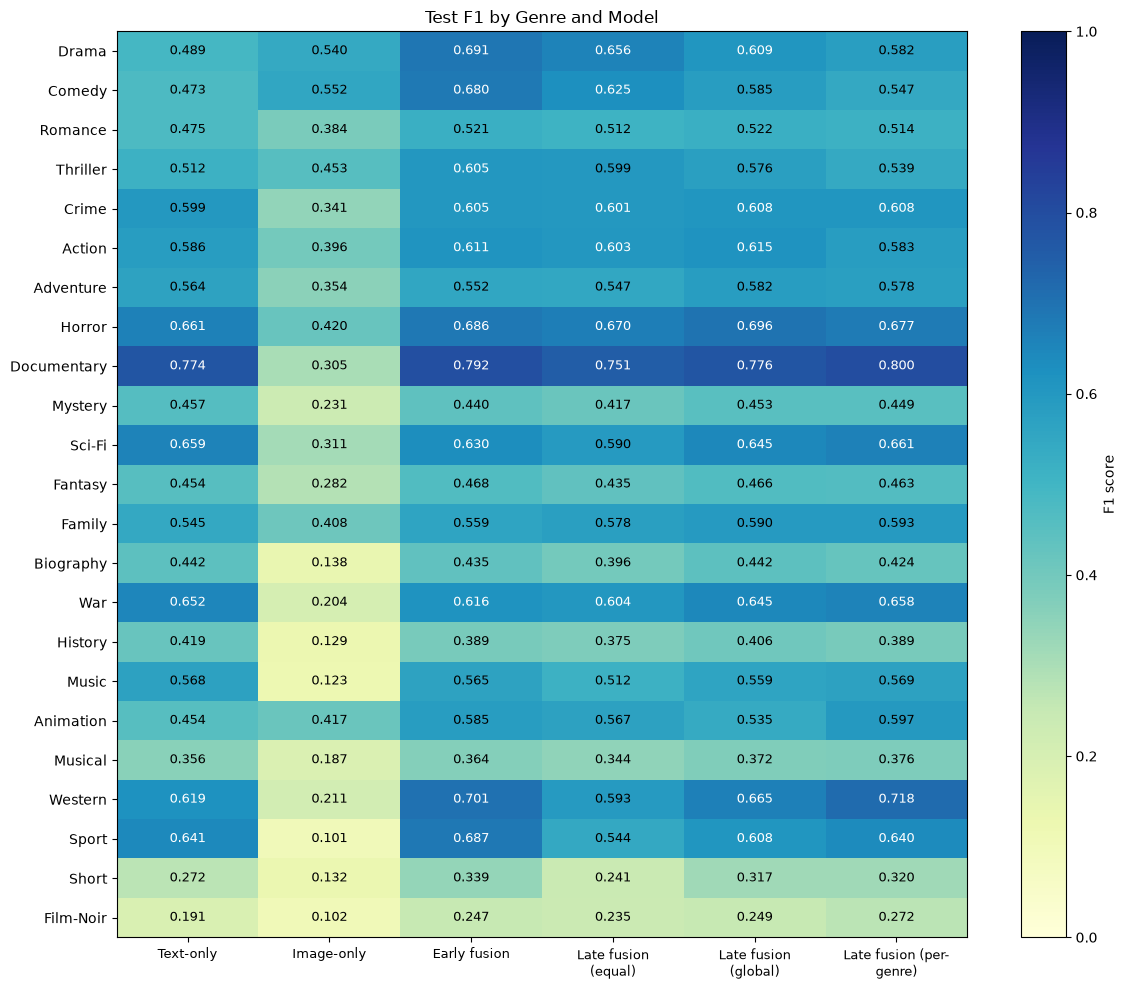


RANDOM INCORRECT TEST PREDICTIONS FROM THE TWO FUSION MODELS


,Model,Record row,Movie ID,True genres,Predicted genres,False positives,False negatives
0,Early fusion,16846,16846,"Drama, Adventure, Documentary","Drama, Documentary, Family",Family,Adventure
1,Early fusion,2281,2281,"Documentary, Music","Documentary, Biography",Biography,Music
2,Early fusion,19923,19923,"Drama, Horror, Biography, War","Drama, Horror, War, History",History,Biography
3,Late fusion (per-genre),2212,2212,"Comedy, Music","Comedy, Romance",Romance,Music
4,Late fusion (per-genre),18130,18130,Drama,None,None,Drama
5,Late fusion (per-genre),22058,22058,Documentary,"Documentary, Biography, History","Biography, History",None


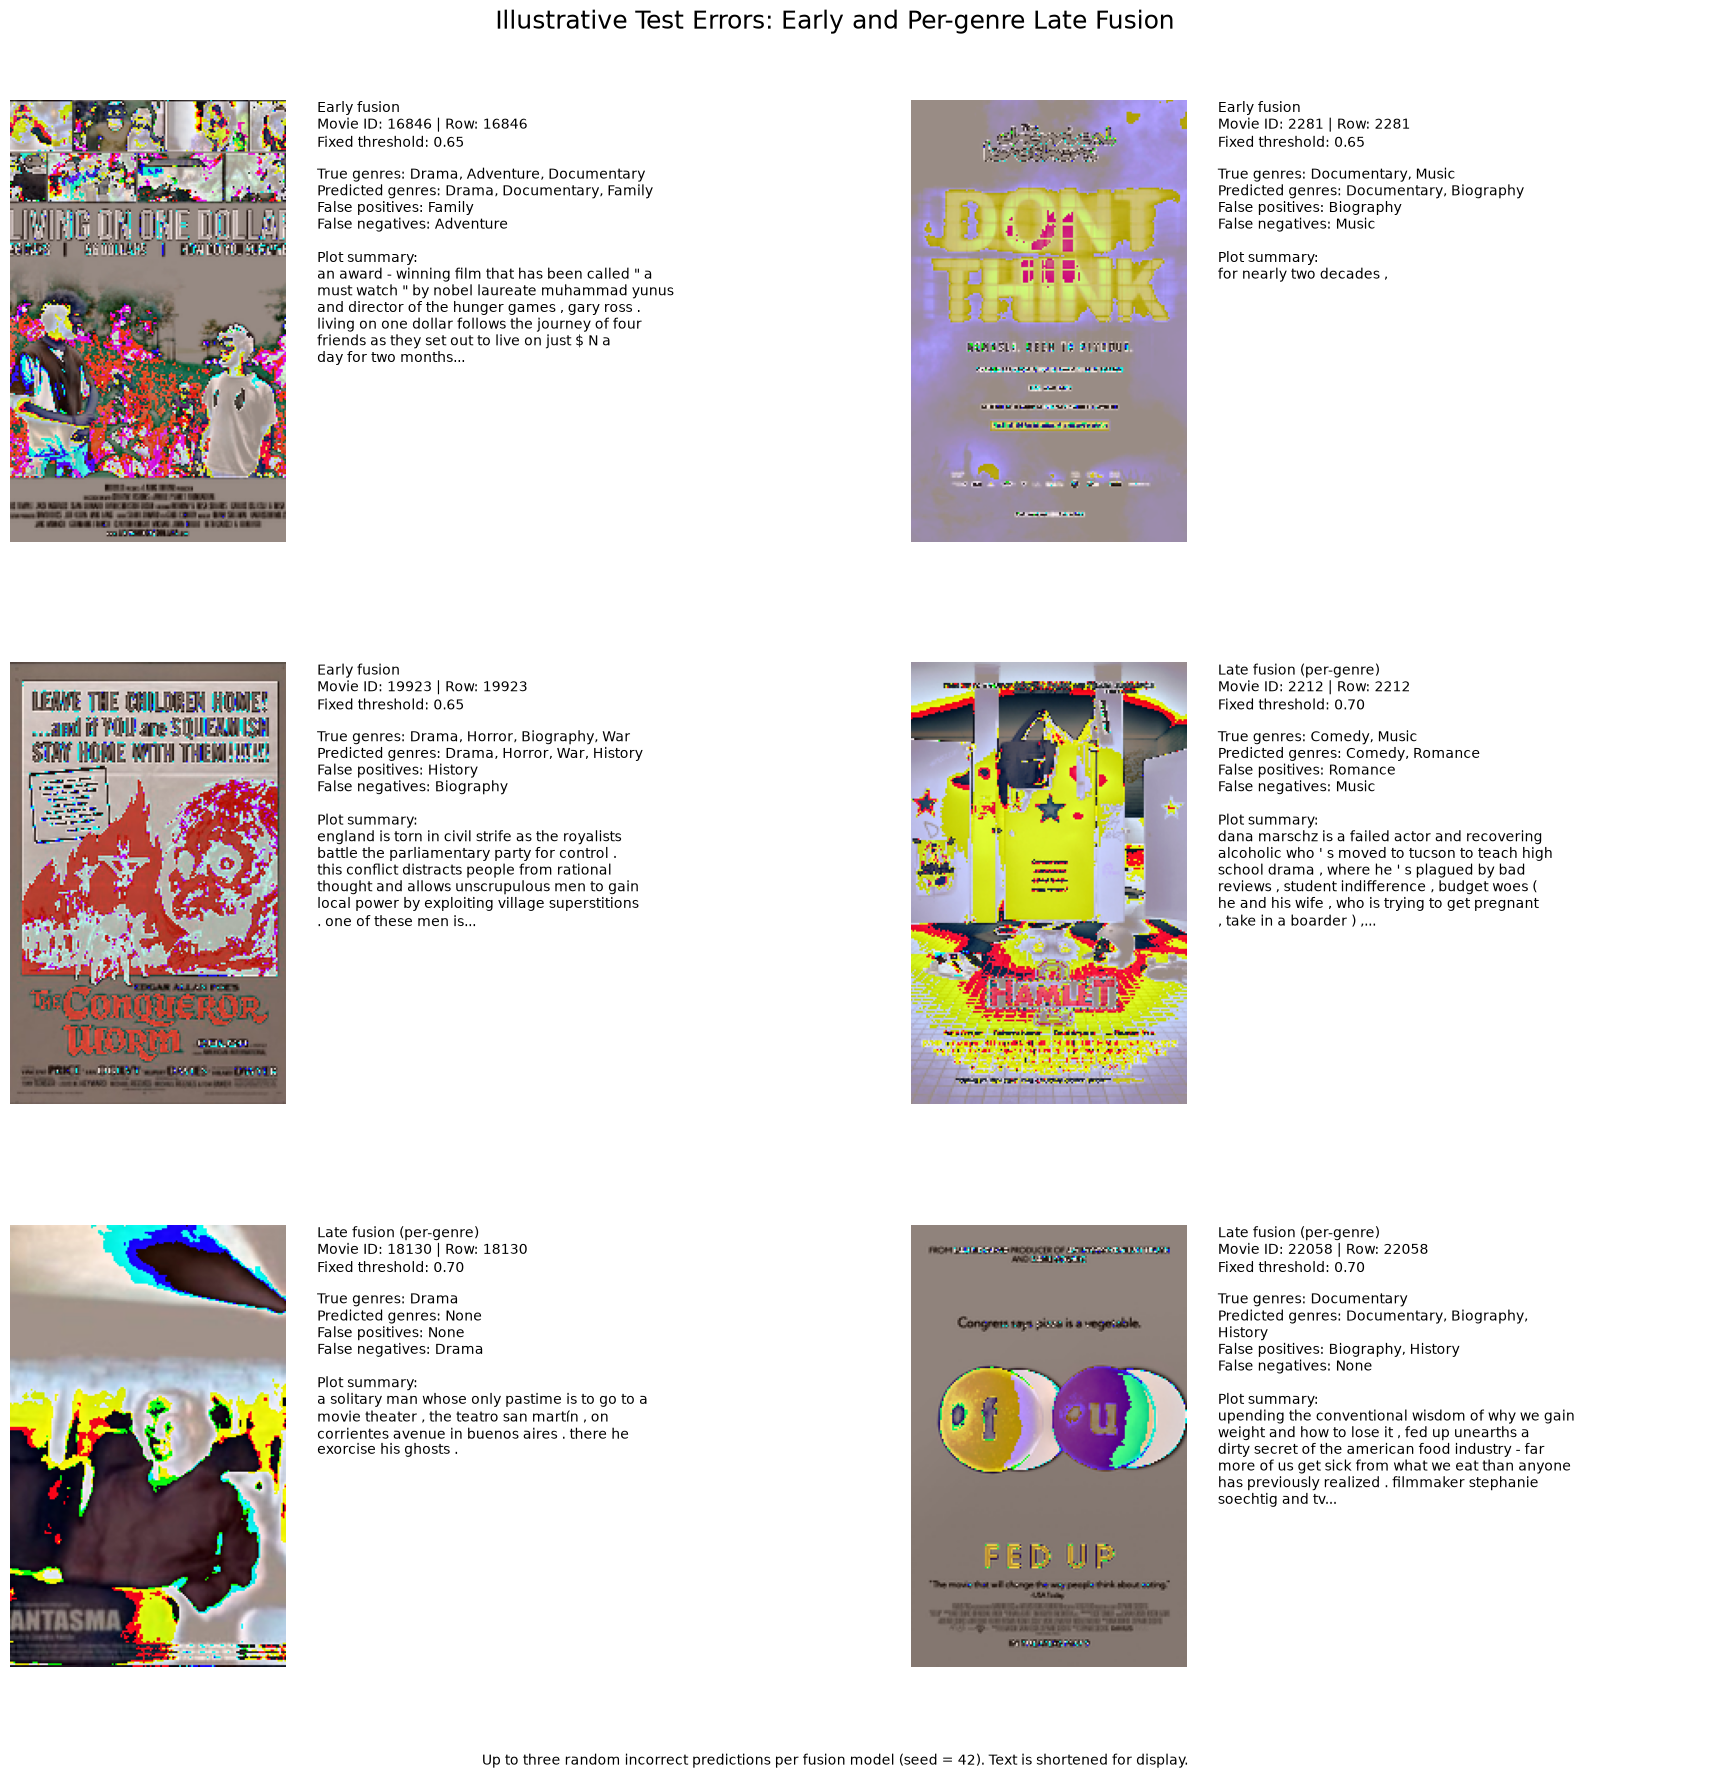


SAVED FINAL EVALUATION RESULTS
 - early_test_predictions.npz
 - equal_test_predictions.npz
 - evaluation_protocol.json
 - final_model_comparison.png
 - global_test_predictions.npz
 - image_test_predictions.npz
 - per_genre_test_predictions.npz
 - selected_error_examples.csv
 - test_error_examples.png
 - test_inference_efficiency.csv
 - test_inference_runs.csv
 - test_movie_errors.csv
 - test_overlap_checks.csv
 - test_per_genre_f1.csv
 - test_per_genre_f1.png
 - test_per_genre_metrics.csv
 - test_results.csv
 - text_test_predictions.npz
Results directory: C:\Users\Lenovo\OneDrive - University of Adelaide\Desktop\SEMESTER 2 2026\Multi-Modal Data Analysis\ASSIGNMENT 5\mmimdb_features\v2_317223387d28dbac\final_evaluation\20261101_143613_591437


In [39]:
from pathlib import Path
from datetime import datetime
from time import perf_counter
import hashlib
import json
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import f1_score, precision_recall_fscore_support
from IPython.display import display
# Reuse the feature cache, split definitions and model classes from earlier parts.
required_variables = [
    "feature_data", "split_indices", "records", "labels", "genres", "images",
    "group_ids", "FEATURE_DIR", "UNIMODAL_DIR", "EARLY_FUSION_DIR",
    "LATE_FUSION_DIR", "UnimodalMLP", "EarlyFusionMLP"
]
missing_variables = [name for name in required_variables if name not in globals()]
if missing_variables:
    raise RuntimeError("Complete Parts 6–11 first. Missing: " + ", ".join(missing_variables))
# Read saved settings; no thresholds or mixing weights are selected using test data.
with (Path(LATE_FUSION_DIR) / "late_fusion_config.json").open(encoding="utf-8") as file:
    final_late_config = json.load(file)
for key, expected in [
    ("feature_directory", FEATURE_DIR), ("baseline_directory", UNIMODAL_DIR),
    ("early_fusion_directory", EARLY_FUSION_DIR)
]:
    if Path(final_late_config[key]).resolve() != Path(expected).resolve():
        raise ValueError(f"Experiment directory mismatch: {key}")
if final_late_config["genres"] != list(genres) or final_late_config["main_variant"] != "per_genre":
    raise ValueError("Genre order or the predefined main late fusion variant has changed.")
final_previous_results = pd.read_csv(
    Path(LATE_FUSION_DIR) / "all_model_validation_comparison.csv"
).set_index("Model")
if not final_previous_results.index.is_unique:
    raise ValueError("Model names in the validation results must be unique.")
# Reconstruct the exact saved classifier heads and disable all parameter updates.
FINAL_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FINAL_BATCH_SIZE = 512
TIMING_REPEATS = 5
TIMING_WARMUPS = 3
ERROR_SEED = 42
final_checkpoint_paths = {
    "text": Path(final_late_config["source_checkpoints"]["text"]),
    "image": Path(final_late_config["source_checkpoints"]["image"]),
    "early": Path(EARLY_FUSION_DIR) / "early_fusion_best.pt"
}
final_models = {}
final_settings = {}
for key, checkpoint_path in final_checkpoint_paths.items():
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    if checkpoint["genres"] != list(genres):
        raise ValueError(f"Checkpoint genre order differs: {key}")
    if Path(checkpoint["feature_directory"]).resolve() != Path(FEATURE_DIR).resolve():
        raise ValueError(f"Checkpoint feature directory differs: {key}")
    if key == "early":
        if checkpoint["fusion_order"] != ["text", "image"]:
            raise ValueError("Early fusion modality order has changed.")
        model = EarlyFusionMLP(
            checkpoint["text_dim"], checkpoint["image_dim"],
            checkpoint["hidden_dim"], checkpoint["output_dim"], checkpoint["dropout"]
        )
        model_name = "Early fusion"
    else:
        model = UnimodalMLP(
            checkpoint["input_dim"], checkpoint["hidden_dim"],
            checkpoint["output_dim"], checkpoint["dropout"]
        )
        model_name = f"{key.title()}-only"
    model.load_state_dict(checkpoint["state_dict"], strict=True)
    final_models[key] = model.to(FINAL_DEVICE).eval().requires_grad_(False)
    final_settings[key] = {"name": model_name, "threshold": float(checkpoint["threshold"])}
for variant in ["equal", "global", "per_genre"]:
    setting = final_late_config["variants"][variant]
    weights = np.asarray(setting["text_weights"], dtype=np.float32)
    if weights.shape != (len(genres),) or not np.isfinite(weights).all():
        raise ValueError(f"Invalid mixing weights: {variant}")
    if np.any((weights < 0) | (weights > 1)):
        raise ValueError(f"Mixing weights outside [0, 1]: {variant}")
    final_settings[variant] = {
        "name": setting["name"], "threshold": float(setting["threshold"]),
        "text_weights": weights.tolist()
    }
for setting in final_settings.values():
    threshold = setting["threshold"]
    if not 0 < threshold < 1 or not np.isclose(
        threshold, final_previous_results.loc[setting["name"], "Threshold"], rtol=0, atol=1e-8
    ):
        raise ValueError("A saved threshold differs from its validation result.")
# Verify test identifiers, labels and separation from the training and validation groups.
final_test_rows = np.asarray(split_indices["test"], dtype=np.int64)
final_test_ids = np.asarray([str(records[i, 0]) for i in final_test_rows])
test_arrays = feature_data["test"]
if not (
    len(final_test_rows) > 0 and len(np.unique(final_test_rows)) == len(final_test_rows)
    and np.array_equal(test_arrays["row_indices"], final_test_rows)
    and np.array_equal(test_arrays["movie_ids"], final_test_ids)
    and np.array_equal(test_arrays["labels"], labels[final_test_rows])
):
    raise ValueError("Test feature rows, movie IDs or labels are misaligned.")
final_test_labels = np.array(test_arrays["labels"], dtype=np.int64, copy=True)
if not np.isin(test_arrays["labels"], [0, 1]).all():
    raise ValueError("Test labels must be binary.")
final_overlap_rows = []
for split_name in ["train", "validation"]:
    other_rows = np.asarray(split_indices[split_name], dtype=np.int64)
    shared_rows = np.intersect1d(final_test_rows, other_rows).size
    shared_groups = np.intersect1d(np.asarray(group_ids)[final_test_rows], np.asarray(group_ids)[other_rows]).size
    if shared_rows or shared_groups:
        raise ValueError(f"Test overlaps with {split_name}.")
    final_overlap_rows.append({"Split pair": f"test / {split_name}", "Shared rows": shared_rows, "Shared groups": shared_groups})
final_features = {}
for modality in ["text", "image"]:
    features = test_arrays[modality]
    if features.shape != (len(final_test_rows), 768) or not np.isfinite(features).all():
        raise ValueError(f"Invalid test features: {modality}")
    # Copy read-only cached features once; batch transfers are included in inference timing.
    final_features[modality] = torch.from_numpy(np.array(features, dtype=np.float32, copy=True))
print("FINAL TEST INPUTS")
display(pd.DataFrame([
    {"Modality": m.title(), "Feature shape": tuple(x.shape), "Label shape": final_test_labels.shape,
     "Rows and labels aligned": True} for m, x in final_features.items()
]))
display(pd.DataFrame(final_overlap_rows))
print("Device:", FINAL_DEVICE, "| CPU threads:", torch.get_num_threads())
print("Test movies:", len(final_test_rows))
# Save the fixed evaluation protocol before calculating any test performance metrics.
FINAL_DIR = Path(FEATURE_DIR) / "final_evaluation" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
FINAL_DIR.mkdir(parents=True, exist_ok=False)
def checkpoint_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()
final_protocol = {
    "feature_directory": str(Path(FEATURE_DIR).resolve()),
    "late_fusion_directory": str(Path(LATE_FUSION_DIR).resolve()),
    "genres": list(genres), "settings": final_settings,
    "source_checkpoints": {k: str(p.resolve()) for k, p in final_checkpoint_paths.items()},
    "checkpoint_sha256": {k: checkpoint_sha256(p) for k, p in final_checkpoint_paths.items()},
    "main_models": ["text", "image", "early", "per_genre"],
    "test_movies": len(final_test_rows), "device": str(FINAL_DEVICE),
    "batch_size": FINAL_BATCH_SIZE, "timing_repeats": TIMING_REPEATS,
    "warmup_batches": TIMING_WARMUPS, "error_sample_seed": ERROR_SEED,
    "torch_version": str(torch.__version__), "cpu_threads": torch.get_num_threads(),
    "timing_scope": "Cached CPU features to CPU sigmoid scores; includes batch transfers and late fusion",
    "selection_policy": "Saved validation-selected checkpoints, thresholds and weights; no test tuning"
}
with (FINAL_DIR / "evaluation_protocol.json").open("w", encoding="utf-8") as file:
    json.dump(final_protocol, file, indent=2)
display(pd.DataFrame([
    {"Model": s["name"], "Fixed threshold": s["threshold"]} for s in final_settings.values()
]))
# Generate independent sigmoid scores; no softmax or forced single-label prediction is used.
final_weight_tensors = {
    k: torch.tensor(s["text_weights"], dtype=torch.float32, device=FINAL_DEVICE)
    for k, s in final_settings.items() if "text_weights" in s
}
@torch.inference_mode()
def predict_final_scores(key, limit=None):
    count = len(final_test_rows) if limit is None else min(limit, len(final_test_rows))
    scores = np.empty((count, len(genres)), dtype=np.float32)
    for start in range(0, count, FINAL_BATCH_SIZE):
        stop = min(start + FINAL_BATCH_SIZE, count)
        if key != "image":
            text_batch = final_features["text"][start:stop].to(FINAL_DEVICE)
        if key != "text":
            image_batch = final_features["image"][start:stop].to(FINAL_DEVICE)
        if key == "text":
            batch_scores = torch.sigmoid(final_models["text"](text_batch))
        elif key == "image":
            batch_scores = torch.sigmoid(final_models["image"](image_batch))
        elif key == "early":
            batch_scores = torch.sigmoid(final_models["early"](text_batch, image_batch))
        else:
            alpha = final_weight_tensors[key]
            text_scores = torch.sigmoid(final_models["text"](text_batch))
            image_scores = torch.sigmoid(final_models["image"](image_batch))
            batch_scores = alpha * text_scores + (1.0 - alpha) * image_scores
        scores[start:stop] = batch_scores.cpu().numpy()
    return scores
def synchronise_final_device():
    if FINAL_DEVICE.type == "cuda":
        torch.cuda.synchronize(FINAL_DEVICE)
# Repeated passes measure runtime only; labels do not enter the inference function.
final_probabilities = {}
final_timing_rows = []
final_timing_runs = []
for key, setting in final_settings.items():
    for _ in range(TIMING_WARMUPS):
        predict_final_scores(key, limit=FINAL_BATCH_SIZE)
    durations = []
    for run in range(TIMING_REPEATS):
        synchronise_final_device()
        started = perf_counter()
        probabilities = predict_final_scores(key)
        synchronise_final_device()
        elapsed = perf_counter() - started
        durations.append(elapsed)
        final_timing_runs.append({"Model": setting["name"], "Run": run + 1, "Seconds": elapsed})
        if run == 0:
            final_probabilities[key] = probabilities
    retained_scores = final_probabilities[key]
    if not np.isfinite(retained_scores).all() or np.any((retained_scores < 0) | (retained_scores > 1)):
        raise ValueError(f"Invalid test prediction scores: {key}")
    used_models = [key] if key in final_models else ["text", "image"]
    final_timing_rows.append({
        "Model": setting["name"], "Classifier parameters": sum(
            p.numel() for model_key in used_models for p in final_models[model_key].parameters()
        ), "Mean test inference (s)": np.mean(durations), "Std time (s)": np.std(durations),
        "Median test inference (s)": np.median(durations),
        "Throughput (movies/s)": len(final_test_rows) / np.median(durations),
        "Amortised time (ms/movie)": 1000 * np.median(durations) / len(final_test_rows)
    })
    print(f"{setting['name']}: {probabilities.shape}; median test inference = {np.median(durations):.4f} s", flush=True)
final_efficiency_df = pd.DataFrame(final_timing_rows)
print("\nCOMPUTATIONAL EFFICIENCY FROM CACHED FEATURES")
display(final_efficiency_df.round(4))
print("Each late fusion timing includes both classifier heads and score mixing.")
print("Timing excludes encoder extraction, model loading, metrics and file saving.")
print("Amortised batch time per movie is not single-request latency.")
# Evaluate all methods at their saved thresholds; retain all 23 genres in Macro-F1.
final_test_predictions = {}
final_metric_rows = []
final_genre_frames = []
final_movie_frames = []
actual = final_test_labels.astype(bool)
for key, setting in final_settings.items():
    probabilities = final_probabilities[key]
    predicted = probabilities >= setting["threshold"]
    final_test_predictions[key] = predicted
    precision, recall, genre_f1, support = precision_recall_fscore_support(
        final_test_labels, predicted, average=None, zero_division=0
    )
    false_positive = ~actual & predicted
    false_negative = actual & ~predicted
    previous = final_previous_results.loc[setting["name"]]
    final_metric_rows.append({
        "Model": setting["name"], "Threshold": setting["threshold"],
        "Train Macro-F1": previous["Train Macro-F1"], "Val Macro-F1": previous["Val Macro-F1"],
        "Test Macro-F1": float(genre_f1.mean()),
        "Test Micro-F1": f1_score(final_test_labels, predicted, average="micro", zero_division=0),
        "Train-val Macro-F1 gap": previous["Train Macro-F1"] - previous["Val Macro-F1"],
        "Val-test Macro-F1 gap": previous["Val Macro-F1"] - genre_f1.mean(),
        "Exact match (%)": 100 * np.all(actual == predicted, axis=1).mean(),
        "Hamming loss": np.not_equal(actual, predicted).mean(),
        "No predicted genres": int((predicted.sum(axis=1) == 0).sum())
    })
    final_genre_frames.append(pd.DataFrame({
        "Model": setting["name"], "Genre": genres, "Support": support,
        "Precision": precision, "Recall": recall, "F1": genre_f1,
        "True positives": (actual & predicted).sum(axis=0),
        "False positives": false_positive.sum(axis=0), "False negatives": false_negative.sum(axis=0)
    }))
    final_movie_frames.append(pd.DataFrame({
        "Model": setting["name"], "Test position": np.arange(len(final_test_rows)),
        "Record row": final_test_rows, "Movie ID": final_test_ids,
        "True genre count": actual.sum(axis=1), "Predicted genre count": predicted.sum(axis=1),
        "False positives": false_positive.sum(axis=1), "False negatives": false_negative.sum(axis=1),
        "Incorrect labels": np.not_equal(actual, predicted).sum(axis=1)
    }))
    np.savez_compressed(
        FINAL_DIR / f"{key}_test_predictions.npz", probabilities=probabilities,
        predictions=predicted.astype(np.uint8), labels=final_test_labels,
        row_indices=final_test_rows, movie_ids=final_test_ids
    )
final_comparison_df = pd.DataFrame(final_metric_rows)
final_per_genre_df = pd.concat(final_genre_frames, ignore_index=True)
final_movie_errors_df = pd.concat(final_movie_frames, ignore_index=True)
best_test_baseline = final_comparison_df.loc[
    final_comparison_df["Model"].isin(["Text-only", "Image-only"]), "Test Macro-F1"
].max()
final_comparison_df["Test Macro-F1 difference vs best baseline"] = final_comparison_df["Test Macro-F1"] - best_test_baseline
print("\nFINAL TEST COMPARISON")
display(final_comparison_df.round(4))
print("All thresholds were fixed using validation data. Undefined per-genre metrics are reported as zero.")
print("The train–validation gap is descriptive; validation was used for model selection.")
final_genre_f1_df = final_per_genre_df.pivot(index="Genre", columns="Model", values="F1").reindex(
    index=genres, columns=final_comparison_df["Model"].tolist()
)
print("\nTEST F1 BY GENRE")
display(final_genre_f1_df.assign(Support=actual.sum(axis=0)).round(4))
for model_name in ["Early fusion", "Late fusion (per-genre)"]:
    print(f"\nPER-GENRE ERROR ANALYSIS: {model_name}")
    display(final_per_genre_df.loc[final_per_genre_df["Model"] == model_name].drop(columns="Model").round(4))
# Plot overall performance, generalisation gaps and inference time using fixed model order.
model_labels = [textwrap.fill(name, 17) for name in final_comparison_df["Model"]]
positions = np.arange(len(model_labels))
fig, axes = plt.subplots(2, 2, figsize=(20, 12))
for offset, column, label in [(-0.18, "Test Macro-F1", "Macro-F1"), (0.18, "Test Micro-F1", "Micro-F1")]:
    bars = axes[0, 0].bar(positions + offset, final_comparison_df[column], width=0.36, label=label)
    axes[0, 0].bar_label(bars, fmt="%.3f", padding=3, fontsize=8)
axes[0, 0].set(title="Held-out Test Performance", ylabel="F1 score", ylim=(0, 1.05))
axes[0, 0].legend()
for offset, column, label in [(-0.25, "Train Macro-F1", "Train"), (0, "Val Macro-F1", "Validation"), (0.25, "Test Macro-F1", "Test")]:
    axes[0, 1].bar(positions + offset, final_comparison_df[column], width=0.25, label=label)
axes[0, 1].set(title="Macro-F1 at Each Model's Fixed Threshold", ylabel="Macro-F1", ylim=(0, 1.05))
axes[0, 1].legend()
for offset, column, label in [(-0.18, "Train-val Macro-F1 gap", "Train − validation"), (0.18, "Val-test Macro-F1 gap", "Validation − test")]:
    axes[1, 0].bar(positions + offset, final_comparison_df[column], width=0.36, label=label)
axes[1, 0].axhline(0, color="black", linewidth=0.8)
axes[1, 0].set(title="Observed Macro-F1 Gaps", ylabel="Difference")
axes[1, 0].legend()
bars = axes[1, 1].bar(positions, final_efficiency_df["Median test inference (s)"], color="steelblue")
axes[1, 1].bar_label(bars, fmt="%.4f", padding=3)
axes[1, 1].set(title="Test Inference from Cached Features", ylabel="Median seconds for the complete test set")
axes[1, 1].margins(y=0.2)
for ax in axes.flat:
    ax.set_xticks(positions, model_labels, fontsize=9)
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(FINAL_DIR / "final_model_comparison.png", dpi=180, bbox_inches="tight")
plt.show()
# Use the established genre order rather than assigning each movie a single class.
fig, ax = plt.subplots(figsize=(12, 10))
heat = ax.imshow(final_genre_f1_df.to_numpy(), aspect="auto", vmin=0, vmax=1, cmap="YlGnBu")
ax.set_xticks(positions, model_labels, fontsize=9)
ax.set_yticks(np.arange(len(genres)), genres)
for row in range(len(genres)):
    for column in range(len(model_labels)):
        value = final_genre_f1_df.iloc[row, column]
        ax.text(column, row, f"{value:.3f}", ha="center", va="center", color="white" if value > 0.6 else "black", fontsize=9)
ax.set_title("Test F1 by Genre and Model")
fig.colorbar(heat, ax=ax, label="F1 score")
fig.tight_layout()
fig.savefig(FINAL_DIR / "test_per_genre_f1.png", dpi=180, bbox_inches="tight")
plt.show()
# Inspect both fusion models, fixed in advance, rather than choosing a model from test performance.
def genre_names(mask):
    return ", ".join(name for name, active in zip(genres, mask) if active) or "None"
error_rng = np.random.default_rng(ERROR_SEED)
selected_errors = []
error_example_rows = []
for key in ["early", "per_genre"]:
    predicted = final_test_predictions[key]
    error_positions = np.flatnonzero(np.any(predicted != actual, axis=1))
    chosen = error_rng.choice(error_positions, size=min(3, len(error_positions)), replace=False)
    for position in chosen:
        row = int(final_test_rows[position])
        selected_errors.append((key, int(position)))
        error_example_rows.append({
            "Model": final_settings[key]["name"], "Record row": row, "Movie ID": str(records[row, 0]),
            "True genres": genre_names(actual[position]), "Predicted genres": genre_names(predicted[position]),
            "False positives": genre_names(~actual[position] & predicted[position]),
            "False negatives": genre_names(actual[position] & ~predicted[position]),
            "Plot summary": str(records[row, 2])
        })
final_error_examples_df = pd.DataFrame(error_example_rows)
print("\nRANDOM INCORRECT TEST PREDICTIONS FROM THE TWO FUSION MODELS")
if selected_errors:
    display(final_error_examples_df.drop(columns="Plot summary"))
    fig = plt.figure(figsize=(22, 6 * int(np.ceil(len(selected_errors) / 2))))
    grid = fig.add_gridspec(int(np.ceil(len(selected_errors) / 2)), 2, hspace=0.18, wspace=0.12)
    for card_index, (key, position) in enumerate(selected_errors):
        example = error_example_rows[card_index]
        card = grid[card_index // 2, card_index % 2].subgridspec(1, 2, width_ratios=[1, 1.8], wspace=0.08)
        ax_image = fig.add_subplot(card[0, 0])
        ax_text = fig.add_subplot(card[0, 1])
        ax_image.imshow(np.moveaxis(images[example["Record row"]], 0, -1))
        ax_image.set_anchor("N")
        ax_image.axis("off")
        ax_text.axis("off")
        lines = [example["Model"], f"Movie ID: {example['Movie ID']} | Row: {example['Record row']}",
                 f"Fixed threshold: {final_settings[key]['threshold']:.2f}", ""]
        for field in ["True genres", "Predicted genres", "False positives", "False negatives"]:
            lines.append(textwrap.fill(field + ": " + textwrap.shorten(example[field], width=130, placeholder="..."), width=48))
        lines.extend(["", "Plot summary:", textwrap.fill(textwrap.shorten(
            " ".join(example["Plot summary"].split()), width=260, placeholder="..."
        ), width=48)])
        ax_text.text(0, 1, "\n".join(lines), transform=ax_text.transAxes, va="top", fontsize=10, linespacing=1.2)
    fig.suptitle("Illustrative Test Errors: Early and Per-genre Late Fusion", fontsize=18, y=0.99)
    fig.subplots_adjust(top=0.94, bottom=0.05)
    fig.text(0.5, 0.015, "Up to three random incorrect predictions per fusion model (seed = 42). Text is shortened for display.", ha="center", fontsize=10)
    fig.savefig(FINAL_DIR / "test_error_examples.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("No incorrect predictions were found for either fusion model.")
# Retain complete tables, scores and identifiers for reporting and reproducibility.
final_comparison_df.to_csv(FINAL_DIR / "test_results.csv", index=False)
final_per_genre_df.to_csv(FINAL_DIR / "test_per_genre_metrics.csv", index=False)
final_genre_f1_df.to_csv(FINAL_DIR / "test_per_genre_f1.csv")
final_efficiency_df.to_csv(FINAL_DIR / "test_inference_efficiency.csv", index=False)
pd.DataFrame(final_timing_runs).to_csv(FINAL_DIR / "test_inference_runs.csv", index=False)
pd.DataFrame(final_overlap_rows).to_csv(FINAL_DIR / "test_overlap_checks.csv", index=False)
final_movie_errors_df.to_csv(FINAL_DIR / "test_movie_errors.csv", index=False)
final_error_examples_df.to_csv(FINAL_DIR / "selected_error_examples.csv", index=False)
print("\nSAVED FINAL EVALUATION RESULTS")
for path in sorted(FINAL_DIR.iterdir()):
    print(" -", path.name)
print("Results directory:", FINAL_DIR)

Final evaluation used 7,783 test movies with aligned text and image features, with no shared rows or constructed groups between the test and development splits. All decision thresholds were fixed using validation data before testing. Early fusion achieved the highest observed test Macro-F1 of 0.5552 and Micro-F1 of 0.5995, exceeding the text-only Macro-F1 of 0.5156 by 0.0396. The image-only baseline achieved a Macro-F1 of 0.2922 and Micro-F1 of 0.3501. Equal-weight, global-weight and per-genre late fusion achieved Macro-F1 scores of 0.5215, 0.5445 and 0.5460, with corresponding Micro-F1 scores of 0.5681, 0.5716 and 0.5614. Early fusion also achieved the highest exact-match rate of 12.6558%, while per-genre late fusion recorded the lowest Hamming loss of 0.0914. Although early fusion had the largest train–validation Macro-F1 gap of 0.1654, its validation–test gap was 0.0154. Per-genre late fusion had a smaller train–validation gap of 0.0355 but a larger validation–test gap of 0.0257, and its validation advantage did not translate into the highest test F1. Performance varied substantially across genres: Documentary F1 reached 0.7925 for early fusion and 0.8003 for per-genre late fusion, whereas Film-Noir F1 was 0.2473 and 0.2724, respectively, across 95 positive test examples. Early fusion produced 153 false positives and 60 false negatives for Film-Noir. Selected error examples included predicting Biography instead of Music and failing to assign any genre to a Drama movie. Overall, early fusion assigned no genres to 148 movies, compared with 572 for per-genre late fusion. Median inference times for the complete test set were 0.0179 seconds for text-only, 0.0213 for image-only, 0.0496 for early fusion, and 0.0422, 0.0421 and 0.0443 for the three late fusion variants, respectively. These measurements used cached features and excluded encoder extraction, model loading, metric calculation and file saving. Predictions, evaluation tables, timing measurements and error-analysis figures were saved.